# 10 — Evaluación final en el test de `sin_camara`

**Plan de notebooks, uno por número.** El 07 justifica el target; el 08 analiza los datos; el 09 modela; **el 10 (este) evalúa en el test y cierra**.

**Qué hacemos acá.** Se aplica **tal como está** el plan de evaluación congelado v2 (`docs/plan_evaluacion_test.md`) a los 8 segmentos de test: modelos, umbrales, calibrador, poblaciones, métricas y criterios ya fijados con train. **Este es el primer notebook que abre el test.**

**Reglas.** El notebook se ejecuta de arriba a abajo una vez. No se cambia el plan, ni los modelos, ni los umbrales, ni los criterios, ni las métricas, mire lo que mire en el test; cualquier desviación se documenta acá con su motivo. Todas las cifras salen de código y las conclusiones son f-strings.

**Entradas:** `test.parquet` (primera apertura), `plan_evaluacion_test.json` (v2), los modelos y archivos congelados de `data/06_models/`, `features_B.parquet` (solo para el sha256) y las referencias de train del plan.
**Salidas:** `images/10_*.png`, `data/08_reporting/10_*.csv`, `data/07_model_output/pred_test_B.parquet`, `docs/evaluacion_final_B.md`.

<a id="resumen"></a>
## Resumen ejecutivo

*(Texto generado por la celda "Resumen ejecutivo generado" en la ejecución 6 (la última); se copia acá para leerlo arriba.)*

### Resumen ejecutivo (generado por código)

- **Resultado principal (pre-declarado, población principal, 16.062 filas, 8 segmentos de test):** Regresion logistica tiene AUC 0,698 (IC 0,503 a 0,961) y Fracción para 80 % 77,4 %; Regla: menos puntos top, 0,684 y 79,0 %. Diferencia de AUC +0,014 (IC -0,014 a +0,029); de Fracción para 80 % -1,7 puntos (IC -4,2 a +4,1). **"Vale la pena": no se cumple**; el modelo no se distingue del baseline.
- **Puntos de operación (umbrales congelados):** A de Regresion logistica: recall 0,621 (IC 0,413 a 0,958), precisión 0,406, 35,6 % a revisar; **no se sostiene** (recall ≥ 0,75). B: recall 0,447 con 15,1 % revisado.
- **Influencia (12 cálculos):** diferencia de AUC de -0,004 a +0,020; de Fracción para 80 % de -2,4 a +1,3 puntos. Ningún segmento por sí solo cambia el veredicto.
- **Sensibilidad a 120°:** robusto (lectura literal del plan): ningún modelo; con baselines de train: ningún modelo.
- **Calibración en test (Regresion logistica):** ECE 0,079 crudo y 0,080 con Platt congelado.
- **Equidad descriptiva (recall al punto A de Regla: menos puntos top, sección G):** momento del día: Day 0,495 (6 seg., 10.558 filas) frente a Dawn/Dusk 1,000 (1 seg., 851 filas); ubicación: location_sf 0,515 (3 seg., 11.978 filas) frente a location_other 0,946 (2 seg., 1.850 filas); clase: PEDESTRIAN 0,590 (8 seg., 15.730 filas) frente a CYCLIST 0,667 (2 seg., 332 filas). Con un solo segmento: Dawn/Dusk, Night.
- **Test frente a train:** orden por AUC distinto (hallazgo, sin reajustar).
- **Recomendación (interpretación):** Regla: menos puntos top. **Matices (no cambian la recomendación formal).** El punto A de Regla: menos puntos top no se sostiene en test: recall 0,590 (IC 0,383 a 0,924) frente a la meta de 0,80 y la tolerancia de 0,75. El recall depende fuertemente de un segmento: en el segmento con más positivos (257766998801, 55 % de los positivos) el recall es 0,351 y sin él pasa de 0,590 a 0,879; entre los 4 segmentos con al menos 50 positivos, 3 alcanzan la tolerancia (recall de 0,351 a 0,945). Por eso se sugiere usarlo para priorizar la revisión humana, junto con un monitoreo del recall por segmento, y no como reemplazo de la revisión. (Detalle y diagnóstico post hoc en la sección L.)

### Diagnóstico post hoc, no pre-declarado (sección L; no cambia la recomendación formal)

- El segmento `257766998801` tiene 6.474 filas y 2.046 positivos (54,8 % de los positivos de test); su tasa de `sin_camara` es 31,6 % (otros 7: 17,6 %; train: 20,7 %).
- AUC dentro del segmento: regla por puntos top 0,443 y regresión logística 0,459.
- Cajas sin par con ≥ 100 puntos: 45,7 % en el segmento, 0,1 % en los otros 7 y 4,4 % en train.
- Segmentos de train con AUC de la regla top < 0,55: 2 de 33 (1 con al menos 50 positivos).
- Sin el segmento (7 segmentos): AUC 0,927 (Regresion logistica) y 0,931 (Regla: menos puntos top); 'vale la pena' no se cumple; punto A de Regresion logistica: recall 0,913; 7 de 7 métodos sostienen el punto A (oficial: 0).
- Recall del punto A de Regla: menos puntos top de día (L.7): 0,495 oficial y 0,903 sin el segmento; en San Francisco 0,515 y 0,861.
- **Hipótesis (post hoc, no pre-declarada).** Condición (i): las cajas sin par con al menos 100 puntos son 936 de 2.046 (45,7 %) en el foco frente a 1 de 1.688 (0,1 %) en los otros 7: se cumple. Condición (ii): AUC de la regla por puntos top dentro del segmento 0,443: se cumple. En las cámaras (regla de L.2), la cámara 3 (frontal der.) no tiene ningún par en el segmento (0 de 6.474 cajas del segmento; 2.090 cajas caen dentro de su rango de azimut). La causa puede ser etiquetado 2D faltante o ausencia de datos de esa cámara; con estos archivos no se distinguen. Ambas condiciones se cumplen: una parte importante de las cajas sin par del segmento son objetos bien observados, lo que **sugiere que el problema de este segmento no es la falta de observabilidad LiDAR sino la ausencia de pares en la cámara 3 (frontal der.); si la causa es etiquetado 2D faltante o ausencia de datos de esa cámara no se distingue con estos archivos**. Implicación para el uso de la regla: la regla por puntos sirve mientras la relación entre pocos puntos y ausencia de par 2D se mantenga; **no detecta huecos sistemáticos de etiquetado**, porque esos objetos están bien observados y la regla los ordena como si tuvieran par. Por eso conviene monitorear el recall por segmento. Sin el segmento, el resultado principal sigue sin cumplir 'vale la pena' y 7 de 7 métodos sostienen el punto A (oficial: 0); eso describe cuánto depende el resultado de un solo segmento y no reemplaza el resultado pre-declarado.

### Diagnóstico post hoc M, no pre-declarado (auditoría por cámara en 41 segmentos; no cambia la recomendación formal)

- 2 de 41 segmentos tienen alguna cámara con hueco (1 de train, 1 de test), en 2 pares (segmento, cámara).
- Positivos de la población principal en celdas con hueco: 1,7 % en train y 35,8 % en test.
- Tabla 2x2 exploratoria (hueco frente a AUC de la regla top < 0,55, segmentos con al menos 50 positivos, n = 26): p de Fisher = 0,003 (exploratorio).
- **Hipótesis (post hoc, no pre-declarada).** Con los criterios fijados antes de calcular, **2 de 41 segmentos (5 %) tienen al menos una cámara con hueco** (1 de 33 de train y 1 de 8 de test), en 2 pares (segmento, cámara). Esas celdas reúnen el 1,7 % de los positivos de train y el 35,8 % de los de test de la población principal; es decir, 9,2 % del total de cajas sin par (1.565 de 17.102) se atribuye a unos pocos huecos de cámara y no a la falta de puntos. El segmento de train 911012534050 tiene hueco en 5 (lateral der.). En la tabla 2x2 exploratoria (p de Fisher = 0,003, n = 26), 2 de 2 segmentos con hueco tienen AUC < 0,55, frente a 0 de 24 sin hueco. **Implicación (hipótesis):** una auditoría por segmento y cámara (tasa de pares de cada cámara dentro de su rango de azimut) detecta lo que la regla por puntos no detecta: los huecos afectan a objetos bien observados, que la regla ordena como si tuvieran par. **Aclaración:** un 'hueco' puede ser de etiquetado o de los datos de esa cámara (por ejemplo, una cámara sin imágenes o sin etiquetas 2D en el segmento); con estos archivos no se puede distinguir. Los rangos de azimut son empíricos (de train), no calibración, y los criterios son los fijados antes de calcular. No cambia la recomendación formal ni el resultado pre-declarado.


## Lecturas tomadas (decisiones sin consulta)

1. **"Robusto" (sección H).** El plan define robusto como "vale la pena en la población principal y en la de sensibilidad, cada una frente al mejor baseline simple de esa población". Como el v2 sacó el mejor baseline del test del criterio principal, se reportan **dos lecturas**: (a) la literal del plan (mejor baseline simple de cada población en el test) y (b) con los baselines elegidos en train (regla por puntos top en la principal y regla geométrica en la de 120°, la elegida en el 09). Se señala si difieren.
2. **Caso del plan que se aplica a la conclusión principal:** `algun_modelo_supera` si el modelo cumple el criterio "vale la pena" y `ningun_modelo_supera_al_mejor_baseline` si no; si además los IC de ΔAUC y Δ Fracción para 80 % incluyen 0, se escribe "no se distingue", como pide el plan.
3. **"La conclusión cambia" (sección F):** se compara el veredicto "vale la pena" de cada variante (excluyendo segmentos) con el de todos los segmentos, con IC por bootstrap de los segmentos que quedan.
4. **Segmentos evaluables:** los que tienen ≥ 50 positivos en la población principal (según los datos del test, contrastados con la lista del plan).
5. **Horas:** ilustración con 20 s por revisión (supuesto del 09), calculada como en el 09: el baseline necesitaría la fracción de su propia curva de captura para el mismo recall.
6. **Recomendaciones de negocio (sección J):** son interpretación, rotuladas como tales; la regla que las genera está escrita en la propia celda.

In [1]:
from pathlib import Path
import hashlib
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

ENSAYO = False        # True solo en el ensayo del codigo con datos de TRAIN (copia fuera de notebooks/); en la ejecucion real es False
SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
try:
    RAIZ = Path(context.project_path)
except NameError:
    RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists()), Path("C:/Users/maico/waymo-evaluacion"))
RUTA_IN, RUTA_MOD, RUTA_REP, RUTA_OUT, RUTA_IMG, RUTA_DOCS = (RAIZ / "data" / "05_model_input", RAIZ / "data" / "06_models", RAIZ / "data" / "08_reporting", RAIZ / "data" / "07_model_output", RAIZ / "images", RAIZ / "docs")
RUTA_IMG.mkdir(exist_ok=True)
T0 = time.time()
RES, TABLAS = {}, {}
AZUL, NARANJA, GRIS, VERDE, ROJO = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e", "#c0392b"


def guardar_fig(fig, nombre):
    if not ENSAYO:
        fig.savefig(RUTA_IMG / f"{nombre}.png", dpi=150, bbox_inches="tight")


def guardar_csv(df, nombre, indice=True):
    if not ENSAYO:
        df.to_csv(RUTA_REP / f"{nombre}.csv", index=indice)


def pct(x, d=1):
    return f"{x * 100:.{d}f} %".replace(".", ",")


def n3(x, signo=False):
    return (f"{x:+.3f}" if signo else f"{x:.3f}").replace(".", ",")


def pts(x):
    return f"{x:+.1f}".replace(".", ",")


def miles(x):
    return f"{int(x):,}".replace(",", ".")


def md_tabla(df, indice=True):
    d = df.reset_index() if indice else df
    esc = lambda x: str(x).replace("|", chr(92) + "|")
    cab = "| " + " | ".join(esc(c) for c in d.columns) + " |\n|" + "---|" * len(d.columns) + "\n"
    return cab + "\n".join("| " + " | ".join(esc(v) for v in fila) + " |" for fila in d.values)


def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


N_REGLA, N_TOP, N_GEOM, N_MIN = "Regla: menos puntos LiDAR", "Regla: menos puntos top", "Regla geometrica (azimut > 105 primero)", "Modelo minimo (LR 3 variables)"
N_LR, N_HGB, N_RF = "Regresion logistica", "HGB", "Random Forest"
METODOS = [N_REGLA, N_TOP, N_GEOM, N_MIN, N_LR, N_HGB, N_RF]
SIMPLES = [N_REGLA, N_GEOM, N_MIN, N_TOP]               # el orden fija los desempates (igual que en el 09)
VRU = ["PEDESTRIAN", "CYCLIST"]
MET = ["AUC", "PR-AUC", "Captura@20%", "Fraccion para 80%"]
if ENSAYO:
    print("*** ENSAYO DEL CODIGO CON DATOS DE TRAIN (no es la evaluacion) ***")

# A. Verificaciones antes de usar el test

**Por qué importa.** La evaluación solo vale si lo que se evalúa es exactamente lo que se congeló. Antes de abrir el test se comprueba que los archivos no cambiaron, y al abrirlo que los segmentos, filas y positivos coinciden con la tabla de conteos del plan. Si algo no coincide, el notebook se detiene.

In [2]:
PLAN = json.loads((RUTA_MOD / "plan_evaluacion_test.json").read_text(encoding="utf-8"))
assert PLAN["version"] == "v2", "el plan no es la v2"
print(f"Plan {PLAN['version']} congelado el {PLAN['congelado']}")

# ---- 1) sha256 de todo lo congelado
archivos = PLAN["sha256"]["archivos"]
ruta_de = lambda n: (RUTA_IN if n == "config_features_B.json" else RUTA_MOD) / n
chequeo = pd.DataFrame({"esperado": pd.Series(archivos), "actual": pd.Series({n: sha(ruta_de(n)) for n in archivos})})
chequeo.loc["features_B.parquet"] = [PLAN["sha256"]["features_B.parquet"], sha(RUTA_IN / "features_B.parquet")]
chequeo.loc["plan_evaluacion_test_v1.json"] = [PLAN["sha256"]["plan_v1_json"], sha(RUTA_MOD / "plan_evaluacion_test_v1.json")]
chequeo["coincide"] = chequeo["esperado"] == chequeo["actual"]
print(chequeo.assign(esperado=chequeo["esperado"].str[:16] + "...", actual=chequeo["actual"].str[:16] + "...").to_string())
if not chequeo["coincide"].all():
    raise RuntimeError("DETENIDO: no coinciden los sha256 de " + ", ".join(chequeo.index[~chequeo["coincide"]]) + ". Se reporta y no se evalua nada.")
print("\nTodos los sha256 coinciden con el plan v2.")

# ---- 2) apertura del test (primera vez)
cfg06 = json.loads((RUTA_IN / "config_features.json").read_text(encoding="utf-8"))
SEGS_TEST = set(cfg06["segmentos_test"])
SEGS_TRAIN = set(pd.read_parquet(RUTA_IN / "train.parquet", columns=["segment_id"])["segment_id"])
if ENSAYO:
    _t = pd.read_parquet(RUTA_IN / "train.parquet")
    _top = (_t[_t["object_type"].isin(VRU) & (_t["azimut_abs_deg"] <= 120)].groupby("segment_id")["tiene_camara"].agg(lambda s: int((s == 0).sum())).nlargest(8).index)
    test = _t[_t["segment_id"].isin(_top)].drop(columns="fold").reset_index(drop=True)
    SEGS_TEST = set(_top)
else:
    test = pd.read_parquet(RUTA_IN / "test.parquet")          # <<< PRIMERA APERTURA DEL TEST
GRUPO = "segment_id"
if not ENSAYO:
    assert set(test[GRUPO]) == SEGS_TEST and len(SEGS_TEST) == 8, "los segmentos del test no coinciden con config_features.json"
    assert SEGS_TEST.isdisjoint(SEGS_TRAIN), "hay segmentos de test que tambien estan en train"
print(f"Test abierto: {len(test):,} filas, {test[GRUPO].nunique()} segmentos")

Plan v2 congelado el 2026-10-18T13:42:13-03:00
                                         esperado               actual  coincide
hiperparametros_B.json        dbf1c7d275dea216...  dbf1c7d275dea216...      True
config_features_B.json        c81ed082c26b3d86...  c81ed082c26b3d86...      True
calibrador_B.joblib           685e46723e88e80e...  685e46723e88e80e...      True
lr_minimo_B.joblib            d5dabd6c6b074a28...  d5dabd6c6b074a28...      True
lr_B.joblib                   993c2f2bbace25f0...  993c2f2bbace25f0...      True
hgb_B.joblib                  ac8328046919c4ad...  ac8328046919c4ad...      True
rf_B.joblib                   b990648ec16b3b5d...  b990648ec16b3b5d...      True
lr_B120.joblib                f4c80b104d4a157e...  f4c80b104d4a157e...      True
hgb_B120.joblib               37ea6400a7b32816...  37ea6400a7b32816...      True
rf_B120.joblib                cd9a0fc66f8975a3...  cd9a0fc66f8975a3...      True
lr_minimo_B120.joblib         545bfac46ae29424...  545bfac46ae

In [3]:
# ---- 3) poblaciones con la misma definicion que en train
VARS = next(m for m in PLAN["metodos"] if m["nombre"] == "Regresion logistica")["variables"]
VARS_MIN = ["num_lidar_points", "num_top_lidar_points", "azimut_abs_deg"]
vru = test[test["object_type"].isin(VRU)].copy()
vru["es_ciclista"] = (vru["object_type"] == "CYCLIST").astype(int)
vru["sin_camara"] = 1 - vru["tiene_camara"]
pop120 = vru[vru["azimut_abs_deg"] <= 120].reset_index(drop=True)
AZ_MAX = json.loads((RUTA_IN / "config_features_B.json").read_text(encoding="utf-8")).get("AZ_MAX", 100)
pop120["en_principal"] = pop120["azimut_abs_deg"] <= AZ_MAX
pop_p = pop120[pop120["en_principal"]].reset_index(drop=True)
faltan = [v for v in VARS if v not in pop120.columns]
assert not faltan, f"faltan variables: {faltan}"
pop120["seg12"], pop_p["seg12"] = pop120[GRUPO].str[:12], pop_p[GRUPO].str[:12]

# ---- 4) conteos contra la tabla del plan
conteos_plan = pd.DataFrame(PLAN["composicion_conocida_del_test"]["por_segmento"]).set_index("segment_id")
conteos_plan.index = conteos_plan.index.astype(str)
obs = pd.DataFrame({"filas_B_120": pop120.groupby("seg12").size(), "sin_camara_120": pop120.groupby("seg12")["sin_camara"].sum(),
                    "filas_B_principal": pop_p.groupby("seg12").size(), "sin_camara_principal": pop_p.groupby("seg12")["sin_camara"].sum()}).fillna(0).astype(int)
obs["filas_en_franja"] = obs["filas_B_120"] - obs["filas_B_principal"]
comp = obs.join(conteos_plan[obs.columns], rsuffix="_plan")
iguales = all((comp[c] == comp[c + "_plan"]).all() for c in obs.columns)
tot_ppal, tot_120 = (len(pop_p), int(pop_p["sin_camara"].sum())), (len(pop120), int(pop120["sin_camara"].sum()))
print(f"Poblacion principal: {tot_ppal[0]:,} filas y {tot_ppal[1]:,} positivos | poblacion de 120: {tot_120[0]:,} filas y {tot_120[1]:,} positivos")
print("Segmentos y conteos coinciden con la tabla del plan:", iguales)
if not ENSAYO:
    assert set(obs.index) == set(conteos_plan.index), "los segmentos no coinciden con los del plan"
    assert iguales, "las filas y positivos por segmento no coinciden con la tabla de conteos del plan: SE DETIENE"
    assert tot_ppal == (16062, 3734) and tot_120 == (17297, 4378), "los totales no coinciden con los del plan"
print("Verificaciones de la seccion A superadas." if not ENSAYO else "(ensayo: se omiten los asserts de conteos)")
RES["A"] = {"filas_p": tot_ppal[0], "pos_p": tot_ppal[1], "filas_120": tot_120[0], "pos_120": tot_120[1], "segmentos": int(test[GRUPO].nunique())}

Poblacion principal: 16,062 filas y 3,734 positivos | poblacion de 120: 17,297 filas y 4,378 positivos
Segmentos y conteos coinciden con la tabla del plan: True
Verificaciones de la seccion A superadas.


In [4]:
# ---- 5) modelos congelados y puntajes
ARCH = {m["nombre"]: m for m in PLAN["metodos"]}
cargar = lambda a: joblib.load(RAIZ / a)
M_P = {N_MIN: cargar(ARCH[N_MIN]["archivo"]), N_LR: cargar(ARCH[N_LR]["archivo"]), N_HGB: cargar(ARCH[N_HGB]["archivo"]), N_RF: cargar(ARCH[N_RF]["archivo"])}
M_120 = {N_MIN: cargar(ARCH["Modelo minimo (120 grados)"]["archivo"]), **{n: cargar(ARCH[f"{n} (120 grados)"]["archivo"]) for n in (N_LR, N_HGB, N_RF)}}
UMB_P = {n: ARCH[n]["umbrales_con_train"] for n in METODOS}
UMB_120 = {**{n: PLAN["reglas_en_120"][n]["umbrales_con_train_120"] for n in (N_REGLA, N_TOP, N_GEOM)}, N_MIN: ARCH["Modelo minimo (120 grados)"]["umbrales_con_train"],
           **{n: ARCH[f"{n} (120 grados)"]["umbrales_con_train"] for n in (N_LR, N_HGB, N_RF)}}


def puntajes(d, modelos):
    s = {N_REGLA: -d["num_lidar_points"].values.astype(float), N_TOP: -d["num_top_lidar_points"].values.astype(float)}
    s[N_GEOM] = np.where(d["azimut_abs_deg"].values > 105, 1e6, 0.0) + s[N_REGLA]
    s[N_MIN] = modelos[N_MIN].predict_proba(d[VARS_MIN])[:, 1]
    for n in (N_LR, N_HGB, N_RF):
        s[n] = modelos[n].predict_proba(d[VARS])[:, 1]
    return {n: s[n] for n in METODOS}


SC_P = puntajes(pop_p, M_P)                       # modelos entrenados en la poblacion principal, sobre la poblacion principal
SC_120_P = puntajes(pop120, M_P)                  # los mismos modelos sobre toda la poblacion de 120 (solo para el archivo de predicciones)
SC_120 = puntajes(pop120, M_120)                  # modelos de 120 grados sobre la poblacion de 120
print("Puntajes calculados para", len(METODOS), "metodos en cada poblacion.")

Puntajes calculados para 7 metodos en cada poblacion.


In [5]:
# ---- funciones de evaluacion (las mismas definiciones del plan y del 09)
def curva_cap(peso, score, tb):
    o = np.lexsort((tb, -score))
    return np.cumsum(peso[o]) / peso.sum()


def metricas(yy, s, tb):
    if len(np.unique(yy)) < 2:
        return {m: np.nan for m in MET}
    cum = curva_cap(yy.astype(float), s, tb)
    n = len(cum)
    return {"AUC": roc_auc_score(yy, s), "PR-AUC": average_precision_score(yy, s), "Captura@20%": cum[max(int(np.ceil(0.2 * n)) - 1, 0)], "Fraccion para 80%": (np.searchsorted(cum, 0.8) + 1) / n}


def poblacion(d):
    codes, nombres = pd.factorize(d[GRUPO])
    return {"y": d["sin_camara"].values, "tb": np.random.default_rng(SEMILLA).random(len(d)), "seg": codes, "n_seg": len(nombres), "nombres": list(nombres)}


def boot(scores, pob, n_boot=1000, seed=SEMILLA):
    # bootstrap de segmentos de test; las diferencias entre metodos son pareadas (mismos remuestreos)
    y_, tb_ = pob["y"], pob["tb"]
    segs = [np.where(pob["seg"] == s)[0] for s in range(pob["n_seg"])]
    rng = np.random.default_rng(seed)
    punto = {n: metricas(y_, s, tb_) for n, s in scores.items()}
    b = {n: {m: [] for m in MET} for n in scores}
    for _ in range(n_boot):
        ii = np.concatenate([segs[j] for j in rng.integers(0, len(segs), len(segs))])
        if len(np.unique(y_[ii])) < 2:
            continue
        for n, s in scores.items():
            r = metricas(y_[ii], s[ii], tb_[ii])
            for m in MET:
                b[n][m].append(r[m])
    return punto, {n: {m: np.array(v) for m, v in d_.items()} for n, d_ in b.items()}


def ic(arr):
    return tuple(np.percentile(arr, [2.5, 97.5]))


def delta(punto, b, a, base, met):
    d = b[a][met] - b[base][met]
    return punto[a][met] - punto[base][met], *np.percentile(d, [2.5, 97.5])


CRIT_VLP = {"delta_f80": -0.05, "delta_auc": 0.03}          # identico al criterio del plan y del 09


def vale_la_pena(punto, b, a, base):
    dA, dF = delta(punto, b, a, base, "AUC"), delta(punto, b, a, base, "Fraccion para 80%")
    return bool(dF[0] <= CRIT_VLP["delta_f80"] and dF[2] < 0 and dA[0] >= CRIT_VLP["delta_auc"]), dA, dF


def flags_y_metricas(flag, yy):
    tp, fp, fn, tn = int((flag & (yy == 1)).sum()), int((flag & (yy == 0)).sum()), int((~flag & (yy == 1)).sum()), int((~flag & (yy == 0)).sum())
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "precision": p, "recall": r, "F1": 2 * p * r / max(p + r, 1e-12), "pct_revisar": (tp + fp) / len(yy)}


def boot_flags(flag, pob, n_boot=1000, seed=SEMILLA):
    segs = [np.where(pob["seg"] == s)[0] for s in range(pob["n_seg"])]
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        ii = np.concatenate([segs[j] for j in rng.integers(0, len(segs), len(segs))])
        out.append(flags_y_metricas(flag[ii], pob["y"][ii]))
    return pd.DataFrame(out)


POB_P, POB_120 = poblacion(pop_p), poblacion(pop120)
print("Funciones definidas. Segmentos de test en la poblacion principal:", POB_P["n_seg"])

Funciones definidas. Segmentos de test en la poblacion principal: 8


# B. Resultado principal (pre-declarado)

**Por qué importa.** El plan v2 fijó **una sola** comparación principal antes de abrir el test, para que el resultado no dependa de lo que se vea: el modelo elegido en train frente a la regla por puntos top, en la población principal, con el criterio "vale la pena" del 09.

                 metodo                   AUC                PR-AUC           Captura@20%     Fraccion para 80%
    Regresion logistica 0.698 (0.503 a 0.961) 0.565 (0.451 a 0.826) 0.517 (0.364 a 0.887) 0.774 (0.154 a 0.884)
Regla: menos puntos top 0.684 (0.482 a 0.958) 0.558 (0.430 a 0.795) 0.503 (0.346 a 0.875) 0.790 (0.148 a 0.883)

Regresion logistica menos Regla: menos puntos top: dAUC +0.014 (IC -0.014 a +0.029) | dFraccion80 -1,7 puntos (IC -4,2 a +4,1) | vale la pena: False | IC de ambas diferencias incluyen 0: True


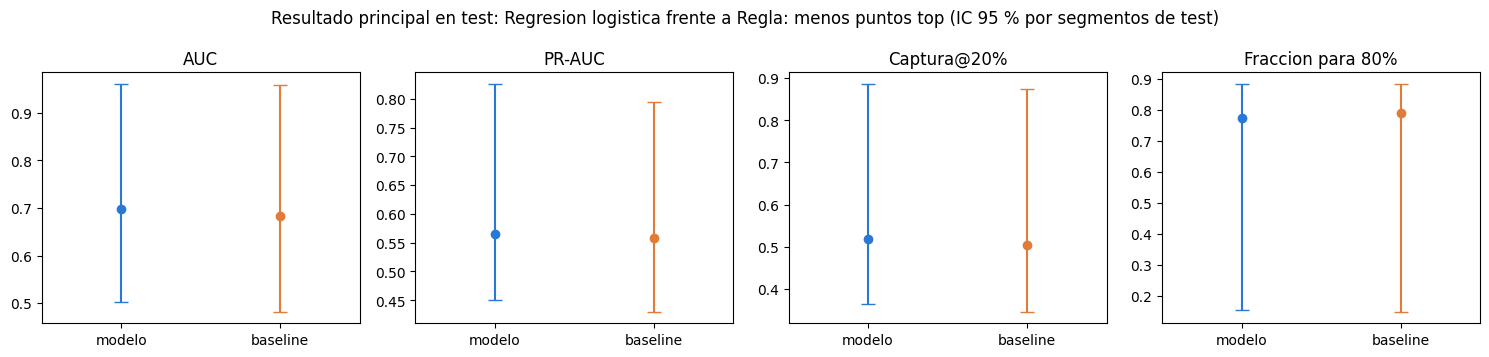

**Caso del plan: `ningun_modelo_supera_al_mejor_baseline`.** Se reporta que ningun modelo cumple 'vale la pena' frente al mejor baseline simple y que el baseline es suficiente por simplicidad y explicabilidad. Si el IC por segmentos incluye 0 se escribe 'no se distingue del baseline', no 'es peor'. En test (población principal, 16.062 filas, 8 segmentos), Regresion logistica frente a Regla: menos puntos top: AUC 0,698 contra 0,684 (diferencia +0,014, IC 95 % -0,014 a +0,029) y Fracción para 80 % 77,4 % contra 79,0 % (diferencia -1,7 puntos, IC -4,2 a +4,1). El criterio 'vale la pena' (Fracción para 80 % baja ≥ 5 puntos con IC que excluye 0 y AUC sube ≥ 0,03) **no se cumple**. Los IC de ambas diferencias incluyen 0: **el modelo no se distingue del baseline**.

In [6]:
CP = PLAN["comparacion_principal"]
MOD, BASE = CP["modelo"], CP["baseline"]
assert MOD in SC_P and BASE in SC_P
t0 = time.time()
punto_p, b_p = boot(SC_P, POB_P, n_boot=1000)
vlp, dA, dF = vale_la_pena(punto_p, b_p, MOD, BASE)
no_dist = bool(dA[1] <= 0 <= dA[2] and dF[1] <= 0 <= dF[2])
filas = []
for n in (MOD, BASE):
    f = {"metodo": n}
    for m in MET:
        lo, hi = ic(b_p[n][m])
        f[m] = f"{punto_p[n][m]:.3f} ({lo:.3f} a {hi:.3f})"
    filas.append(f)
t_main = pd.DataFrame(filas)
print(t_main.to_string(index=False))
print(f"\n{MOD} menos {BASE}: dAUC {dA[0]:+.3f} (IC {dA[1]:+.3f} a {dA[2]:+.3f}) | dFraccion80 {pts(dF[0] * 100)} puntos (IC {pts(dF[1] * 100)} a {pts(dF[2] * 100)}) | vale la pena: {vlp} | IC de ambas diferencias incluyen 0: {no_dist}")
dC, dP = delta(punto_p, b_p, MOD, BASE, "Captura@20%"), delta(punto_p, b_p, MOD, BASE, "PR-AUC")
guardar_csv(t_main, "10_resultado_principal", indice=False)
RES["B"] = {"mod": MOD, "base": BASE, "dA": dA, "dF": dF, "dC": dC, "dP": dP, "vlp": vlp, "no_dist": no_dist, "punto": {n: punto_p[n] for n in (MOD, BASE)}, "ic": {n: {m: ic(b_p[n][m]) for m in MET} for n in (MOD, BASE)}}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, m in zip(axes, MET):
    for i, (n, c) in enumerate([(MOD, AZUL), (BASE, NARANJA)]):
        lo, hi = ic(b_p[n][m])
        ax.errorbar(i, punto_p[n][m], yerr=[[punto_p[n][m] - lo], [hi - punto_p[n][m]]], fmt="o", color=c, capsize=5)
    ax.set_xticks([0, 1], ["modelo", "baseline"]); ax.set_title(m); ax.set_xlim(-0.5, 1.5)
fig.suptitle(f"Resultado principal en test: {MOD} frente a {BASE} (IC 95 % por segmentos de test)")
fig.tight_layout()
guardar_fig(fig, "10_resultado_principal")
plt.show()

caso = "algun_modelo_supera" if vlp else "ningun_modelo_supera_al_mejor_baseline"
frase_plan = PLAN["redaccion_de_la_conclusion"][caso]
conclusion_principal = (f"**Caso del plan: `{caso}`.** {frase_plan} " +
                        f"En test (población principal, {miles(len(pop_p))} filas, {POB_P['n_seg']} segmentos), {MOD} frente a {BASE}: AUC {n3(punto_p[MOD]['AUC'])} contra {n3(punto_p[BASE]['AUC'])} (diferencia {n3(dA[0], True)}, IC 95 % {n3(dA[1], True)} a {n3(dA[2], True)}) y Fracción para 80 % "
                        f"{pct(punto_p[MOD]['Fraccion para 80%'])} contra {pct(punto_p[BASE]['Fraccion para 80%'])} (diferencia {pts(dF[0] * 100)} puntos, IC {pts(dF[1] * 100)} a {pts(dF[2] * 100)}). " +
                        ("El criterio 'vale la pena' (Fracción para 80 % baja ≥ 5 puntos con IC que excluye 0 y AUC sube ≥ 0,03) **se cumple**." if vlp else "El criterio 'vale la pena' (Fracción para 80 % baja ≥ 5 puntos con IC que excluye 0 y AUC sube ≥ 0,03) **no se cumple**.") +
                        (" Los IC de ambas diferencias incluyen 0: **el modelo no se distingue del baseline**." if no_dist else ""))
RES["B"]["texto"] = conclusion_principal
TIEMPO_B = time.time() - t0
display(Markdown(conclusion_principal))

# C. Resultados secundarios

**Por qué importa.** Para no depender de una sola comparación se muestran todos los métodos del plan en la población principal. Esto es **secundario**: no cambia la conclusión principal.

In [7]:
filas = []
for n in METODOS:
    f = {"metodo": n}
    for m in MET:
        lo, hi = ic(b_p[n][m])
        f[m] = f"{punto_p[n][m]:.3f} ({lo:.3f} a {hi:.3f})"
    filas.append(f)
t_sec = pd.DataFrame(filas)
print("Todos los metodos, poblacion principal (IC 95 % por segmentos de test):")
print(t_sec.to_string(index=False))
guardar_csv(t_sec, "10_metodos_poblacion_principal", indice=False)

filas = []
for n in (N_LR, N_HGB, N_RF, N_MIN):
    ok, a_, f_ = vale_la_pena(punto_p, b_p, n, N_TOP)
    filas.append({"modelo": n, "base": N_TOP, "dAUC": f"{a_[0]:+.3f} ({a_[1]:+.3f} a {a_[2]:+.3f})", "dFraccion80 (puntos)": f"{pts(f_[0] * 100)} ({pts(f_[1] * 100)} a {pts(f_[2] * 100)})", "vale la pena": "si" if ok else "no"})
t_vs_top = pd.DataFrame(filas)
print("\nContra la regla por puntos top (baseline elegido en train):")
print(t_vs_top.to_string(index=False))

# ---- sensibilidad aparte: que baseline habria sido el mejor en test
auc_test = {n: punto_p[n]["AUC"] for n in SIMPLES}
BASE_TEST = max(SIMPLES, key=lambda n: (round(auc_test[n], 12), -SIMPLES.index(n)))
filas = []
for n in (N_LR, N_HGB, N_RF):
    ok, a_, f_ = vale_la_pena(punto_p, b_p, n, BASE_TEST)
    filas.append({"modelo": n, "mejor baseline en test": BASE_TEST, "dAUC": f"{a_[0]:+.3f} ({a_[1]:+.3f} a {a_[2]:+.3f})", "dFraccion80 (puntos)": f"{pts(f_[0] * 100)} ({pts(f_[1] * 100)} a {pts(f_[2] * 100)})", "vale la pena": "si" if ok else "no"})
t_sens_base = pd.DataFrame(filas)
print(f"\nSensibilidad aparte: el mejor baseline simple en test habria sido '{BASE_TEST}' (AUC {auc_test[BASE_TEST]:.3f}); en train se eligio '{BASE}'.")
print(t_sens_base.to_string(index=False))
RES["C"] = {"base_test": BASE_TEST, "auc_simples": auc_test, "vlp_vs_top": {r["modelo"]: r["vale la pena"] == "si" for r in filas for _ in [0]}}
RES["C"]["vlp_vs_base_test"] = {r["modelo"]: r["vale la pena"] == "si" for r in filas}
RES["C"]["vlp_vs_top"] = {r["modelo"]: r["vale la pena"] == "si" for r in t_vs_top.to_dict("records")}
guardar_csv(t_vs_top, "10_vs_regla_top", indice=False)
guardar_csv(t_sens_base, "10_sensibilidad_mejor_baseline_test", indice=False)

# ---- lectura complementaria por segmento (solo segmentos con >= 50 positivos en la poblacion principal)
pos_seg = pop_p.groupby(GRUPO)["sin_camara"].sum()
evaluables = pos_seg[pos_seg >= 50].index.tolist()
lista_plan = PLAN["composicion_conocida_del_test"]["segmentos_con_50_positivos_principal"]
if not ENSAYO:
    assert sorted(s[:12] for s in evaluables) == sorted(lista_plan), "los segmentos evaluables no coinciden con los del plan"
auc_seg = {}
for n in METODOS:
    auc_seg[n] = {}
    for sg in evaluables:
        m_ = (pop_p[GRUPO] == sg).values
        yy = pop_p.loc[m_, "sin_camara"].values
        auc_seg[n][sg] = roc_auc_score(yy, SC_P[n][m_]) if len(np.unique(yy)) > 1 else np.nan
auc_seg = pd.DataFrame(auc_seg)
auc_seg.index = [s[:12] for s in auc_seg.index]
print("\nAUC por segmento (solo segmentos con >= 50 positivos):")
print(auc_seg.round(3).to_string())
rng_s = np.random.default_rng(SEMILLA)
filas = []
for n in (N_LR, N_HGB, N_RF, N_MIN):
    d = (auc_seg[n] - auc_seg[BASE]).dropna()
    meds = np.array([np.median(rng_s.choice(d.values, len(d), replace=True)) for _ in range(2000)])
    filas.append({"modelo": n, "segmentos": len(d), "mediana dif AUC (modelo - baseline)": d.median(), "IQR": f"{d.quantile(0.25):+.3f} a {d.quantile(0.75):+.3f}", "proporcion donde el modelo supera": (d > 0).mean(), "IC95% mediana": f"{np.percentile(meds, 2.5):+.3f} a {np.percentile(meds, 97.5):+.3f}"})
t_seg = pd.DataFrame(filas)
print(t_seg.round(3).to_string(index=False))
guardar_csv(auc_seg, "10_auc_por_segmento")
guardar_csv(t_seg, "10_lectura_por_segmento", indice=False)
RES["C"]["seg"] = t_seg.set_index("modelo").to_dict("index")
RES["C"]["evaluables"] = len(evaluables)
rl = RES["C"]["seg"][MOD]
display(Markdown(
    f"**Lectura (generada).** En la población principal, el mejor baseline simple en test habría sido **{BASE_TEST}** (AUC {n3(auc_test[BASE_TEST])}); en train se había elegido {BASE}. " +
    "Frente a la regla por puntos top, cumplen 'vale la pena': " + (", ".join(n for n, v in RES["C"]["vlp_vs_top"].items() if v) or "ningún modelo") + ". " +
    f"Lectura complementaria por segmento ({rl['segmentos']} segmentos con ≥ 50 positivos): {MOD} menos {BASE} tiene mediana {n3(rl['mediana dif AUC (modelo - baseline)'], True)} de AUC (IQR {rl['IQR']}), supera en el {pct(rl['proporcion donde el modelo supera'], 0)} de los segmentos (IC 95 % de la mediana {rl['IC95% mediana']}). "
    "Esta lectura complementaria no reemplaza los criterios."))

Todos los metodos, poblacion principal (IC 95 % por segmentos de test):
                                 metodo                   AUC                PR-AUC           Captura@20%     Fraccion para 80%
              Regla: menos puntos LiDAR 0.683 (0.481 a 0.957) 0.557 (0.429 a 0.793) 0.502 (0.346 a 0.875) 0.801 (0.153 a 0.884)
                Regla: menos puntos top 0.684 (0.482 a 0.958) 0.558 (0.430 a 0.795) 0.503 (0.346 a 0.875) 0.790 (0.148 a 0.883)
Regla geometrica (azimut > 105 primero) 0.683 (0.481 a 0.957) 0.557 (0.429 a 0.793) 0.502 (0.346 a 0.875) 0.801 (0.153 a 0.884)
         Modelo minimo (LR 3 variables) 0.685 (0.487 a 0.957) 0.556 (0.441 a 0.789) 0.497 (0.347 a 0.867) 0.786 (0.156 a 0.886)
                    Regresion logistica 0.698 (0.503 a 0.961) 0.565 (0.451 a 0.826) 0.517 (0.364 a 0.887) 0.774 (0.154 a 0.884)
                                    HGB 0.679 (0.514 a 0.953) 0.578 (0.459 a 0.807) 0.510 (0.348 a 0.865) 0.821 (0.153 a 0.864)
                          Random

**Lectura (generada).** En la población principal, el mejor baseline simple en test habría sido **Modelo minimo (LR 3 variables)** (AUC 0,685); en train se había elegido Regla: menos puntos top. Frente a la regla por puntos top, cumplen 'vale la pena': ningún modelo. Lectura complementaria por segmento (4 segmentos con ≥ 50 positivos): Regresion logistica menos Regla: menos puntos top tiene mediana +0,003 de AUC (IQR -0.011 a +0.012), supera en el 50 % de los segmentos (IC 95 % de la mediana -0.033 a +0.016). Esta lectura complementaria no reemplaza los criterios.

# D. Puntos de operación A y B con los umbrales congelados

**Por qué importa.** Un ranking no decide qué revisar: hace falta un corte. Los cortes se fijaron con train y no se mueven. El punto A apuntaba a recall 0,80 y se considera **sostenido** si el recall puntual en test es ≥ 0,75 (plan v2); el punto B revisa el 20 % mejor puntuado y se reporta sin tolerancia.

                                 metodo                    punto umbral   TP   FP   FN    TN                recall             precision                    F1           pct_revisar % revisado en train (OOF)
              Regla: menos puntos LiDAR A (recall objetivo 0,80)    -25 2214 3246 1520  9082 0.593 (0.387 a 0.931) 0.405 (0.297 a 0.555) 0.482 (0.338 a 0.680) 0.340 (0.246 a 0.410)                     0.385
              Regla: menos puntos LiDAR     B (20 % de revision)    -10 1749  911 1985 11417 0.468 (0.329 a 0.781) 0.658 (0.559 a 0.791) 0.547 (0.414 a 0.755) 0.166 (0.127 a 0.206)                     0.209
              Regla: menos puntos LiDAR    referencia: maximo F1    -10 1749  911 1985 11417 0.468 (0.329 a 0.781) 0.658 (0.559 a 0.791) 0.547 (0.414 a 0.755) 0.166 (0.127 a 0.206)                         -
                Regla: menos puntos top A (recall objetivo 0,80)    -24 2202 3113 1532  9215 0.590 (0.383 a 0.924) 0.414 (0.303 a 0.567) 0.487 (0.340 a 0.689) 0.331 (0.238 

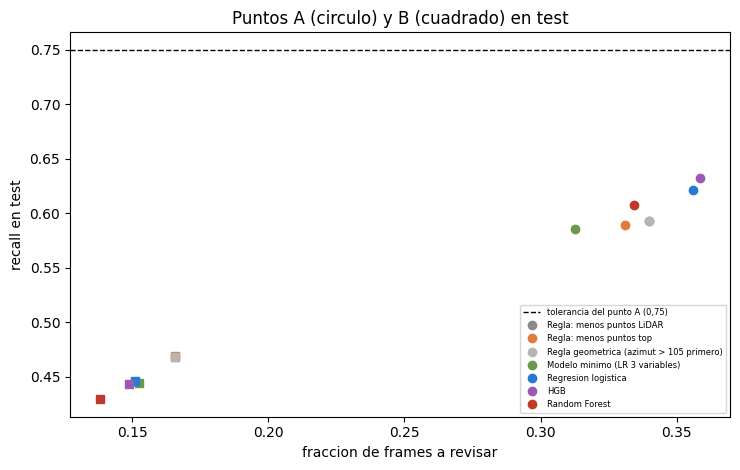

**Lectura (generada).** **Punto A de Regresion logistica** (umbral 0.1456, fijado con train): recall 0,621 (IC 95 % 0,413 a 0,958) — **no se sostiene** según la tolerancia del plan (recall ≥ 0,75) —, precisión 0,406 y 35,6 % de los frames a revisar (en train: 38,9 %). **Punto B:** recall 0,447 (IC 0,305 a 0,776), precisión 0,688 y 15,1 % revisado. **Regla: menos puntos top, punto A:** recall 0,590 (IC 0,383 a 0,924), precisión 0,414, 33,1 % a revisar (no se sostiene). Horas, solo como ilustración con 20 s por revisión: revisar todo costaría 89 h; al punto A el modelo cuesta 31 h y el baseline 29 h.

In [8]:
REF = PLAN["diferencias_con_train"]["referencia_train_oof_principal"]
FLAGS = {n: {p: SC_P[n] >= UMB_P[n][p] for p in ("A", "B", "F1")} for n in METODOS}
filas, OP = [], {}
for n in METODOS:
    for p, desc in (("A", "A (recall objetivo 0,80)"), ("B", "B (20 % de revision)"), ("F1", "referencia: maximo F1")):
        m = flags_y_metricas(FLAGS[n][p], POB_P["y"])
        bb = boot_flags(FLAGS[n][p], POB_P, n_boot=1000)
        OP[(n, p)] = {**m, **{k: (m[k], *ic(bb[k])) for k in ("recall", "precision", "F1", "pct_revisar")}}
        fila = {"metodo": n, "punto": desc, "umbral": f"{UMB_P[n][p]:.4g}", "TP": m["TP"], "FP": m["FP"], "FN": m["FN"], "TN": m["TN"]}
        for k in ("recall", "precision", "F1", "pct_revisar"):
            lo, hi = ic(bb[k])
            fila[k] = f"{m[k]:.3f} ({lo:.3f} a {hi:.3f})"
        fila["% revisado en train (OOF)"] = f"{REF[n]['% revisado A']:.3f}" if p == "A" else (f"{REF[n]['% revisado B']:.3f}" if p == "B" else "-")
        filas.append(fila)
t_op = pd.DataFrame(filas)
print(t_op.to_string(index=False))
guardar_csv(t_op, "10_puntos_de_operacion", indice=False)

TOL_A = 0.75
sostenido = {n: bool(OP[(n, "A")]["recall"][0] >= TOL_A) for n in METODOS}
print(f"\nPunto A sostenido (recall puntual >= {str(TOL_A).replace('.', ',')}):", sostenido)

# horas ilustrativas (supuesto de 20 s por revision; no es un dato medido)
SEG_REV = 20
horas_total = len(pop_p) * SEG_REV / 3600
cum_base = curva_cap(POB_P["y"].astype(float), SC_P[BASE], POB_P["tb"])
filas = []
for n in (MOD, BASE):
    a_ = OP[(n, "A")]
    frac_base = (np.searchsorted(cum_base, a_["recall"][0]) + 1) / len(cum_base)
    filas.append({"metodo": n, "horas al punto A": horas_total * a_["pct_revisar"][0], "horas del baseline para el mismo recall": horas_total * frac_base, "horas al azar": horas_total * a_["recall"][0], "horas revisando todo": horas_total})
t_horas = pd.DataFrame(filas)
print(f"\nHoras ilustrativas con el supuesto de {SEG_REV} s por revision (no es un dato medido):")
print(t_horas.round(1).to_string(index=False))
RES["D"] = {"OP": OP, "sostenido": sostenido, "horas": t_horas.set_index("metodo").to_dict("index"), "tol": TOL_A}

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for n, c in zip(METODOS, [GRIS, NARANJA, "#b5b5b5", VERDE, AZUL, "#9b59b6", ROJO]):
    for p, mk in (("A", "o"), ("B", "s")):
        a_ = OP[(n, p)]
        lo, hi = a_["recall"][0], a_["recall"][1]
        ax.errorbar(a_["pct_revisar"][0], a_["recall"][0], yerr=None, fmt=mk, color=c, label=n if p == "A" else None)
ax.axhline(TOL_A, color="k", ls="--", lw=1, label="tolerancia del punto A (0,75)")
ax.set_xlabel("fraccion de frames a revisar"); ax.set_ylabel("recall en test"); ax.set_title("Puntos A (circulo) y B (cuadrado) en test"); ax.legend(fontsize=6)
fig.tight_layout()
guardar_fig(fig, "10_puntos_de_operacion")
plt.show()
oa, ob = OP[(MOD, "A")], OP[(MOD, "B")]
ra, rb_ = OP[(BASE, "A")], OP[(BASE, "B")]
display(Markdown(
    f"**Lectura (generada).** **Punto A de {MOD}** (umbral {UMB_P[MOD]['A']:.4g}, fijado con train): recall {n3(oa['recall'][0])} (IC 95 % {n3(oa['recall'][1])} a {n3(oa['recall'][2])}) "
    f"— **{'se sostiene' if sostenido[MOD] else 'no se sostiene'}** según la tolerancia del plan (recall ≥ {str(TOL_A).replace('.', ',')}) —, precisión {n3(oa['precision'][0])} y {pct(oa['pct_revisar'][0])} de los frames a revisar (en train: {pct(REF[MOD]['% revisado A'])}). "
    f"**Punto B:** recall {n3(ob['recall'][0])} (IC {n3(ob['recall'][1])} a {n3(ob['recall'][2])}), precisión {n3(ob['precision'][0])} y {pct(ob['pct_revisar'][0])} revisado. "
    f"**{BASE}, punto A:** recall {n3(ra['recall'][0])} (IC {n3(ra['recall'][1])} a {n3(ra['recall'][2])}), precisión {n3(ra['precision'][0])}, {pct(ra['pct_revisar'][0])} a revisar ({'se sostiene' if sostenido[BASE] else 'no se sostiene'}). "
    f"Horas, solo como ilustración con {SEG_REV} s por revisión: revisar todo costaría {miles(t_horas['horas revisando todo'].iloc[0])} h; al punto A el modelo cuesta {miles(t_horas['horas al punto A'].iloc[0])} h y el baseline {miles(t_horas['horas al punto A'].iloc[1])} h."))

# E. Calibración en test (descriptiva)

**Por qué importa.** Si se publican probabilidades, tienen que significar lo que dicen. Se aplica el calibrador **congelado** (la versión que ganó en train) al mejor modelo aprendido; no se reajusta nada.

                      ECE   Brier  probabilidad media  prevalencia
crudo              0.0788  0.1453              0.1746       0.2325
calibrado (Platt)  0.0804  0.1456              0.1728       0.2325


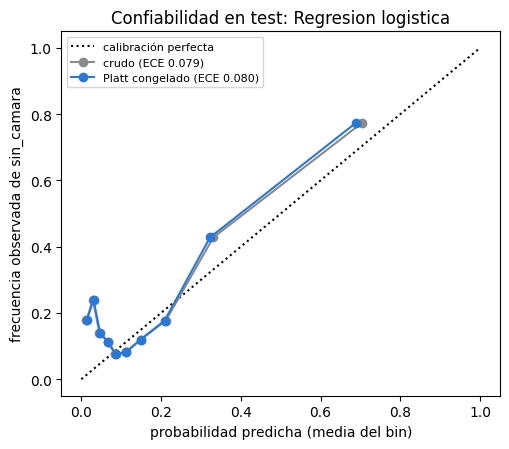

**Lectura (generada, descriptiva).** En test, Regresion logistica crudo tiene ECE 0,079 y Brier 0,145, con probabilidad media 0,175 frente a una prevalencia de 0,232. Con el calibrador congelado (Platt) el ECE es 0,080 y el Brier 0,146 (probabilidad media 0,173). En train (09, fuera de fold) el ECE era 0,044 crudo y 0,013 con Platt. La calibración congelada **no mejora** la calibración en test. No se aplica ningún umbral de aceptación y no se reajusta nada.

In [9]:
from sklearn.linear_model import LogisticRegression  # noqa: F401  (el calibrador se carga con joblib)
cal_obj = joblib.load(RAIZ / PLAN["calibrador"]["archivo"])
VERSION_CAL = cal_obj["mejor"]
assert cal_obj["modelo"] == MOD, "el calibrador congelado no corresponde al modelo de la comparacion principal"


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


p_raw = SC_P[MOD]
if VERSION_CAL == "Platt":
    p_cal = cal_obj["calibradores"]["Platt"].predict_proba(logit(p_raw))[:, 1]
elif VERSION_CAL == "Isotonica":
    p_cal = cal_obj["calibradores"]["Isotonica"].predict(p_raw)
else:
    p_cal = p_raw
yy = POB_P["y"]


def ece_cuantiles(y_, p_, n_bins=10):
    b = pd.qcut(pd.Series(p_).rank(method="first"), n_bins, labels=False)
    g = pd.DataFrame({"y": y_, "p": p_, "b": b.values}).groupby("b").agg(n=("y", "size"), obs=("y", "mean"), pred=("p", "mean"))
    return float((g["n"] / g["n"].sum() * (g["obs"] - g["pred"]).abs()).sum()), g


e_raw, g_raw = ece_cuantiles(yy, p_raw)
e_cal, g_cal = ece_cuantiles(yy, p_cal)
t_cal = pd.DataFrame({"ECE": [e_raw, e_cal], "Brier": [brier_score_loss(yy, p_raw), brier_score_loss(yy, p_cal)], "probabilidad media": [p_raw.mean(), p_cal.mean()], "prevalencia": [yy.mean()] * 2}, index=["crudo", f"calibrado ({VERSION_CAL})"])
print(t_cal.round(4).to_string())
guardar_csv(t_cal, "10_calibracion")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color="k", ls=":", label="calibración perfecta")
ax.plot(g_raw["pred"], g_raw["obs"], marker="o", color=GRIS, label=f"crudo (ECE {e_raw:.3f})")
ax.plot(g_cal["pred"], g_cal["obs"], marker="o", color=AZUL, label=f"{VERSION_CAL} congelado (ECE {e_cal:.3f})")
ax.set_xlabel("probabilidad predicha (media del bin)"); ax.set_ylabel("frecuencia observada de sin_camara"); ax.set_title(f"Confiabilidad en test: {MOD}"); ax.legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "10_calibracion")
plt.show()
RES["E"] = {"ece_raw": e_raw, "ece_cal": e_cal, "brier_raw": float(t_cal.iloc[0, 1]), "brier_cal": float(t_cal.iloc[1, 1]), "version": VERSION_CAL, "pm_raw": float(p_raw.mean()), "pm_cal": float(p_cal.mean()), "prev": float(yy.mean())}
cal09 = pd.read_csv(RUTA_REP / "09_calibracion.csv", index_col=0)
display(Markdown(
    f"**Lectura (generada, descriptiva).** En test, {MOD} crudo tiene ECE {n3(e_raw)} y Brier {n3(t_cal.iloc[0, 1])}, con probabilidad media {n3(p_raw.mean())} frente a una prevalencia de {n3(yy.mean())}. Con el calibrador congelado ({VERSION_CAL}) el ECE es {n3(e_cal)} y el Brier {n3(t_cal.iloc[1, 1])} "
    f"(probabilidad media {n3(p_cal.mean())}). En train (09, fuera de fold) el ECE era {n3(cal09.loc['Crudo', 'ECE'])} crudo y {n3(cal09.loc[VERSION_CAL, 'ECE'])} con {VERSION_CAL}. " + ("La calibración congelada **mejora** la calibración en test." if e_cal < e_raw else "La calibración congelada **no mejora** la calibración en test.") + " No se aplica ningún umbral de aceptación y no se reajusta nada."))

# F. Análisis de influencia

**Por qué importa.** Con 8 segmentos y dos de ellos concentrando buena parte de las filas, el resultado podría depender de uno solo. Se repite la comparación principal quitando segmentos (sin cada uno de los dos más grandes, sin ambos y dejando uno afuera a la vez).

                       variante  segmentos  filas   dAUC         IC dAUC  dFraccion80 (puntos)     IC dF80  vale la pena
            todos los segmentos          8  16062  0.014 -0.014 a +0.028                -1.656 -4,1 a +4,1         False
               sin 257766998801          7   9588 -0.004 -0.020 a +0.011                 1.335 -0,8 a +7,8         False
               sin 221704303323          7  11409  0.019 -0.019 a +0.034                -1.376 -3,1 a +7,7         False
        sin los dos mas grandes          6   4935 -0.001 -0.021 a +0.015                 1.155 -0,9 a +8,1         False
leave-one-out: sin 102124064984          7  15211  0.015 -0.017 a +0.032                -2.373 -4,0 a +5,8         False
leave-one-out: sin 141430544948          7  14408  0.009 -0.020 a +0.018                -1.798 -2,8 a +7,5         False
leave-one-out: sin 167359384489          7  15866  0.013 -0.017 a +0.030                -1.311 -3,8 a +5,4         False
leave-one-out: sin 221704303323 

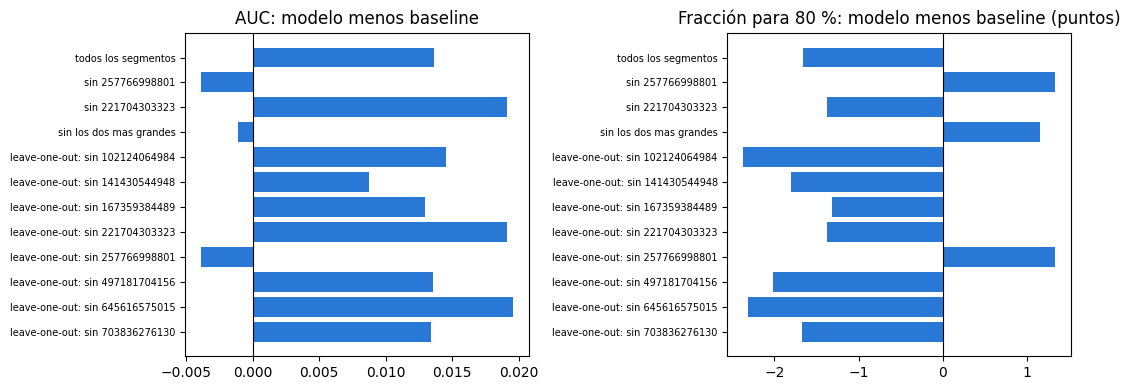

**Lectura (generada).** Con los 12 cálculos (todos los segmentos, sin cada uno de los dos más grandes, sin ambos y leave-one-segment-out), la diferencia de AUC modelo menos baseline va de -0,004 a +0,020 y la de Fracción para 80 % de -2,4 a +1,3 puntos. Con todos los segmentos el criterio 'vale la pena' no se cumple; **ninguna variante cambia ese veredicto**: ningún segmento por sí solo cambia la conclusión.

In [10]:
grandes12 = PLAN["analisis_de_influencia"]["segmentos_grandes"] if not ENSAYO else [s[:12] for s in pop_p.groupby(GRUPO).size().nlargest(2).index]
segs_todos = sorted(pop_p[GRUPO].unique())
mapa = {s[:12]: s for s in segs_todos}
assert all(g in mapa for g in grandes12), "los segmentos grandes del plan no estan en el test"
grandes = [mapa[g] for g in grandes12]
variantes = {"todos los segmentos": []}
for g in grandes:
    variantes[f"sin {g[:12]}"] = [g]
variantes["sin los dos mas grandes"] = list(grandes)
for s in segs_todos:
    variantes[f"leave-one-out: sin {s[:12]}"] = [s]
t0 = time.time()
filas = []
for nom, excl in variantes.items():
    d = pop_p[~pop_p[GRUPO].isin(excl)].reset_index(drop=True)
    msk = (~pop_p[GRUPO].isin(excl)).values
    sc = {MOD: SC_P[MOD][msk], BASE: SC_P[BASE][msk]}
    pb, bb = boot(sc, poblacion(d), n_boot=500)
    ok, a_, f_ = vale_la_pena(pb, bb, MOD, BASE)
    filas.append({"variante": nom, "segmentos": d[GRUPO].nunique(), "filas": len(d), "dAUC": a_[0], "IC dAUC": f"{a_[1]:+.3f} a {a_[2]:+.3f}", "dFraccion80 (puntos)": f_[0] * 100, "IC dF80": f"{pts(f_[1] * 100)} a {pts(f_[2] * 100)}", "vale la pena": ok})
t_inf = pd.DataFrame(filas)
print(t_inf.round(3).to_string(index=False))
guardar_csv(t_inf, "10_influencia", indice=False)
TIEMPO_F = time.time() - t0
v_todos = bool(t_inf.loc[0, "vale la pena"])
cambian = t_inf[t_inf["vale la pena"] != v_todos]["variante"].tolist()
rng_a = (t_inf["dAUC"].min(), t_inf["dAUC"].max())
rng_f = (t_inf["dFraccion80 (puntos)"].min(), t_inf["dFraccion80 (puntos)"].max())
RES["F"] = {"rng_auc": rng_a, "rng_f80": rng_f, "cambian": cambian, "n": len(t_inf)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, tit in zip(axes, ["dAUC", "dFraccion80 (puntos)"], ["AUC: modelo menos baseline", "Fracción para 80 %: modelo menos baseline (puntos)"]):
    ax.barh(range(len(t_inf)), t_inf[col], color=[AZUL if not v else VERDE for v in t_inf["vale la pena"]])
    ax.set_yticks(range(len(t_inf)), t_inf["variante"], fontsize=7); ax.axvline(0, color="k", lw=0.8); ax.set_title(tit); ax.invert_yaxis()
fig.tight_layout()
guardar_fig(fig, "10_influencia")
plt.show()
display(Markdown(
    f"**Lectura (generada).** Con los {len(t_inf)} cálculos (todos los segmentos, sin cada uno de los dos más grandes, sin ambos y leave-one-segment-out), la diferencia de AUC modelo menos baseline va de {n3(rng_a[0], True)} a {n3(rng_a[1], True)} y la de Fracción para 80 % de {pts(rng_f[0])} a {pts(rng_f[1])} puntos. "
    f"Con todos los segmentos el criterio 'vale la pena' {'se cumple' if v_todos else 'no se cumple'}; " + (f"**cambia** al quitar: {', '.join(cambian)}." if cambian else "**ninguna variante cambia ese veredicto**: ningún segmento por sí solo cambia la conclusión.")))

# G. Equidad descriptiva

**Por qué importa.** Un resultado en promedio puede esconder diferencias por condición. Se describe el desempeño (recall al punto A, precisión, % a revisar y AUC) por ubicación, momento del día y clase, con el número de segmentos y de filas de cada grupo. **Sin pruebas de hipótesis.**

In [11]:
def tabla_grupos(col, metodo):
    filas = []
    for v in sorted(pop_p[col].unique()):
        m_ = (pop_p[col] == v).values
        yy_ = pop_p.loc[m_, "sin_camara"].values
        n1, n0 = int(yy_.sum()), int((1 - yy_).sum())
        mt = flags_y_metricas(FLAGS[metodo]["A"][m_], yy_)
        filas.append({"metodo": metodo, "variable": col, "grupo": v, "segmentos": int(pop_p.loc[m_, GRUPO].nunique()), "filas": int(m_.sum()), "sin_camara": n1,
                      "AUC": roc_auc_score(yy_, SC_P[metodo][m_]) if min(n1, n0) >= 200 else np.nan, "recall A": mt["recall"] if n1 > 0 else np.nan, "precision A": mt["precision"], "% revisado A": mt["pct_revisar"]})
    return filas


filas = []
for n in (MOD, BASE):
    for col in ("location", "time_of_day", "object_type"):
        filas += tabla_grupos(col, n)
t_eq = pd.DataFrame(filas)
print("Equidad descriptiva (punto A congelado; AUC solo si el grupo tiene >= 200 filas por clase):")
print(t_eq.round(3).to_string(index=False))
guardar_csv(t_eq, "10_equidad", indice=False)
seg_por_momento = pop_p.groupby("time_of_day")[GRUPO].nunique().to_dict()
seg_por_ubic = pop_p.groupby("location")[GRUPO].nunique().to_dict()
unico = [k for k, v in seg_por_momento.items() if v == 1]
RES["G"] = {"seg_momento": seg_por_momento, "seg_ubic": seg_por_ubic, "unico": unico}
partes = []
for col, nom in (("time_of_day", "momento del día"), ("location", "ubicación"), ("object_type", "clase")):
    e = t_eq[(t_eq["metodo"] == MOD) & (t_eq["variable"] == col)].dropna(subset=["recall A"])
    if len(e) >= 2:
        mx, mn = e.loc[e["recall A"].idxmax()], e.loc[e["recall A"].idxmin()]
        partes.append(f"por {nom}, el recall al punto A de {MOD} va de {n3(mn['recall A'])} ({mn['grupo']}; {int(mn['segmentos'])} segmento(s), {miles(mn['filas'])} filas, {int(mn['sin_camara'])} positivos) a {n3(mx['recall A'])} ({mx['grupo']}; {int(mx['segmentos'])} segmento(s), {miles(mx['filas'])} filas, {int(mx['sin_camara'])} positivos), una brecha de {n3(mx['recall A'] - mn['recall A'])}")
display(Markdown(
    "**Lectura (generada, descriptiva, sin pruebas de hipótesis).** " + "; ".join(partes) + ". " +
    f"**Salvedad:** segmentos de test por momento del día: {seg_por_momento}; por ubicación: {seg_por_ubic}. " +
    (f"{' y '.join(unico)} " + ("tiene" if len(unico) == 1 else "tienen") + " un solo segmento cada uno, así que la diferencia por momento del día es la de un segmento contra otros y no se puede separar del efecto del segmento. " if unico else "") +
    f"Los ciclistas tienen {miles((pop_p['object_type'] == 'CYCLIST').sum())} filas y {int(pop_p.loc[pop_p['object_type'] == 'CYCLIST', 'sin_camara'].sum())} positivos" + (", por lo que su recall es poco estable." if pop_p.loc[pop_p['object_type'] == 'CYCLIST', 'sin_camara'].sum() < 50 else ".")))

Equidad descriptiva (punto A congelado; AUC solo si el grupo tiene >= 200 filas por clase):
                 metodo    variable          grupo  segmentos  filas  sin_camara   AUC  recall A  precision A  % revisado A
    Regresion logistica    location location_other          2   1850         258 0.979     0.992        0.573         0.242
    Regresion logistica    location   location_phx          3   2234         464 0.862     0.899        0.333         0.560
    Regresion logistica    location    location_sf          3  11978        3012 0.650     0.547        0.409         0.336
    Regresion logistica time_of_day      Dawn/Dusk          1    851          48   NaN     1.000        0.623         0.090
    Regresion logistica time_of_day            Day          6  10558        2768 0.589     0.525        0.350         0.393
    Regresion logistica time_of_day          Night          1   4653         918 0.933     0.893        0.550         0.320
    Regresion logistica object_type     

**Lectura (generada, descriptiva, sin pruebas de hipótesis).** por momento del día, el recall al punto A de Regresion logistica va de 0,525 (Day; 6 segmento(s), 10.558 filas, 2768 positivos) a 1,000 (Dawn/Dusk; 1 segmento(s), 851 filas, 48 positivos), una brecha de 0,475; por ubicación, el recall al punto A de Regresion logistica va de 0,547 (location_sf; 3 segmento(s), 11.978 filas, 3012 positivos) a 0,992 (location_other; 2 segmento(s), 1.850 filas, 258 positivos), una brecha de 0,445; por clase, el recall al punto A de Regresion logistica va de 0,621 (PEDESTRIAN; 8 segmento(s), 15.730 filas, 3731 positivos) a 0,667 (CYCLIST; 2 segmento(s), 332 filas, 3 positivos), una brecha de 0,045. **Salvedad:** segmentos de test por momento del día: {'Dawn/Dusk': 1, 'Day': 6, 'Night': 1}; por ubicación: {'location_other': 2, 'location_phx': 3, 'location_sf': 3}. Dawn/Dusk y Night tienen un solo segmento cada uno, así que la diferencia por momento del día es la de un segmento contra otros y no se puede separar del efecto del segmento. Los ciclistas tienen 332 filas y 3 positivos, por lo que su recall es poco estable.

# H. Sensibilidad a 120 grados

**Por qué importa.** La población principal excluye 100–120° porque ahí la ausencia de par 2D es en buena parte geométrica. Con los modelos congelados `*_B120` (entrenados en toda la población de 120°) y sus umbrales se repite la comparación, ahora también contra la regla geométrica, y se aplica el criterio de **robusto** del plan.

In [12]:
t0 = time.time()
punto_120, b_120 = boot(SC_120, POB_120, n_boot=500)
auc120 = {n: punto_120[n]["AUC"] for n in SIMPLES}
BASE_120_TEST = max(SIMPLES, key=lambda n: (round(auc120[n], 12), -SIMPLES.index(n)))
BASE_120_TRAIN = N_GEOM                     # mejor baseline simple elegido en train para la poblacion de 120 (09)
filas = []
for n in METODOS:
    f = {"metodo": n}
    for m in MET:
        lo, hi = ic(b_120[n][m])
        f[m] = f"{punto_120[n][m]:.3f} ({lo:.3f} a {hi:.3f})"
    filas.append(f)
t_120 = pd.DataFrame(filas)
print(f"Poblacion de 120 ({miles(len(pop120))} filas, {miles(int(pop120['sin_camara'].sum()))} positivos); mejor baseline simple en test: {BASE_120_TEST}; elegido en train: {BASE_120_TRAIN}")
print(t_120.to_string(index=False))
guardar_csv(t_120, "10_metodos_poblacion_120", indice=False)
filas = []
for n in (N_LR, N_HGB, N_RF):
    for base in (N_GEOM, N_TOP):
        ok, a_, f_ = vale_la_pena(punto_120, b_120, n, base)
        filas.append({"modelo": n, "base": base, "dAUC": f"{a_[0]:+.3f} ({a_[1]:+.3f} a {a_[2]:+.3f})", "dFraccion80 (puntos)": f"{pts(f_[0] * 100)} ({pts(f_[1] * 100)} a {pts(f_[2] * 100)})", "vale la pena": "si" if ok else "no"})
t_120c = pd.DataFrame(filas)
print("\nContra la regla geometrica y la regla por puntos top (poblacion de 120):")
print(t_120c.to_string(index=False))
guardar_csv(t_120c, "10_comparacion_120", indice=False)

# ---- criterio "robusto" del plan: vale la pena en la principal y en la de 120
vlp_p_top = {n: vale_la_pena(punto_p, b_p, n, N_TOP)[0] for n in (N_LR, N_HGB, N_RF)}                 # principal frente a la regla top (elegida en train)
vlp_p_test = {n: vale_la_pena(punto_p, b_p, n, BASE_TEST)[0] for n in (N_LR, N_HGB, N_RF)}             # principal frente al mejor baseline del test
vlp_120_train = {n: vale_la_pena(punto_120, b_120, n, BASE_120_TRAIN)[0] for n in (N_LR, N_HGB, N_RF)}   # 120 frente a la regla geometrica (elegida en train)
vlp_120_test = {n: vale_la_pena(punto_120, b_120, n, BASE_120_TEST)[0] for n in (N_LR, N_HGB, N_RF)}    # 120 frente al mejor baseline del test
robusto_literal = {n: bool(vlp_p_test[n] and vlp_120_test[n]) for n in vlp_p_test}
robusto_train = {n: bool(vlp_p_top[n] and vlp_120_train[n]) for n in vlp_p_top}
print("\nRobusto (lectura literal del plan: mejor baseline simple de cada poblacion en test):", robusto_literal)
print("Robusto (con los baselines elegidos en train: regla top y regla geometrica):", robusto_train)
RES["H"] = {"base120_test": BASE_120_TEST, "base120_train": BASE_120_TRAIN, "robusto_literal": robusto_literal, "robusto_train": robusto_train, "vlp_120_train": vlp_120_train, "vlp_120_test": vlp_120_test,
            "difieren": robusto_literal != robusto_train, "mod_dif_geom": {k: v for k, v in zip(t_120c["modelo"] + "|" + t_120c["base"], t_120c["vale la pena"])}}
dg = delta(punto_120, b_120, MOD, N_GEOM, "Fraccion para 80%"), delta(punto_120, b_120, MOD, N_GEOM, "AUC")
FL120 = {n: {p: SC_120[n] >= UMB_120[n][p] for p in ("A", "B")} for n in METODOS}
filas = []
for n in METODOS:
    for p in ("A", "B"):
        m = flags_y_metricas(FL120[n][p], POB_120["y"])
        fila = {"metodo": n, "punto": p, "umbral": f"{UMB_120[n][p]:.4g}", "recall": round(m["recall"], 3), "precision": round(m["precision"], 3), "F1": round(m["F1"], 3), "% revisar": round(m["pct_revisar"], 3), "TP": m["TP"], "FP": m["FP"], "FN": m["FN"], "TN": m["TN"]}
        filas.append(fila)
t_op120 = pd.DataFrame(filas)
print("Puntos de operacion A y B en la poblacion de 120 (umbrales y modelos *_B120 congelados):")
print(t_op120.to_string(index=False))
guardar_csv(t_op120, "10_puntos_de_operacion_120", indice=False)
TIEMPO_H = time.time() - t0
display(Markdown(
    f"**Lectura (generada).** En la población de 120° ({miles(len(pop120))} filas) el mejor baseline simple en test es **{BASE_120_TEST}** (AUC {n3(auc120[BASE_120_TEST])}) y el elegido en train era {BASE_120_TRAIN}. "
    f"{MOD} (modelo de 120°) menos la regla geométrica: AUC {n3(dg[1][0], True)} (IC {n3(dg[1][1], True)} a {n3(dg[1][2], True)}) y Fracción para 80 % {pts(dg[0][0] * 100)} puntos (IC {pts(dg[0][1] * 100)} a {pts(dg[0][2] * 100)}). "
    f"**Robusto (lectura literal del plan):** " + (", ".join(n for n, v in robusto_literal.items() if v) or "ningún modelo") + "; **con los baselines elegidos en train:** " + (", ".join(n for n, v in robusto_train.items() if v) or "ningún modelo") + ". " +
    ("Las dos lecturas coinciden." if robusto_literal == robusto_train else "**Las dos lecturas difieren**; se reportan ambas.")))

Poblacion de 120 (17.297 filas, 4.378 positivos); mejor baseline simple en test: Regla geometrica (azimut > 105 primero); elegido en train: Regla geometrica (azimut > 105 primero)
                                 metodo                   AUC                PR-AUC           Captura@20%     Fraccion para 80%
              Regla: menos puntos LiDAR 0.639 (0.449 a 0.876) 0.534 (0.420 a 0.736) 0.458 (0.318 a 0.770) 0.833 (0.239 a 0.884)
                Regla: menos puntos top 0.640 (0.450 a 0.877) 0.535 (0.420 a 0.738) 0.459 (0.317 a 0.770) 0.832 (0.234 a 0.882)
Regla geometrica (azimut > 105 primero) 0.707 (0.530 a 0.951) 0.541 (0.474 a 0.712) 0.526 (0.401 a 0.879) 0.770 (0.161 a 0.874)
         Modelo minimo (LR 3 variables) 0.687 (0.528 a 0.923) 0.513 (0.442 a 0.697) 0.433 (0.332 a 0.767) 0.735 (0.218 a 0.884)
                    Regresion logistica 0.712 (0.563 a 0.929) 0.525 (0.466 a 0.751) 0.445 (0.344 a 0.815) 0.685 (0.188 a 0.877)
                                    HGB 0.726 (0.566

**Lectura (generada).** En la población de 120° (17.297 filas) el mejor baseline simple en test es **Regla geometrica (azimut > 105 primero)** (AUC 0,707) y el elegido en train era Regla geometrica (azimut > 105 primero). Regresion logistica (modelo de 120°) menos la regla geométrica: AUC +0,005 (IC -0,054 a +0,042) y Fracción para 80 % -8,5 puntos (IC -10,1 a +14,3). **Robusto (lectura literal del plan):** ningún modelo; **con los baselines elegidos en train:** ningún modelo. Las dos lecturas coinciden.

# I. Test frente a train

**Por qué importa.** Para saber si el comportamiento de train se repite, se compara cada método en test con su referencia fuera de fold de train (tabla del plan). Si el orden de los métodos difiere, se reporta como hallazgo; no se reajusta nada.

                                         AUC test  AUC train (OOF)  dif AUC  F80 test  F80 train (OOF)  dif F80  recall A test  recall A train  % revisado A test  % revisado A train
metodo                                                                                                                                                                               
Regla: menos puntos LiDAR                   0.683            0.858   -0.175     0.801            0.385    0.416          0.593           0.804              0.340               0.385
Regla: menos puntos top                     0.684            0.862   -0.177     0.790            0.378    0.412          0.590           0.806              0.331               0.379
Regla geometrica (azimut > 105 primero)     0.683            0.858   -0.175     0.801            0.385    0.416          0.593           0.804              0.340               0.385
Modelo minimo (LR 3 variables)              0.685            0.855   -0.170     0.786     

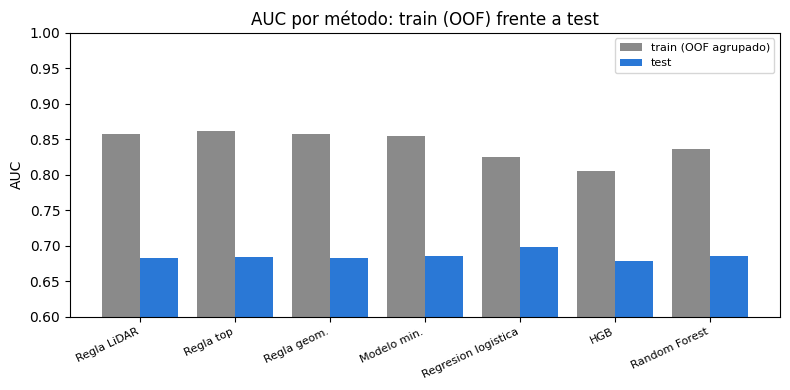

**Lectura (generada).** Orden por AUC en test: Regresion logistica > Random Forest > Modelo minimo (LR 3 variables) > Regla: menos puntos top > Regla: menos puntos LiDAR > Regla geometrica (azimut > 105 primero) > HGB; en train: Regla: menos puntos top > Regla: menos puntos LiDAR > Regla geometrica (azimut > 105 primero) > Modelo minimo (LR 3 variables) > Random Forest > Regresion logistica > HGB (**distinto: se reporta como hallazgo, sin reajustar nada**). Orden por Fracción para 80 % en test: Random Forest < Regresion logistica < Modelo minimo (LR 3 variables) < Regla: menos puntos top < Regla geometrica (azimut > 105 primero) < Regla: menos puntos LiDAR < HGB; en train: Regla: menos puntos top < Modelo minimo (LR 3 variables) < Regla: menos puntos LiDAR < Regla geometrica (azimut > 105 primero) < Random Forest < Regresion logistica < HGB (distinto). **Por qué pueden diferir los modelos y las reglas:** el AUC agrupado de train mezcla las predicciones de cinco modelos distintos (uno por fold, con hiperparámetros distintos), y esa mezcla penaliza a los modelos en -0,035 de AUC en promedio respecto del AUC promedio por fold, mientras que a las reglas (que no tienen esa fuente de variación) en -0,002. En test cada modelo es único y congelado, así que no sufre esa penalización y podría verse mejor que en el 09 respecto de las reglas. En estos datos la diferencia de AUC (test menos train) es -0,135 en promedio para los modelos y -0,174 para las reglas simples, es decir, los modelos cayeron menos que las reglas; la comparación con train debe leerse con esa advertencia.

In [13]:
filas = []
for n in METODOS:
    a_, r_ = OP[(n, "A")], REF[n]
    filas.append({"metodo": n, "AUC test": punto_p[n]["AUC"], "AUC train (OOF)": r_["AUC (OOF agrupado)"], "dif AUC": punto_p[n]["AUC"] - r_["AUC (OOF agrupado)"],
                  "F80 test": punto_p[n]["Fraccion para 80%"], "F80 train (OOF)": r_["Fraccion para 80 %"], "dif F80": punto_p[n]["Fraccion para 80%"] - r_["Fraccion para 80 %"],
                  "recall A test": a_["recall"][0], "recall A train": r_["recall A"], "% revisado A test": a_["pct_revisar"][0], "% revisado A train": r_["% revisado A"]})
t_tt = pd.DataFrame(filas).set_index("metodo")
print(t_tt.round(3).to_string())
guardar_csv(t_tt, "10_test_vs_train")
orden = lambda s, asc: list(s.sort_values(ascending=asc).index)
or_auc_test, or_auc_train = orden(t_tt["AUC test"], False), orden(t_tt["AUC train (OOF)"], False)
or_f80_test, or_f80_train = orden(t_tt["F80 test"], True), orden(t_tt["F80 train (OOF)"], True)
print("\nOrden por AUC (test):", or_auc_test)
print("Orden por AUC (train):", or_auc_train)
print("Orden por Fraccion para 80 % (test):", or_f80_test)
print("Orden por Fraccion para 80 % (train):", or_f80_train)

# ---- pooled OOF (cinco modelos, uno por fold) frente a modelos unicos en test
auc_fold = pd.read_csv(RUTA_REP / "09_auc_por_fold.csv", index_col=0)
t_pool = pd.DataFrame({"AUC OOF agrupado (train)": t_tt["AUC train (OOF)"], "AUC promedio por fold (train)": auc_fold.mean().reindex(t_tt.index), "AUC test (modelo unico)": t_tt["AUC test"]})
t_pool["penalizacion del agrupado = agrupado - promedio por fold"] = t_pool["AUC OOF agrupado (train)"] - t_pool["AUC promedio por fold (train)"]
t_pool["test - promedio por fold"] = t_pool["AUC test (modelo unico)"] - t_pool["AUC promedio por fold (train)"]
print("\nPooled OOF frente a modelos unicos:")
print(t_pool.round(3).to_string())
guardar_csv(t_pool, "10_pooled_vs_unico")
RES["I"] = {"or_auc_test": or_auc_test, "or_auc_train": or_auc_train, "or_f80_test": or_f80_test, "or_f80_train": or_f80_train, "dif_auc": t_tt["dif AUC"].to_dict(), "pen": t_pool.iloc[:, 3].to_dict()}
modelos_ = [N_LR, N_HGB, N_RF]
pen_mod, pen_reg = float(t_pool.loc[modelos_].iloc[:, 3].mean()), float(t_pool.loc[[N_REGLA, N_TOP]].iloc[:, 3].mean())
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(METODOS))
ax.bar(x - 0.2, t_tt["AUC train (OOF)"], 0.4, color=GRIS, label="train (OOF agrupado)")
ax.bar(x + 0.2, t_tt["AUC test"], 0.4, color=AZUL, label="test")
ax.set_xticks(x, [m.replace("Regla geometrica (azimut > 105 primero)", "Regla geom.").replace("Modelo minimo (LR 3 variables)", "Modelo min.").replace("Regla: menos puntos ", "Regla ") for m in METODOS], rotation=25, ha="right", fontsize=8)
ax.set_ylim(0.6, 1); ax.set_ylabel("AUC"); ax.set_title("AUC por método: train (OOF) frente a test"); ax.legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "10_test_vs_train")
plt.show()
_reg4 = [N_REGLA, N_TOP, N_GEOM, N_MIN]
dif_mod, dif_reg = float(t_tt.loc[modelos_, "dif AUC"].mean()), float(t_tt.loc[_reg4, "dif AUC"].mean())
display(Markdown(
    f"**Lectura (generada).** Orden por AUC en test: {' > '.join(or_auc_test)}; en train: {' > '.join(or_auc_train)} (**{'igual' if or_auc_test == or_auc_train else 'distinto: se reporta como hallazgo, sin reajustar nada'}**). "
    f"Orden por Fracción para 80 % en test: {' < '.join(or_f80_test)}; en train: {' < '.join(or_f80_train)} ({'igual' if or_f80_test == or_f80_train else 'distinto'}). "
    f"**Por qué pueden diferir los modelos y las reglas:** el AUC agrupado de train mezcla las predicciones de cinco modelos distintos (uno por fold, con hiperparámetros distintos), y esa mezcla penaliza a los modelos en {n3(pen_mod, True)} de AUC en promedio respecto del AUC promedio por fold, mientras que a las reglas (que no tienen esa fuente de variación) en {n3(pen_reg, True)}. "
    f"En test cada modelo es único y congelado, así que no sufre esa penalización y podría verse mejor que en el 09 respecto de las reglas. En estos datos la diferencia de AUC (test menos train) es {n3(dif_mod, True)} en promedio para los modelos y {n3(dif_reg, True)} para las reglas simples, es decir, {'los modelos cayeron menos que las reglas' if dif_mod > dif_reg else 'los modelos no cayeron menos que las reglas'}; la comparación con train debe leerse con esa advertencia."))

# J. Conclusiones y recomendaciones

## J.1 Conclusión técnica (generada según los casos del plan)

In [14]:
rb = RES["B"]
caso_dif = (RES["H"]["difieren"] or (rb["vlp"] != any(RES["H"]["vlp_120_train"].values())))
partes = [rb["texto"]]
partes.append(f"**Población de 120° (sensibilidad):** " + ("; ".join(f"{n} {'vale la pena' if v else 'no vale la pena'} frente a la regla geométrica" for n, v in RES["H"]["vlp_120_train"].items())) +
              f". Frente a la regla por puntos top en 120°: " + "; ".join(f"{n} {'vale la pena' if RES['H']['mod_dif_geom'][n + '|' + N_TOP] == 'si' else 'no vale la pena'}" for n in (N_LR, N_HGB, N_RF)) +
              f". Robustos: {', '.join(n for n, v in RES['H']['robusto_literal'].items() if v) or 'ninguno'} (lectura literal) y {', '.join(n for n, v in RES['H']['robusto_train'].items() if v) or 'ninguno'} (baselines de train).")
if caso_dif:
    partes.append(f"**Caso del plan `discrepancia_entre_poblaciones`.** {PLAN['redaccion_de_la_conclusion']['discrepancia_entre_poblaciones']} El resultado difiere entre la población principal y la de 120° y no se elige uno a conveniencia.")
if RES["I"]["or_auc_test"] != RES["I"]["or_auc_train"] or RES["I"]["or_f80_test"] != RES["I"]["or_f80_train"]:
    partes.append(f"**Caso del plan `diferencias_con_train`.** El orden de los métodos por AUC en test ({' > '.join(RES['I']['or_auc_test'])}) difiere del de train ({' > '.join(RES['I']['or_auc_train'])}). {PLAN['redaccion_de_la_conclusion']['diferencias_con_train']}")
partes.append(f"**Influencia:** " + (f"el veredicto cambia al quitar {', '.join(RES['F']['cambian'])}." if RES["F"]["cambian"] else "ningún segmento por sí solo cambia el veredicto.") +
              f" **Punto A de {MOD}:** recall {n3(RES['D']['OP'][(MOD, 'A')]['recall'][0])} ({'se sostiene' if RES['D']['sostenido'][MOD] else 'no se sostiene'} con tolerancia {str(RES['D']['tol']).replace('.', ',')}).")
TECNICA = "\n\n".join(partes)
display(Markdown(TECNICA))

**Caso del plan: `ningun_modelo_supera_al_mejor_baseline`.** Se reporta que ningun modelo cumple 'vale la pena' frente al mejor baseline simple y que el baseline es suficiente por simplicidad y explicabilidad. Si el IC por segmentos incluye 0 se escribe 'no se distingue del baseline', no 'es peor'. En test (población principal, 16.062 filas, 8 segmentos), Regresion logistica frente a Regla: menos puntos top: AUC 0,698 contra 0,684 (diferencia +0,014, IC 95 % -0,014 a +0,029) y Fracción para 80 % 77,4 % contra 79,0 % (diferencia -1,7 puntos, IC -4,2 a +4,1). El criterio 'vale la pena' (Fracción para 80 % baja ≥ 5 puntos con IC que excluye 0 y AUC sube ≥ 0,03) **no se cumple**. Los IC de ambas diferencias incluyen 0: **el modelo no se distingue del baseline**.

**Población de 120° (sensibilidad):** Regresion logistica no vale la pena frente a la regla geométrica; HGB no vale la pena frente a la regla geométrica; Random Forest no vale la pena frente a la regla geométrica. Frente a la regla por puntos top en 120°: Regresion logistica no vale la pena; HGB vale la pena; Random Forest vale la pena. Robustos: ninguno (lectura literal) y ninguno (baselines de train).

**Caso del plan `diferencias_con_train`.** El orden de los métodos por AUC en test (Regresion logistica > Random Forest > Modelo minimo (LR 3 variables) > Regla: menos puntos top > Regla: menos puntos LiDAR > Regla geometrica (azimut > 105 primero) > HGB) difiere del de train (Regla: menos puntos top > Regla: menos puntos LiDAR > Regla geometrica (azimut > 105 primero) > Modelo minimo (LR 3 variables) > Random Forest > Regresion logistica > HGB). Si el orden de los metodos en test difiere del de train, se reporta como hallazgo; no se reentrena ni se cambian umbrales.

**Influencia:** ningún segmento por sí solo cambia el veredicto. **Punto A de Regresion logistica:** recall 0,621 (no se sostiene con tolerancia 0,75).

## J.2 Recomendaciones para el negocio (interpretación)

**Rótulo:** lo que sigue es **interpretación** de las cifras anteriores, no un resultado medido. La regla que genera la recomendación está escrita en la celda: si el modelo cumple "vale la pena" y es robusto, se recomienda el modelo; si cumple "vale la pena" pero no es robusto, se recomienda con cautela; si no, se recomienda el baseline simple.

In [15]:
# regla de la recomendacion (esta celda es la regla; el texto sale de las cifras de arriba)
robusto_mod = RES["H"]["robusto_literal"][MOD] and RES["H"]["robusto_train"][MOD]
if rb["vlp"] and robusto_mod:
    REC, REC_TXT = MOD, f"{MOD} (con el calibrador {RES['E']['version']} si se publican probabilidades)"
elif rb["vlp"]:
    REC, REC_TXT = MOD, f"{MOD}, con cautela porque no es robusto en la población de 120°"
else:
    REC, REC_TXT = BASE, f"la {BASE}, por simplicidad y explicabilidad (el modelo no cumple 'vale la pena' en test" + (" y no se distingue del baseline" if rb["no_dist"] else "") + ")"
OPR = RES["D"]["OP"]
oa, ob = OPR[(REC, "A")], OPR[(REC, "B")]
sost = RES["D"]["sostenido"][REC]
eq = t_eq[t_eq["metodo"] == REC].dropna(subset=["recall A"])
brechas = []
for col, nom in (("time_of_day", "momento del día"), ("location", "ubicación"), ("object_type", "clase")):
    e = eq[eq["variable"] == col]
    if len(e) >= 2:
        mx, mn = e.loc[e["recall A"].idxmax()], e.loc[e["recall A"].idxmin()]
        brechas.append(f"{nom}: {mn['grupo']} {n3(mn['recall A'])} ({int(mn['segmentos'])} seg., {miles(mn['filas'])} filas) frente a {mx['grupo']} {n3(mx['recall A'])} ({int(mx['segmentos'])} seg., {miles(mx['filas'])} filas)")
n_cic_pos = int(pop_p.loc[pop_p["object_type"] == "CYCLIST", "sin_camara"].sum())
n_cic = int((pop_p["object_type"] == "CYCLIST").sum())
RECS = [
    f"**Qué usar.** Se recomienda {REC_TXT}. " + (f"Hallazgo secundario (no pre-declarado; no cambia la recomendación): frente a la regla por puntos top cumplen 'vale la pena' en test {', '.join(n for n, v in RES['C']['vlp_vs_top'].items() if v and n != MOD)}, cosa que no ocurría en train; ver la sección I (el modelo único del test no tiene la penalización del OOF agrupado). " if any(v for n, v in RES['C']['vlp_vs_top'].items() if n != MOD) else "") + f"En test, {MOD} frente a {BASE}: Fracción para 80 % {pts(rb['dF'][0] * 100)} puntos (IC {pts(rb['dF'][1] * 100)} a {pts(rb['dF'][2] * 100)}) y AUC {n3(rb['dA'][0], True)} (IC {n3(rb['dA'][1], True)} a {n3(rb['dA'][2], True)}).",
    f"**Con qué punto de operación.** Punto A de {REC} (corte fijado con train): recall {n3(oa['recall'][0])} (IC 95 % {n3(oa['recall'][1])} a {n3(oa['recall'][2])}), precisión {n3(oa['precision'][0])}, {pct(oa['pct_revisar'][0])} de los frames a revisar (IC {pct(oa['pct_revisar'][1])} a {pct(oa['pct_revisar'][2])}); {'se sostiene' if sost else 'no se sostiene'} con la tolerancia del plan (recall ≥ {str(RES['D']['tol']).replace('.', ',')}). "
    f"Punto B: recall {n3(ob['recall'][0])} (IC {n3(ob['recall'][1])} a {n3(ob['recall'][2])}) revisando {pct(ob['pct_revisar'][0])}.",
    f"**Cómo usarlo.** Para priorizar la revisión humana, no para reemplazarla: ordenar los frames por puntaje y revisar primero los de arriba hasta el corte elegido. En el punto A el recall observado en test fue {n3(oa['recall'][0])} (el objetivo fijado con train era 0,80): quedan sin revisar el {pct(1 - oa['recall'][0], 0)} de las cajas sin par 2D, y el {pct(1 - oa['precision'][0], 0)} de lo que se revisa son cajas que sí tenían par 2D.",
    f"**Qué no se puede afirmar.** (i) Que `sin_camara` sea invisibilidad física: es la falta de etiqueta 2D de cámara (cobertura de etiquetado), no una medición de qué ve una cámara. (ii) Que el resultado generalice más allá de {POB_P['n_seg']} segmentos de test (el IC del AUC de {MOD} va de {n3(rb['ic'][MOD]['AUC'][0])} a {n3(rb['ic'][MOD]['AUC'][1])}). (iii) Nada sólido sobre ciclistas: {miles(n_cic)} filas y {n_cic_pos} positivos en el test. (iv) Nada separable por momento del día para " + (" y ".join(RES["G"]["unico"]) + ", que tienen un solo segmento cada uno" if RES["G"]["unico"] else "los grupos con pocos segmentos") + ".",
    "**Riesgos de equidad medidos (descriptivos).** Recall al punto A de " + REC + " por " + "; ".join(brechas) + ". Son brechas descriptivas, sin pruebas de hipótesis.",
    "**Datos que ayudarían.** `camera_calibration` para validar el borde de 100° (hoy es empírico); más segmentos de test; más ciclistas; y etiquetas por cámara para separar cobertura de etiquetado de visibilidad física.",
    "**Monitoreo en producción.** Vigilar la deriva de la tasa de `sin_camara` y el recall por segmento (no solo el promedio), y reponer el corte si el recall por segmento cae por debajo de 0,75.",
    "**Próximos pasos.** Si se adopta, fijar el corte con un presupuesto de revisión explícito; recolectar una muestra revisada manualmente para estimar precisión real; repetir esta evaluación cuando haya más segmentos.",
]
# ---- matices (parrafo generado; no cambia la recomendacion formal)
foco_j = pop_p.groupby(GRUPO)["sin_camara"].sum().idxmax()
mj = (pop_p[GRUPO] == foco_j).values
rec_con_foco = flags_y_metricas(FLAGS[REC]["A"], POB_P["y"])["recall"]
rec_sin_foco = flags_y_metricas(FLAGS[REC]["A"][~mj], POB_P["y"][~mj])["recall"]
rec_foco = flags_y_metricas(FLAGS[REC]["A"][mj], POB_P["y"][mj])["recall"]
rec_seg = {sg[:12]: flags_y_metricas(FLAGS[REC]["A"][(pop_p[GRUPO] == sg).values], POB_P["y"][(pop_p[GRUPO] == sg).values])["recall"] for sg in evaluables}
n_ok = sum(v >= RES["D"]["tol"] for v in rec_seg.values())
MATICES = (
    f"**Matices (no cambian la recomendación formal).** El punto A de {REC} {'se sostiene' if sost else 'no se sostiene'} en test: recall {n3(oa['recall'][0])} (IC {n3(oa['recall'][1])} a {n3(oa['recall'][2])}) frente a la meta de 0,80 y la tolerancia de {str(RES['D']['tol']).replace('.', ',')}. "
    f"El recall depende fuertemente de un segmento: en el segmento con más positivos ({foco_j[:12]}, {pct(pop_p.loc[mj, 'sin_camara'].sum() / pop_p['sin_camara'].sum(), 0)} de los positivos) el recall es {n3(rec_foco)} y sin él pasa de {n3(rec_con_foco)} a {n3(rec_sin_foco)}; "
    f"entre los {len(rec_seg)} segmentos con al menos 50 positivos, {n_ok} alcanzan la tolerancia (recall de {n3(min(rec_seg.values()))} a {n3(max(rec_seg.values()))}). "
    "Por eso se sugiere usarlo para priorizar la revisión humana, junto con un monitoreo del recall por segmento, y no como reemplazo de la revisión. (Detalle y diagnóstico post hoc en la sección L.)"
)
display(Markdown("**Esto es interpretación, no un resultado medido.**\n\n" + "\n\n".join(f"{i}. {t}" for i, t in enumerate(RECS, 1)) + "\n\n" + MATICES))
RES["J"] = {"rec": REC, "texto": RECS, "matices": MATICES, "recall_foco": rec_foco, "recall_sin_foco": rec_sin_foco, "recall_con_foco": rec_con_foco}

**Esto es interpretación, no un resultado medido.**

1. **Qué usar.** Se recomienda la Regla: menos puntos top, por simplicidad y explicabilidad (el modelo no cumple 'vale la pena' en test y no se distingue del baseline). En test, Regresion logistica frente a Regla: menos puntos top: Fracción para 80 % -1,7 puntos (IC -4,2 a +4,1) y AUC +0,014 (IC -0,014 a +0,029).

2. **Con qué punto de operación.** Punto A de Regla: menos puntos top (corte fijado con train): recall 0,590 (IC 95 % 0,383 a 0,924), precisión 0,414, 33,1 % de los frames a revisar (IC 23,8 % a 39,7 %); no se sostiene con la tolerancia del plan (recall ≥ 0,75). Punto B: recall 0,469 (IC 0,331 a 0,783) revisando 16,6 %.

3. **Cómo usarlo.** Para priorizar la revisión humana, no para reemplazarla: ordenar los frames por puntaje y revisar primero los de arriba hasta el corte elegido. En el punto A el recall observado en test fue 0,590 (el objetivo fijado con train era 0,80): quedan sin revisar el 41 % de las cajas sin par 2D, y el 59 % de lo que se revisa son cajas que sí tenían par 2D.

4. **Qué no se puede afirmar.** (i) Que `sin_camara` sea invisibilidad física: es la falta de etiqueta 2D de cámara (cobertura de etiquetado), no una medición de qué ve una cámara. (ii) Que el resultado generalice más allá de 8 segmentos de test (el IC del AUC de Regresion logistica va de 0,503 a 0,961). (iii) Nada sólido sobre ciclistas: 332 filas y 3 positivos en el test. (iv) Nada separable por momento del día para Dawn/Dusk y Night, que tienen un solo segmento cada uno.

5. **Riesgos de equidad medidos (descriptivos).** Recall al punto A de Regla: menos puntos top por momento del día: Day 0,495 (6 seg., 10.558 filas) frente a Dawn/Dusk 1,000 (1 seg., 851 filas); ubicación: location_sf 0,515 (3 seg., 11.978 filas) frente a location_other 0,946 (2 seg., 1.850 filas); clase: PEDESTRIAN 0,590 (8 seg., 15.730 filas) frente a CYCLIST 0,667 (2 seg., 332 filas). Son brechas descriptivas, sin pruebas de hipótesis.

6. **Datos que ayudarían.** `camera_calibration` para validar el borde de 100° (hoy es empírico); más segmentos de test; más ciclistas; y etiquetas por cámara para separar cobertura de etiquetado de visibilidad física.

7. **Monitoreo en producción.** Vigilar la deriva de la tasa de `sin_camara` y el recall por segmento (no solo el promedio), y reponer el corte si el recall por segmento cae por debajo de 0,75.

8. **Próximos pasos.** Si se adopta, fijar el corte con un presupuesto de revisión explícito; recolectar una muestra revisada manualmente para estimar precisión real; repetir esta evaluación cuando haya más segmentos.

**Matices (no cambian la recomendación formal).** El punto A de Regla: menos puntos top no se sostiene en test: recall 0,590 (IC 0,383 a 0,924) frente a la meta de 0,80 y la tolerancia de 0,75. El recall depende fuertemente de un segmento: en el segmento con más positivos (257766998801, 55 % de los positivos) el recall es 0,351 y sin él pasa de 0,590 a 0,879; entre los 4 segmentos con al menos 50 positivos, 3 alcanzan la tolerancia (recall de 0,351 a 0,945). Por eso se sugiere usarlo para priorizar la revisión humana, junto con un monitoreo del recall por segmento, y no como reemplazo de la revisión. (Detalle y diagnóstico post hoc en la sección L.)

# K. Limitaciones y cierre

## K.1 Desviaciones respecto del plan v2

Todas están documentadas acá; ninguna cambia modelos, umbrales, criterios o métricas.

1. **Dos lecturas de "robusto"** (sección H): el v2 fijó el baseline principal en train pero el criterio "robusto" del plan habla del "mejor baseline simple de cada población"; se reportan ambas lecturas y se indica si difieren.
2. **Cantidad de réplicas del bootstrap:** 1.000 en la comparación principal y en los puntos de operación; 500 en el análisis de influencia (12 cálculos) y en la población de 120° (por costo de cómputo). El plan no fija el número de réplicas.
3. **Bootstrap de los puntos de operación:** el plan pide IC por bootstrap de segmentos; los umbrales no se recalculan en cada réplica (están congelados).
4. **Horas ilustrativas:** el supuesto de 20 s por revisión viene del 09; no es un dato medido.
5. **Reejecuciones (ejecuciones 2 a 6 de 6 sobre el test).** La ejecución 2 corrigió frases fijas de las secciones D, E, G, I y J que no eran condicionales a las cifras (por ejemplo "se no se sostiene" y "a un recall cercano a 0,80" cuando el observado fue menor) y agregó el apéndice post hoc L; la 3 agregó el apéndice post hoc M; la 4 agregó L.7 y escapó las barras de las tablas de `evaluacion_final_B.md` (tenían filas con distinto número de celdas); la 5 reemplazó en L.6 la razón numérica por los conteos, agregó en L.6 la aclaración sobre la causa del hueco de cámara y agregó la limitación del IC bimodal en K.2; la 6 reformuló en L.6 la conclusión (la hipótesis es la ausencia de pares en la cámara, no un hueco de etiquetado afirmado). Ninguna cambió cifras de las secciones A a K: la celda final de K.3 compara con sha256 los CSV de resultados contra los de la ejecución 1 (`10_hashes_ejecucion1.json`) y se detiene si alguno difiere.

## K.2 Limitaciones

- Solo 8 segmentos de test: los IC por segmentos son anchos y no recogen la variación entre ciudades o épocas que no están en el test.
- `sin_camara` mide cobertura de etiquetas 2D, no visibilidad física.
- Night y Dawn/Dusk tienen un único segmento cada uno en el test.
- Pocos ciclistas, así que no hay conclusión por clase.
- El borde de 100° es empírico (no se pudo validar con `camera_calibration`).
- Los modelos únicos del test frente al OOF agrupado de train no son directamente comparables (sección I).
- El IC 95 % por segmentos de la Fracción para 80 % es bimodal y muy ancho: depende de si la réplica del bootstrap incluye o no el segmento con más positivos (ver la celda siguiente); no es una incertidumbre gradual.

In [16]:
# ---- K.2 (generada): el IC por segmentos de la Fraccion para 80 % es bimodal
foco_k2 = pop_p.groupby(GRUPO)["sin_camara"].sum().idxmax()
segs_k2 = [np.where(POB_P["seg"] == s)[0] for s in range(POB_P["n_seg"])]
idx_foco = POB_P["nombres"].index(foco_k2)
rng_k2 = np.random.default_rng(SEMILLA)                 # misma secuencia de remuestreos que boot() de la seccion B
con_foco = []
for _ in range(1000):
    sel = rng_k2.integers(0, len(segs_k2), len(segs_k2))
    ii = np.concatenate([segs_k2[j] for j in sel])
    if len(np.unique(POB_P["y"][ii])) < 2:
        continue
    con_foco.append(bool((sel == idx_foco).any()))
con_foco = np.array(con_foco)
f80_b = b_p[MOD]["Fraccion para 80%"]
assert len(f80_b) == len(con_foco), "no coinciden las replicas del bootstrap con las repetidas en K.2"
a_k, b_k = f80_b[con_foco], f80_b[~con_foco]
lo_k, hi_k = ic(f80_b)
LIM_IC = (
    f"El IC 95 % por segmentos de la Fracción para 80 % de {MOD} ({pct(lo_k)} a {pct(hi_k)}) es **{'bimodal' if (len(b_k) and a_k.min() > b_k.max()) else 'muy ancho y dependiente del segmento'}**: en las {len(a_k)} réplicas del bootstrap que incluyen el segmento {foco_k2[:12]} la mediana es {pct(np.median(a_k))} (rango {pct(a_k.min())} a {pct(a_k.max())})"
    + (f" y en las {len(b_k)} que no lo incluyen es {pct(np.median(b_k))} (rango {pct(b_k.min())} a {pct(b_k.max())}); los dos grupos {'no se solapan' if a_k.min() > b_k.max() else 'se solapan parcialmente'}. " if len(b_k) else ". ")
    + "La amplitud del intervalo refleja si la réplica incluye o no un segmento, no una incertidumbre gradual; por eso las conclusiones se apoyan en las diferencias pareadas contra la regla y no en el IC de la Fracción para 80 % de un método solo."
)
RES["K2"] = {"texto": LIM_IC, "n_con_foco": int(len(a_k)), "n_sin_foco": int(len(b_k)), "mediana_con_foco": float(np.median(a_k)), "mediana_sin_foco": float(np.median(b_k)) if len(b_k) else None}
display(Markdown("**K.2 (continuación, generada).** " + LIM_IC))

**K.2 (continuación, generada).** El IC 95 % por segmentos de la Fracción para 80 % de Regresion logistica (15,4 % a 88,4 %) es **bimodal**: en las 657 réplicas del bootstrap que incluyen el segmento 257766998801 la mediana es 83,4 % (rango 52,5 % a 89,0 %) y en las 343 que no lo incluyen es 23,1 % (rango 4,3 % a 46,3 %); los dos grupos no se solapan. La amplitud del intervalo refleja si la réplica incluye o no un segmento, no una incertidumbre gradual; por eso las conclusiones se apoyan en las diferencias pareadas contra la regla y no en el IC de la Fracción para 80 % de un método solo.

# L. Apéndice post hoc: el segmento 257766998801

> **Diagnóstico post hoc, no pre-declarado.** Esta sección se agregó después de ver los resultados de las secciones A a K. No se usa para decidir nada, no cambia el plan, los modelos, los umbrales, los criterios ni los resultados ya calculados, y no cambia la recomendación formal de la sección J. Describe por qué un segmento concentra el problema. Todo lo que dice son hipótesis.

**Por qué importa.** En la sección C el segmento `257766998801` es el que aporta más positivos y, a la vez, el único donde todos los métodos ordenan peor que el azar. Si el problema fuera falta de observabilidad (pocos puntos), la regla por puntos debería funcionar ahí; si no funciona, hay que ver si las cajas sin par son objetos bien observados (lo que sugiere un hueco de etiquetado) o si es otro fenómeno.

**Qué hace:** (L.1) compara el segmento con los otros 7 de test y con train; (L.2) mira las cámaras con los archivos locales de asociación; (L.3) cuenta las cajas sin par bien observadas; (L.4) revisa los segmentos de train con AUC bajo; (L.5) repite el resultado oficial sin ese segmento; (L.6) deja la conclusión como hipótesis.

In [17]:
# ---- L.0 preparacion de los tres grupos (segmento foco, otros 7 de test, train), misma poblacion principal
FOCO_ID = "257766998801" if not ENSAYO else pop_p.groupby(GRUPO)["sin_camara"].sum().idxmax()[:12]
foco = next(s for s in pop_p[GRUPO].unique() if s[:12] == FOCO_ID)
cols_g = ["segment_id", "key.frame_timestamp_micros", "key.laser_object_id", "sin_camara", "azimut_abs_deg", "box_center_x", "box_center_y", "distancia_m", "num_lidar_points", "num_top_lidar_points", "time_of_day", "location"]
t_ = pop_p[cols_g + ["object_type"]].copy()
t_["clase"] = np.where(t_["object_type"] == "CYCLIST", "ciclista", "peaton")
t_["grupo"] = np.where(t_["segment_id"] == foco, "foco", "otros 7 de test")
trn = pd.read_parquet(RUTA_IN / "features_B.parquet", columns=cols_g + ["es_ciclista", "en_zona_principal"])
trn = trn[trn["en_zona_principal"].astype(bool)].copy()
if ENSAYO:
    trn = trn[~trn["segment_id"].isin(pop_p[GRUPO].unique())]
trn["clase"] = np.where(trn["es_ciclista"] == 1, "ciclista", "peaton")
trn["grupo"] = "train"
GL = pd.concat([t_.drop(columns="object_type"), trn[t_.drop(columns="object_type").columns]], ignore_index=True)
GL["az_signed"] = np.degrees(np.arctan2(GL["box_center_y"], GL["box_center_x"]))
assert np.allclose(np.abs(GL["az_signed"]), GL["azimut_abs_deg"], atol=1e-3), "el azimut con signo no coincide con azimut_abs_deg"
ORD = ["foco", "otros 7 de test", "train"]
res_g = GL.groupby("grupo").agg(segmentos=("segment_id", "nunique"), filas=("sin_camara", "size"), sin_camara=("sin_camara", "sum"), tasa=("sin_camara", "mean")).loc[ORD]
print(f"Segmento foco: {foco} ({GL.loc[GL['grupo'] == 'foco', 'location'].iloc[0]}, {GL.loc[GL['grupo'] == 'foco', 'time_of_day'].iloc[0]})")
print(res_g.round(3).to_string())
RL = {"foco": FOCO_ID, "grupos": res_g.to_dict("index")}

Segmento foco: 2577669988012459365_1640_000_1660_000 (location_sf, Day)
                 segmentos  filas  sin_camara   tasa
grupo                                               
foco                     1   6474        2046  0.316
otros 7 de test          7   9588        1688  0.176
train                   33  64509       13368  0.207


## L.1 El segmento frente a los otros de test y a train


Tasa de sin_camara por azimut (grados, valor absoluto):
        tasa | foco  tasa | otros 7 de test  tasa | train  n | foco  n | otros 7 de test  n | train
_b                                                                                                 
0-20          0.160                   0.224         0.233      4027                 4854      28873
20-40         0.692                   0.147         0.180      1228                 2015      15977
40-60         0.719                   0.141         0.172       694                 1015       8765
60-80         0.004                   0.140         0.210       252                  776       6043
80-100        0.190                   0.055         0.206       273                  928       4851

Tasa de sin_camara por puntos LiDAR:
        tasa | foco  tasa | otros 7 de test  tasa | train  n | foco  n | otros 7 de test  n | train
_b                                                                                                 
0-5  

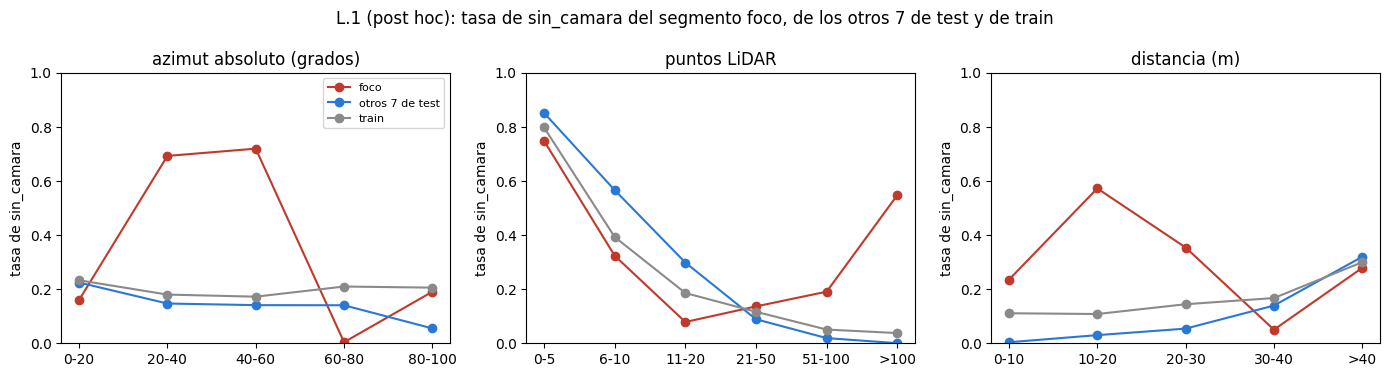


AUC por segmento de test con >= 50 positivos:
    segmento  filas  positivos  tasa  AUC regla top  AUC regresion logistica
141430544948   1654        256 0.155          0.967                    0.978
221704303323   4653        918 0.197          0.937                    0.933
257766998801   6474       2046 0.316          0.443                    0.459
645616575015   1710        445 0.260          0.870                    0.836

Mediana de puntos LiDAR por grupo:
                 mediana de puntos con par  mediana de puntos sin par
grupo                                                                
foco                                  36.5                       72.0
otros 7 de test                       61.0                        6.0
train                                 49.0                        5.0


**Lectura (generada, hipótesis).** El segmento foco tiene 6.474 filas y una tasa de `sin_camara` de 31,6 %, frente a 17,6 % en los otros 7 segmentos de test y 20,7 % en train. La mediana de puntos LiDAR de sus cajas sin par es 72 y la de las cajas con par 36 (en los otros 7: 6 y 61; en train: 5 y 49). Entre las cajas con 0 a 5 puntos, la tasa de `sin_camara` es 74,8 % en el foco, 85,1 % en los otros 7 y 79,7 % en train. AUC dentro del segmento: regla por puntos top 0,443 y regresión logística 0,459; en los otros segmentos de test con al menos 50 positivos va de 0,870 a 0,967 (regla top).

In [18]:
def tabla_bins(col, bins, labels):
    b = pd.cut(GL[col], bins=bins, labels=labels, include_lowest=True)
    t = GL.assign(_b=b).groupby(["_b", "grupo"], observed=False)["sin_camara"].agg(["mean", "size"]).unstack("grupo")
    t = t.reindex(columns=pd.MultiIndex.from_product([["mean", "size"], ORD]))
    t.columns = [f"{'tasa' if a == 'mean' else 'n'} | {g}" for a, g in t.columns]
    return t


AZ_B = tabla_bins("azimut_abs_deg", [0, 20, 40, 60, 80, 100], ["0-20", "20-40", "40-60", "60-80", "80-100"])
PT_B = tabla_bins("num_lidar_points", [-1, 5, 10, 20, 50, 100, np.inf], ["0-5", "6-10", "11-20", "21-50", "51-100", ">100"])
DI_B = tabla_bins("distancia_m", [0, 10, 20, 30, 40, np.inf], ["0-10", "10-20", "20-30", "30-40", ">40"])
CL_B = GL.groupby(["clase", "grupo"])["sin_camara"].agg(["mean", "size"]).unstack("grupo").reindex(columns=pd.MultiIndex.from_product([["mean", "size"], ORD]))
CL_B.columns = [f"{'tasa' if a == 'mean' else 'n'} | {g}" for a, g in CL_B.columns]
for nom, t in (("azimut (grados, valor absoluto)", AZ_B), ("puntos LiDAR", PT_B), ("distancia (m)", DI_B), ("clase", CL_B)):
    print(f"\nTasa de sin_camara por {nom}:")
    print(t.round(3).to_string())
TL = pd.concat({"azimut": AZ_B, "puntos": PT_B, "distancia": DI_B, "clase": CL_B}, names=["variable", "bin"])
guardar_csv(TL, "10_L_tasas")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, t, tit in zip(axes, (AZ_B, PT_B, DI_B), ("azimut absoluto (grados)", "puntos LiDAR", "distancia (m)")):
    for g, c in zip(ORD, (ROJO, AZUL, GRIS)):
        ax.plot(range(len(t)), t[f"tasa | {g}"].values, marker="o", color=c, label=g)
    ax.set_xticks(range(len(t)), t.index.astype(str)); ax.set_title(tit); ax.set_ylabel("tasa de sin_camara"); ax.set_ylim(0, 1)
axes[0].legend(fontsize=8)
fig.suptitle("L.1 (post hoc): tasa de sin_camara del segmento foco, de los otros 7 de test y de train")
fig.tight_layout()
guardar_fig(fig, "10_L_tasas")
plt.show()

# ---- AUC por segmento de test (solo con >= 50 positivos): regla por puntos top y regresion logistica
filas = []
for sg in evaluables:
    m_ = (pop_p[GRUPO] == sg).values
    yy_ = POB_P["y"][m_]
    filas.append({"segmento": sg[:12], "filas": int(m_.sum()), "positivos": int(yy_.sum()), "tasa": yy_.mean(), "AUC regla top": roc_auc_score(yy_, SC_P[N_TOP][m_]), "AUC regresion logistica": roc_auc_score(yy_, SC_P[N_LR][m_])})
t_aucL = pd.DataFrame(filas)
print("\nAUC por segmento de test con >= 50 positivos:")
print(t_aucL.round(3).to_string(index=False))
guardar_csv(t_aucL, "10_L_auc_segmentos_test", indice=False)
fo = res_g.loc["foco"]
ot = res_g.loc["otros 7 de test"]
tr_ = res_g.loc["train"]
af = t_aucL[t_aucL["segmento"] == FOCO_ID]
RL["auc_foco"] = {"top": float(af["AUC regla top"].iloc[0]) if len(af) else np.nan, "lr": float(af["AUC regresion logistica"].iloc[0]) if len(af) else np.nan}
RL["auc_otros"] = {"top": t_aucL.loc[t_aucL["segmento"] != FOCO_ID, "AUC regla top"].tolist(), "lr": t_aucL.loc[t_aucL["segmento"] != FOCO_ID, "AUC regresion logistica"].tolist()}
RL["tasas"] = {"foco": float(fo["tasa"]), "otros": float(ot["tasa"]), "train": float(tr_["tasa"])}
# tasa por puntos: mas o menos puntos en las cajas sin par y con par, por grupo
med = GL.groupby(["grupo", "sin_camara"])["num_lidar_points"].median().unstack().loc[ORD]
med.columns = ["mediana de puntos con par", "mediana de puntos sin par"]
print("\nMediana de puntos LiDAR por grupo:")
print(med.to_string())
RL["med_puntos"] = med.to_dict("index")
bajo = PT_B.loc["0-5"]
display(Markdown(
    f"**Lectura (generada, hipótesis).** El segmento foco tiene {miles(fo['filas'])} filas y una tasa de `sin_camara` de {pct(fo['tasa'])}, frente a {pct(ot['tasa'])} en los otros {int(ot['segmentos'])} segmentos de test y {pct(tr_['tasa'])} en train. "
    f"La mediana de puntos LiDAR de sus cajas sin par es {med.loc['foco', 'mediana de puntos sin par']:.0f} y la de las cajas con par {med.loc['foco', 'mediana de puntos con par']:.0f} (en los otros 7: {med.loc['otros 7 de test', 'mediana de puntos sin par']:.0f} y {med.loc['otros 7 de test', 'mediana de puntos con par']:.0f}; en train: {med.loc['train', 'mediana de puntos sin par']:.0f} y {med.loc['train', 'mediana de puntos con par']:.0f}). "
    f"Entre las cajas con 0 a 5 puntos, la tasa de `sin_camara` es {pct(bajo['tasa | foco'])} en el foco, {pct(bajo['tasa | otros 7 de test'])} en los otros 7 y {pct(bajo['tasa | train'])} en train. "
    f"AUC dentro del segmento: regla por puntos top {n3(RL['auc_foco']['top'])} y regresión logística {n3(RL['auc_foco']['lr'])}; en los otros segmentos de test con al menos 50 positivos va de {n3(min(RL['auc_otros']['top']))} a {n3(max(RL['auc_otros']['top']))} (regla top)."))

## L.2 Cámaras: pares por cámara en ese segmento (solo descripción)

Con los archivos locales `camera_to_lidar_box_association` de cada segmento (no hay `camera_calibration`, así que los rangos de azimut por cámara son los **empíricos** del 08, no calibración). Para cada caja de la población principal se mira en qué cámaras tiene par. La regla de lectura (fijada acá antes de mirar la tabla): una cámara tiene "muchos menos pares" en el foco si, entre las cajas cuyo azimut cae en el rango empírico de esa cámara, la proporción con par en el foco es menos de la mitad que en los otros 7 de test.

Camaras (rango empirico de azimut con signo, p1 a p99): {1: (-23.3, 23.2), 2: (18.9, 66.8), 3: (-63.6, -17.1), 4: (60.8, 111.6), 5: (-109.5, -52.4)}
Segmentos sin archivo de asociacion local: 0


Coincidencia entre 'tiene par en alguna camara' y 'sin_camara = 0': 1.0000 (80,571 cajas)

% de cajas con par, por camara:
                  segmento  cajas  1 (frontal)  2 (frontal izq.)  3 (frontal der.)  4 (lateral izq.)  5 (lateral der.)  alguna camara
         foco 257766998801   6474        0.563             0.048             0.000             0.011             0.072          0.684
              102124064984    851        0.736             0.244             0.059             0.065             0.024          0.944
              141430544948   1654        0.663             0.020             0.239             0.000             0.056          0.845
              167359384489    196        0.719             0.235             0.000             0.102             0.000          0.990
              221704303323   4653        0.378             0.299             0.086             0.112             0.036          0.803
              497181704156    369        0.740             0.000         

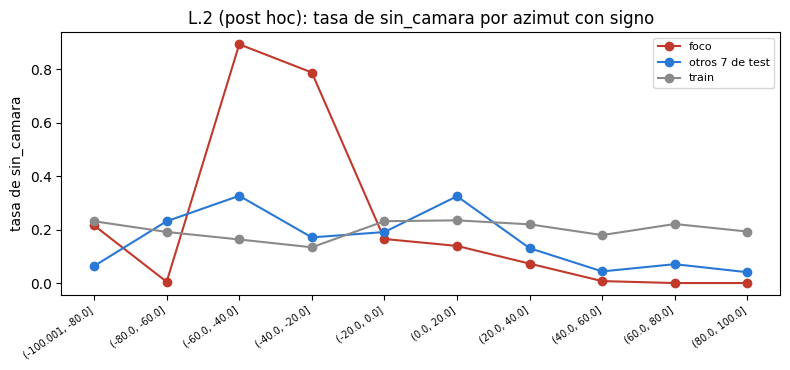

**Lectura (generada, hipótesis).** La asociación local reproduce `sin_camara` en el 100,00 % de las cajas. Con la regla fijada antes de mirar (proporción con par en el rango de la cámara, foco menos de la mitad que los otros 7), **hay cámara(s) con muchos menos pares en el foco: 3 (frontal der.)**. Las cajas sin par del foco se concentran en el rango de 3 (frontal der.): el 66 % de ellas cae ahí (otros 7: 18 %; train: 14 %), y dentro de ese rango el 64 % de las cajas del foco no tiene par en ninguna cámara (otros 7: 18 %; train: 14 %). Los rangos de azimut son empíricos (del 08), no calibración, y los rangos de las cámaras se solapan; esto es descripción y no permite afirmar la causa.

In [19]:
RAW_A = RAIZ / "data" / "01_raw" / "waymo" / "camera_to_lidar_box_association"
cam_csv = pd.read_csv(RUTA_REP / "08_azimut_por_camara_empirico.csv")
CAM = {int(str(r["camara"]).split()[0]): {"nombre": str(r["camara"]), "lo": float(r["azimut p1"]), "hi": float(r["p99"])} for _, r in cam_csv.iterrows()}
CAMS = sorted(CAM)
faltan_arch = [s for s in GL["segment_id"].unique() if not (RAW_A / f"{s}.parquet").exists()]
print("Camaras (rango empirico de azimut con signo, p1 a p99):", {k: (round(v["lo"], 1), round(v["hi"], 1)) for k, v in CAM.items()})
print("Segmentos sin archivo de asociacion local:", len(faltan_arch))
PAR_OK = len(faltan_arch) == 0
if PAR_OK:
    partes_ = []
    for s, d in GL.groupby("segment_id", sort=False):
        a = pd.read_parquet(RAW_A / f"{s}.parquet", columns=["key.frame_timestamp_micros", "key.camera_name", "key.laser_object_id"]).drop_duplicates()
        k = a.assign(v=1).pivot_table(index=["key.frame_timestamp_micros", "key.laser_object_id"], columns="key.camera_name", values="v", aggfunc="max", fill_value=0)
        k = k.reindex(columns=CAMS, fill_value=0)
        k.columns = [f"c{c}" for c in CAMS]
        partes_.append(d.merge(k.reset_index(), on=["key.frame_timestamp_micros", "key.laser_object_id"], how="left"))
    GC = pd.concat(partes_, ignore_index=True)
    for c in CAMS:
        GC[f"c{c}"] = GC[f"c{c}"].fillna(0).astype(int)
    GC["alguna"] = (GC[[f"c{c}" for c in CAMS]].sum(axis=1) > 0).astype(int)
    acuerdo = float(((GC["alguna"] == 1) == (GC["sin_camara"] == 0)).mean())
    print(f"Coincidencia entre 'tiene par en alguna camara' y 'sin_camara = 0': {acuerdo:.4f} ({len(GC):,} cajas)")
    GC["seg12"] = GC["segment_id"].str[:12]
    # tabla 1: % de cajas con par por camara (todas las cajas del grupo)
    filas = []
    for etiqueta, m_ in [(f"foco {FOCO_ID}", GC["grupo"] == "foco")] + [(s, GC["seg12"] == s) for s in sorted(GC.loc[GC["grupo"] == "otros 7 de test", "seg12"].unique())] + [("otros 7 de test (agrupado)", GC["grupo"] == "otros 7 de test"), ("train (agrupado)", GC["grupo"] == "train")]:
        d = GC[m_]
        f_ = {"segmento": etiqueta, "cajas": len(d)}
        for c in CAMS:
            f_[CAM[c]["nombre"]] = d[f"c{c}"].mean()
        f_["alguna camara"] = d["alguna"].mean()
        filas.append(f_)
    T_CAM = pd.DataFrame(filas)
    print("\n% de cajas con par, por camara:")
    print(T_CAM.round(3).to_string(index=False))
    guardar_csv(T_CAM, "10_L_camaras_pares", indice=False)
    # tabla 2: dentro del rango empirico de cada camara, % con par en esa camara
    filas, ratio = [], {}
    for c in CAMS:
        en = (GC["az_signed"] >= CAM[c]["lo"]) & (GC["az_signed"] <= CAM[c]["hi"])
        f_ = {"camara": CAM[c]["nombre"], "rango": f"{CAM[c]['lo']:.0f} a {CAM[c]['hi']:.0f}"}
        for g in ORD:
            d = GC[en & (GC["grupo"] == g)]
            f_[f"% con par en la camara | {g}"] = d[f"c{c}"].mean() if len(d) else np.nan
            f_[f"cajas en rango | {g}"] = len(d)
            f_[f"% sin par en alguna camara de las cajas del rango | {g}"] = (1 - d["alguna"].mean()) if len(d) else np.nan
            sp = GC[(GC["grupo"] == g) & (GC["sin_camara"] == 1)]
            f_[f"% de las cajas sin par que caen en este rango | {g}"] = ((sp["az_signed"] >= CAM[c]["lo"]) & (sp["az_signed"] <= CAM[c]["hi"])).mean() if len(sp) else np.nan
        ratio[c] = f_["% con par en la camara | foco"] / f_["% con par en la camara | otros 7 de test"] if f_["% con par en la camara | otros 7 de test"] > 0 else np.nan
        f_["razon foco / otros 7"] = ratio[c]
        filas.append(f_)
    T_CAM_R = pd.DataFrame(filas)
    print("\nDentro del rango de azimut de cada camara:")
    print(T_CAM_R.round(3).T.to_string())
    guardar_csv(T_CAM_R, "10_L_camaras_en_rango", indice=False)
    cam_baja = [CAM[c]["nombre"] for c, r in ratio.items() if r == r and r < 0.5]
    # tabla 3: tasa de sin_camara por azimut con signo (bins de 20 grados) en foco, otros 7 y train
    AZS = GC.assign(_b=pd.cut(GC["az_signed"], [-100, -80, -60, -40, -20, 0, 20, 40, 60, 80, 100], include_lowest=True)).groupby(["_b", "grupo"], observed=False)["sin_camara"].agg(["mean", "size"]).unstack("grupo")
    AZS = AZS.reindex(columns=pd.MultiIndex.from_product([["mean", "size"], ORD]))
    AZS.columns = [f"{'tasa' if a == 'mean' else 'n'} | {g}" for a, g in AZS.columns]
    print("\nTasa de sin_camara por azimut con signo (bins de 20 grados):")
    print(AZS.round(3).to_string())
    guardar_csv(AZS, "10_L_tasa_azimut_con_signo")
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for g, c in zip(ORD, (ROJO, AZUL, GRIS)):
        ax.plot(range(len(AZS)), AZS[f"tasa | {g}"].values, marker="o", color=c, label=g)
    ax.set_xticks(range(len(AZS)), [str(i) for i in AZS.index], rotation=35, ha="right", fontsize=7); ax.set_ylabel("tasa de sin_camara"); ax.set_title("L.2 (post hoc): tasa de sin_camara por azimut con signo"); ax.legend(fontsize=8)
    fig.tight_layout()
    guardar_fig(fig, "10_L_azimut_con_signo")
    plt.show()
    RL["camaras"] = {"acuerdo": acuerdo, "baja": cam_baja, "ratio": {CAM[c]["nombre"]: ratio[c] for c in ratio}}
    mx_c = min(ratio, key=lambda c: ratio[c] if ratio[c] == ratio[c] else 9)
    cmax = max(CAMS, key=lambda c: T_CAM_R.loc[T_CAM_R["camara"] == CAM[c]["nombre"], "% de las cajas sin par que caen en este rango | foco"].iloc[0])
    rowc = T_CAM_R[T_CAM_R["camara"] == CAM[cmax]["nombre"]].iloc[0]
    RL["camaras"]["cam_max"] = CAM[cmax]["nombre"]
    RL["camaras"]["en_rango_foco"] = float(rowc["% de las cajas sin par que caen en este rango | foco"])
    display(Markdown(
        f"**Lectura (generada, hipótesis).** La asociación local reproduce `sin_camara` en el {pct(acuerdo, 2)} de las cajas. "
        + (f"Con la regla fijada antes de mirar (proporción con par en el rango de la cámara, foco menos de la mitad que los otros 7), **hay cámara(s) con muchos menos pares en el foco: {', '.join(cam_baja)}**. " if cam_baja else
           f"Con la regla fijada antes de mirar (proporción con par en el rango de la cámara, foco menos de la mitad que los otros 7), **ninguna cámara tiene muchos menos pares en el foco**; la razón más baja es {str(round(ratio[mx_c], 2)).replace('.', ',')} ({CAM[mx_c]['nombre']}). ")
        + f"Las cajas sin par del foco se concentran en el rango de {CAM[cmax]['nombre']}: el {pct(rowc['% de las cajas sin par que caen en este rango | foco'], 0)} de ellas cae ahí (otros 7: {pct(rowc['% de las cajas sin par que caen en este rango | otros 7 de test'], 0)}; train: {pct(rowc['% de las cajas sin par que caen en este rango | train'], 0)}), y dentro de ese rango el {pct(rowc['% sin par en alguna camara de las cajas del rango | foco'], 0)} de las cajas del foco no tiene par en ninguna cámara (otros 7: {pct(rowc['% sin par en alguna camara de las cajas del rango | otros 7 de test'], 0)}; train: {pct(rowc['% sin par en alguna camara de las cajas del rango | train'], 0)}). "
        "Los rangos de azimut son empíricos (del 08), no calibración, y los rangos de las cámaras se solapan; esto es descripción y no permite afirmar la causa."))
else:
    RL["camaras"] = {"acuerdo": None, "baja": None}
    display(Markdown("**No se puede hacer L.2:** faltan archivos locales de asociación de cámara para " + str(len(faltan_arch)) + " segmentos; no se cargan datos que no estén ya en local."))

## L.3 Cajas sin par que están bien observadas

In [20]:
filas = []
for g in ORD:
    d = GL[GL["grupo"] == g]
    sp = d[d["sin_camara"] == 1]
    mucho = d[d["num_lidar_points"] >= 100]
    filas.append({"grupo": g, "cajas sin par": len(sp), "sin par con >= 100 puntos": int((sp["num_lidar_points"] >= 100).sum()), "% de las sin par": (sp["num_lidar_points"] >= 100).mean(),
                  "sin par con <= 5 puntos": int((sp["num_lidar_points"] <= 5).sum()), "% de las sin par (<= 5 puntos)": (sp["num_lidar_points"] <= 5).mean(),
                  "cajas con >= 100 puntos": len(mucho), "tasa de sin par entre cajas con >= 100 puntos": mucho["sin_camara"].mean()})
T_MUCHOS = pd.DataFrame(filas).set_index("grupo")
print(T_MUCHOS.round(3).to_string())
guardar_csv(T_MUCHOS, "10_L_sin_par_bien_observadas")
RL["muchos"] = T_MUCHOS.to_dict("index")
mf, mo, mt = T_MUCHOS.loc["foco"], T_MUCHOS.loc["otros 7 de test"], T_MUCHOS.loc["train"]
display(Markdown(
    f"**Lectura (generada, hipótesis).** En el segmento foco, {miles(mf['sin par con >= 100 puntos'])} de {miles(mf['cajas sin par'])} cajas sin par ({pct(mf['% de las sin par'])}) tienen al menos 100 puntos LiDAR; en los otros 7 segmentos de test son {miles(mo['sin par con >= 100 puntos'])} de {miles(mo['cajas sin par'])} ({pct(mo['% de las sin par'])}) y en train {miles(mt['sin par con >= 100 puntos'])} de {miles(mt['cajas sin par'])} ({pct(mt['% de las sin par'])}). "
    f"Entre las cajas con al menos 100 puntos, la tasa de `sin_camara` es {pct(mf['tasa de sin par entre cajas con >= 100 puntos'])} en el foco, {pct(mo['tasa de sin par entre cajas con >= 100 puntos'])} en los otros 7 y {pct(mt['tasa de sin par entre cajas con >= 100 puntos'])} en train. Las sin par con 5 puntos o menos son el {pct(mf['% de las sin par (<= 5 puntos)'])} en el foco, {pct(mo['% de las sin par (<= 5 puntos)'])} en los otros 7 y {pct(mt['% de las sin par (<= 5 puntos)'])} en train."))

                 cajas sin par  sin par con >= 100 puntos  % de las sin par  sin par con <= 5 puntos  % de las sin par (<= 5 puntos)  cajas con >= 100 puntos  tasa de sin par entre cajas con >= 100 puntos
grupo                                                                                                                                                                                                       
foco                      2046                        936             0.457                      439                           0.215                     1708                                          0.548
otros 7 de test           1688                          1             0.001                      800                           0.474                     2760                                          0.000
train                    13368                        583             0.044                     6954                           0.520                    15459                       

**Lectura (generada, hipótesis).** En el segmento foco, 936 de 2.046 cajas sin par (45,7 %) tienen al menos 100 puntos LiDAR; en los otros 7 segmentos de test son 1 de 1.688 (0,1 %) y en train 583 de 13.368 (4,4 %). Entre las cajas con al menos 100 puntos, la tasa de `sin_camara` es 54,8 % en el foco, 0,0 % en los otros 7 y 3,8 % en train. Las sin par con 5 puntos o menos son el 21,5 % en el foco, 47,4 % en los otros 7 y 52,0 % en train.

## L.4 Segmentos de train con AUC bajo de la regla por puntos top

In [21]:
from scipy.stats import spearmanr
filas = []
for s, d in trn.groupby("segment_id"):
    yy_ = d["sin_camara"].values
    pos = d[d["sin_camara"] == 1]
    filas.append({"segmento": s[:12], "ubicacion": d["location"].iloc[0], "momento": d["time_of_day"].iloc[0], "filas": len(d), "positivos": int(yy_.sum()), "% sin_camara": yy_.mean(),
                  "AUC regla top": roc_auc_score(yy_, -d["num_top_lidar_points"].values) if len(np.unique(yy_)) > 1 else np.nan, "% de positivos con >= 100 puntos": (pos["num_lidar_points"] >= 100).mean() if len(pos) else np.nan})
T_TR = pd.DataFrame(filas).sort_values("AUC regla top")
bajos = T_TR[T_TR["AUC regla top"] < 0.55]
T_TR["positivos >= 50"] = T_TR["positivos"] >= 50
bajos50 = bajos[bajos["positivos"] >= 50]
ok50 = T_TR[(T_TR["positivos"] >= 50) & ~(T_TR["AUC regla top"] < 0.55)]
print(f"Segmentos de train (poblacion principal): {len(T_TR)}; con AUC de la regla top < 0,55: {len(bajos)} (de ellos con >= 50 positivos: {len(bajos50)})")
print(T_TR.round(3).to_string(index=False))
guardar_csv(T_TR, "10_L_train_segmentos", indice=False)
t50 = T_TR[T_TR["positivos"] >= 50]
rho = spearmanr(t50["AUC regla top"], t50["% de positivos con >= 100 puntos"], nan_policy="omit")
RL["train_bajos"] = {"n": int(len(bajos)), "n50": int(len(bajos50)), "segmentos": bajos["segmento"].tolist(), "segmentos50": bajos50["segmento"].tolist(), "rho": float(rho.correlation), "p": float(rho.pvalue), "n_total": int(len(T_TR)), "n_total50": int(len(t50))}
cols_c = ["% sin_camara", "% de positivos con >= 100 puntos", "positivos", "filas"]
if len(bajos50):
    comp_ = pd.DataFrame({"AUC < 0,55 (>= 50 positivos)": bajos50[cols_c].median(), "resto (>= 50 positivos)": ok50[cols_c].median()})
    print("\nMedianas (solo segmentos con >= 50 positivos):")
    print(comp_.round(3).to_string())
    guardar_csv(comp_, "10_L_train_comun")
    print("Ubicacion de los de AUC bajo:", bajos50["ubicacion"].value_counts().to_dict(), "| momento:", bajos50["momento"].value_counts().to_dict())
    print("Ubicacion del resto:", ok50["ubicacion"].value_counts().to_dict(), "| momento:", ok50["momento"].value_counts().to_dict())
    RL["train_bajos"]["med"] = comp_.to_dict()
    RL["train_bajos"]["ubic"] = bajos50["ubicacion"].value_counts().to_dict()
    RL["train_bajos"]["mom"] = bajos50["momento"].value_counts().to_dict()
foco_pos100 = float(T_MUCHOS.loc["foco", "% de las sin par"])
display(Markdown(
    f"**Lectura (generada, descriptiva).** De {len(T_TR)} segmentos de train, {len(bajos)} tienen AUC de la regla por puntos top menor que 0,55; {len(bajos50)} de ellos con al menos 50 positivos (los demás tienen muy pocos positivos y su AUC es poco confiable)" +
    (": " + "; ".join(f"{r['segmento']} ({r['ubicacion']}, {r['momento']}, AUC {n3(r['AUC regla top'])}, {pct(r['% sin_camara'])} sin_camara, {int(r['positivos'])} positivos, {pct(r['% de positivos con >= 100 puntos'], 0)} de los positivos con ≥ 100 puntos)" for _, r in bajos50.iterrows()) + ". " if len(bajos50) else ". ") +
    (f"Entre los segmentos de AUC bajo con al menos 50 positivos, la mediana del % de positivos con al menos 100 puntos es {pct(comp_.iloc[1, 0], 0)} frente a {pct(comp_.iloc[1, 1], 0)} en el resto con al menos 50 positivos, y la mediana de % sin_camara es {pct(comp_.iloc[0, 0])} frente a {pct(comp_.iloc[0, 1])}. " if len(bajos50) else "") +
    f"Entre los {len(t50)} segmentos de train con al menos 50 positivos, la correlación de Spearman entre el AUC de la regla top y el % de positivos con ≥ 100 puntos es {n3(rho.correlation, True)} (p = {str(round(rho.pvalue, 3)).replace('.', ',')}). Para comparar: el segmento foco tiene {pct(foco_pos100, 0)} de sus positivos con ≥ 100 puntos."))

Segmentos de train (poblacion principal): 33; con AUC de la regla top < 0,55: 2 (de ellos con >= 50 positivos: 1)
    segmento      ubicacion   momento  filas  positivos  % sin_camara  AUC regla top  % de positivos con >= 100 puntos  positivos >= 50
911012534050    location_sf       Day   1715        316         0.184          0.408                             0.617             True
102062935203   location_phx     Night    155          2         0.013          0.449                             0.000            False
932016928997    location_sf     Night    513         97         0.189          0.661                             0.000             True
364414530703 location_other Dawn/Dusk    975         49         0.050          0.691                             0.000            False
247562357599    location_sf Dawn/Dusk   4218       1030         0.244          0.704                             0.180             True
121745297692   location_phx       Day   2688        160         0.060 

**Lectura (generada, descriptiva).** De 33 segmentos de train, 2 tienen AUC de la regla por puntos top menor que 0,55; 1 de ellos con al menos 50 positivos (los demás tienen muy pocos positivos y su AUC es poco confiable): 911012534050 (location_sf, Day, AUC 0,408, 18,4 % sin_camara, 316 positivos, 62 % de los positivos con ≥ 100 puntos). Entre los segmentos de AUC bajo con al menos 50 positivos, la mediana del % de positivos con al menos 100 puntos es 62 % frente a 1 % en el resto con al menos 50 positivos, y la mediana de % sin_camara es 18,4 % frente a 21,7 %. Entre los 22 segmentos de train con al menos 50 positivos, la correlación de Spearman entre el AUC de la regla top y el % de positivos con ≥ 100 puntos es -0,425 (p = 0,049). Para comparar: el segmento foco tiene 46 % de sus positivos con ≥ 100 puntos.

## L.5 Resultado sin el segmento 257766998801 (7 segmentos)

> **No reemplaza el resultado pre-declarado.** Es el mismo análisis de las secciones B y D repetido sin el segmento foco, solo para ver cuánto depende de él. Los umbrales siguen siendo los congelados con train; no se mueve nada. Los IC son por bootstrap de los 7 segmentos que quedan.

Comparacion principal, oficial y sin el segmento:
                    resultado                  metodo  filas                   AUC                PR-AUC           Captura@20%     Fraccion para 80%
        oficial (8 segmentos)     Regresion logistica  16062 0.698 (0.503 a 0.961) 0.565 (0.451 a 0.826) 0.517 (0.364 a 0.887) 0.774 (0.154 a 0.884)
        oficial (8 segmentos) Regla: menos puntos top  16062 0.684 (0.482 a 0.958) 0.558 (0.430 a 0.795) 0.503 (0.346 a 0.875) 0.790 (0.148 a 0.883)
sin el segmento (7 segmentos)     Regresion logistica   9588 0.927 (0.880 a 0.990) 0.729 (0.680 a 0.866) 0.743 (0.625 a 0.998) 0.234 (0.081 a 0.368)
sin el segmento (7 segmentos) Regla: menos puntos top   9588 0.931 (0.897 a 0.982) 0.750 (0.692 a 0.820) 0.758 (0.670 a 0.973) 0.221 (0.083 a 0.311)

Sin el segmento: Regresion logistica menos Regla: menos puntos top: dAUC -0.004 (IC -0.019 a +0.011) | dFraccion80 +1,3 puntos (IC -0,8 a +7,2) | vale la pena: False | IC con 0 en ambas: True



Puntos de operacion A y B (umbrales congelados):
                                 metodo punto        recall oficial recall sin el segmento     precision oficial precision sin el segmento   % a revisar oficial % a revisar sin el segmento A sostenido (oficial | sin el segmento)
              Regla: menos puntos LiDAR     A 0.593 (0.387 a 0.931)  0.882 (0.859 a 0.966) 0.405 (0.297 a 0.555)     0.503 (0.326 a 0.572) 0.340 (0.246 a 0.410)       0.309 (0.211 a 0.432)                                 no | si
              Regla: menos puntos LiDAR     B 0.468 (0.329 a 0.781)  0.672 (0.613 a 0.846) 0.658 (0.559 a 0.791)     0.741 (0.639 a 0.803) 0.166 (0.127 a 0.206)       0.160 (0.090 a 0.226)                                       -
                Regla: menos puntos top     A 0.590 (0.383 a 0.924)  0.879 (0.858 a 0.967) 0.414 (0.303 a 0.567)     0.516 (0.347 a 0.586) 0.331 (0.238 a 0.397)       0.300 (0.202 a 0.419)                                 no | si
                Regla: menos punto

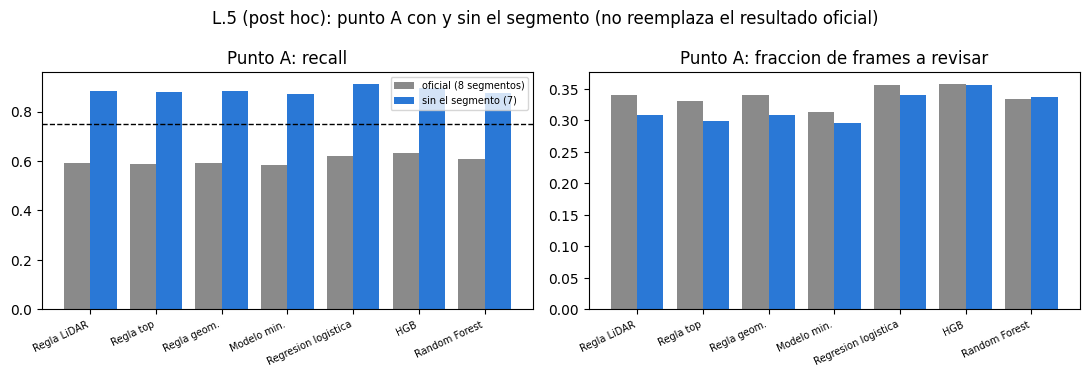

**Lectura (generada; diagnóstico post hoc, no reemplaza el resultado pre-declarado).** Sin el segmento foco (7 segmentos, 9.588 filas), Regresion logistica tiene AUC 0,927 y Regla: menos puntos top 0,931; la diferencia de AUC es -0,004 (IC -0,019 a +0,011) y la de Fracción para 80 % +1,3 puntos (IC -0,8 a +7,2); 'vale la pena' no se cumple y ambos IC incluyen 0 (no se distingue). Punto A de Regresion logistica: recall 0,913 (IC 0,894 a 0,995), se sostiene (oficial: 0,621); de Regla: menos puntos top: recall 0,879 (oficial: 0,590), se sostiene. Con el segmento afuera, 7 de 7 métodos sostienen el punto A (oficial: 0).

In [22]:
msk7 = (pop_p[GRUPO] != foco).values
d7 = pop_p[msk7].reset_index(drop=True)
POB7 = poblacion(d7)
SC7 = {n: SC_P[n][msk7] for n in METODOS}
t0 = time.time()
p7, b7 = boot(SC7, POB7, n_boot=1000)
vlp7, dA7, dF7 = vale_la_pena(p7, b7, MOD, BASE)
no_dist7 = bool(dA7[1] <= 0 <= dA7[2] and dF7[1] <= 0 <= dF7[2])
filas = []
for etiqueta, pp, bb, nseg, nfil in (("oficial (8 segmentos)", punto_p, b_p, POB_P["n_seg"], len(pop_p)), ("sin el segmento (7 segmentos)", p7, b7, POB7["n_seg"], len(d7))):
    for n in (MOD, BASE):
        f_ = {"resultado": etiqueta, "metodo": n, "filas": nfil}
        for m in MET:
            lo, hi = ic(bb[n][m])
            f_[m] = f"{pp[n][m]:.3f} ({lo:.3f} a {hi:.3f})"
        filas.append(f_)
T7 = pd.DataFrame(filas)
print("Comparacion principal, oficial y sin el segmento:")
print(T7.to_string(index=False))
guardar_csv(T7, "10_L_sin_segmento_principal", indice=False)
print(f"\nSin el segmento: {MOD} menos {BASE}: dAUC {dA7[0]:+.3f} (IC {dA7[1]:+.3f} a {dA7[2]:+.3f}) | dFraccion80 {pts(dF7[0] * 100)} puntos (IC {pts(dF7[1] * 100)} a {pts(dF7[2] * 100)}) | vale la pena: {vlp7} | IC con 0 en ambas: {no_dist7}")
# ---- puntos A y B de los 7 metodos, oficial y sin el segmento
filas = []
OP7 = {}
for n in METODOS:
    for p in ("A", "B"):
        fl = FLAGS[n][p][msk7]
        m = flags_y_metricas(fl, POB7["y"])
        bb = boot_flags(fl, POB7, n_boot=1000)
        OP7[(n, p)] = {k: (m[k], *ic(bb[k])) for k in ("recall", "precision", "pct_revisar")}
        o = OP[(n, p)]
        f_ = {"metodo": n, "punto": p}
        for k, nom in (("recall", "recall"), ("precision", "precision"), ("pct_revisar", "% a revisar")):
            f_[f"{nom} oficial"] = f"{o[k][0]:.3f} ({o[k][1]:.3f} a {o[k][2]:.3f})"
            f_[f"{nom} sin el segmento"] = f"{OP7[(n, p)][k][0]:.3f} ({OP7[(n, p)][k][1]:.3f} a {OP7[(n, p)][k][2]:.3f})"
        f_["A sostenido (oficial | sin el segmento)"] = (f"{'si' if o['recall'][0] >= TOL_A else 'no'} | {'si' if OP7[(n, p)]['recall'][0] >= TOL_A else 'no'}") if p == "A" else "-"
        filas.append(f_)
T7op = pd.DataFrame(filas)
print("\nPuntos de operacion A y B (umbrales congelados):")
print(T7op.to_string(index=False))
guardar_csv(T7op, "10_L_sin_segmento_operacion", indice=False)
TIEMPO_L5 = time.time() - t0
sost7 = {n: bool(OP7[(n, "A")]["recall"][0] >= TOL_A) for n in METODOS}
RL["sin_foco"] = {"dA": dA7, "dF": dF7, "vlp": vlp7, "no_dist": no_dist7, "auc": {n: p7[n]["AUC"] for n in (MOD, BASE)}, "f80": {n: p7[n]["Fraccion para 80%"] for n in (MOD, BASE)},
                  "recall_A": {n: OP7[(n, "A")]["recall"] for n in METODOS}, "sostenido": sost7, "pct_A": {n: OP7[(n, "A")]["pct_revisar"] for n in METODOS}}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, k, tit in zip(axes, ("recall", "pct_revisar"), ("recall", "fraccion de frames a revisar")):
    x = np.arange(len(METODOS))
    ax.bar(x - 0.2, [OP[(n, "A")][k][0] for n in METODOS], 0.4, color=GRIS, label="oficial (8 segmentos)")
    ax.bar(x + 0.2, [OP7[(n, "A")][k][0] for n in METODOS], 0.4, color=AZUL, label="sin el segmento (7)")
    ax.set_xticks(x, [m.replace("Regla geometrica (azimut > 105 primero)", "Regla geom.").replace("Modelo minimo (LR 3 variables)", "Modelo min.").replace("Regla: menos puntos ", "Regla ") for m in METODOS], rotation=25, ha="right", fontsize=7); ax.set_title(f"Punto A: {tit}")
axes[0].axhline(TOL_A, color="k", ls="--", lw=1); axes[0].legend(fontsize=7)
fig.suptitle("L.5 (post hoc): punto A con y sin el segmento (no reemplaza el resultado oficial)")
fig.tight_layout()
guardar_fig(fig, "10_L_sin_segmento")
plt.show()
rr = RL["sin_foco"]["recall_A"]
display(Markdown(
    f"**Lectura (generada; diagnóstico post hoc, no reemplaza el resultado pre-declarado).** Sin el segmento foco ({POB7['n_seg']} segmentos, {miles(len(d7))} filas), {MOD} tiene AUC {n3(p7[MOD]['AUC'])} y {BASE} {n3(p7[BASE]['AUC'])}; la diferencia de AUC es {n3(dA7[0], True)} (IC {n3(dA7[1], True)} a {n3(dA7[2], True)}) y la de Fracción para 80 % {pts(dF7[0] * 100)} puntos (IC {pts(dF7[1] * 100)} a {pts(dF7[2] * 100)}); 'vale la pena' {'se cumple' if vlp7 else 'no se cumple'}" +
    (" y ambos IC incluyen 0 (no se distingue)." if no_dist7 else ".") +
    f" Punto A de {MOD}: recall {n3(rr[MOD][0])} (IC {n3(rr[MOD][1])} a {n3(rr[MOD][2])}), {'se sostiene' if sost7[MOD] else 'no se sostiene'} (oficial: {n3(OP[(MOD, 'A')]['recall'][0])}); de {BASE}: recall {n3(rr[BASE][0])} (oficial: {n3(OP[(BASE, 'A')]['recall'][0])}), {'se sostiene' if sost7[BASE] else 'no se sostiene'}. "
    f"Con el segmento afuera, {sum(sost7.values())} de {len(METODOS)} métodos sostienen el punto A (oficial: {sum(RES['D']['sostenido'].values())})."))

## L.6 Conclusión del apéndice (hipótesis)

**Regla fijada acá, antes de leer los números:** se considera que las cajas sin par del foco son "sobre todo objetos bien observados" si (i) la proporción de sus cajas sin par con al menos 100 puntos es por lo menos el doble que en los otros 7 segmentos de test, y (ii) el AUC de la regla por puntos top dentro del segmento es menor que 0,5. Si se cumplen las dos, la hipótesis es un hueco de etiquetado (cajas observadas sin etiqueta 2D); si no, la hipótesis queda abierta.

In [23]:
cond1 = bool(mf["% de las sin par"] >= 2 * mo["% de las sin par"] and mo["% de las sin par"] > 0)
cond2 = bool(RL["auc_foco"]["top"] < 0.5)
hipotesis = cond1 and cond2
RL["hipotesis_hueco"] = {"cond_muchos_puntos": cond1, "cond_auc": cond2, "se_cumple": hipotesis}
txt_cam = ""
if PAR_OK and cam_baja:
    trozos = []
    for c in CAMS:
        if CAM[c]["nombre"] in cam_baja:
            d_foco = GC[GC["grupo"] == "foco"]
            n_par, n_cajas = int(d_foco[f"c{c}"].sum()), len(d_foco)
            n_rango = int(((d_foco["az_signed"] >= CAM[c]["lo"]) & (d_foco["az_signed"] <= CAM[c]["hi"])).sum())
            trozos.append(f"la cámara {CAM[c]['nombre']} {'no tiene ningún par en el segmento' if n_par == 0 else 'tiene solo ' + miles(n_par) + ' pares en el segmento'} ({miles(n_par)} de {miles(n_cajas)} cajas del segmento; {miles(n_rango)} cajas caen dentro de su rango de azimut)")
    txt_cam = " En las cámaras (regla de L.2), " + "; ".join(trozos) + ". La causa puede ser etiquetado 2D faltante o ausencia de datos de esa cámara; con estos archivos no se distinguen."
elif PAR_OK:
    txt_cam = " En las cámaras, ninguna tiene muchos menos pares en el foco según la regla de L.2."
cam_txt_l6 = (" y ".join(cam_baja) if (PAR_OK and cam_baja) else "indicada")
CONCL_L = (
    f"**Hipótesis (post hoc, no pre-declarada).** Condición (i): las cajas sin par con al menos 100 puntos son {miles(mf['sin par con >= 100 puntos'])} de {miles(mf['cajas sin par'])} ({pct(mf['% de las sin par'])}) en el foco frente a {miles(mo['sin par con >= 100 puntos'])} de {miles(mo['cajas sin par'])} ({pct(mo['% de las sin par'])}) en los otros 7: {'se cumple' if cond1 else 'no se cumple'}. "
    f"Condición (ii): AUC de la regla por puntos top dentro del segmento {n3(RL['auc_foco']['top'])}: {'se cumple' if cond2 else 'no se cumple'}.{txt_cam} "
    + (f"Ambas condiciones se cumplen: una parte importante de las cajas sin par del segmento son objetos bien observados, lo que **sugiere que el problema de este segmento no es la falta de observabilidad LiDAR sino la ausencia de pares en la cámara {cam_txt_l6}; si la causa es etiquetado 2D faltante o ausencia de datos de esa cámara no se distingue con estos archivos**. "
       "Implicación para el uso de la regla: la regla por puntos sirve mientras la relación entre pocos puntos y ausencia de par 2D se mantenga; **no detecta huecos sistemáticos de etiquetado**, porque esos objetos están bien observados y la regla los ordena como si tuvieran par. Por eso conviene monitorear el recall por segmento. "
       if hipotesis else
       "Las condiciones no se cumplen las dos a la vez, así que **la hipótesis de un hueco de etiquetado no queda respaldada por esta regla**; el origen de la falla en el segmento queda abierto. Igual vale la implicación práctica: la regla por puntos sirve mientras la relación entre pocos puntos y ausencia de par 2D se mantenga y no detecta cambios de esa relación, por lo que conviene monitorear el recall por segmento. ")
    + f"Sin el segmento, el resultado principal {'sigue sin cumplir' if not RL['sin_foco']['vlp'] else 'pasa a cumplir'} 'vale la pena' y {sum(RL['sin_foco']['sostenido'].values())} de {len(METODOS)} métodos sostienen el punto A (oficial: {sum(RES['D']['sostenido'].values())}); eso describe cuánto depende el resultado de un solo segmento y no reemplaza el resultado pre-declarado."
)
RL["conclusion"] = CONCL_L
RES["L"] = RL
display(Markdown(CONCL_L))

**Hipótesis (post hoc, no pre-declarada).** Condición (i): las cajas sin par con al menos 100 puntos son 936 de 2.046 (45,7 %) en el foco frente a 1 de 1.688 (0,1 %) en los otros 7: se cumple. Condición (ii): AUC de la regla por puntos top dentro del segmento 0,443: se cumple. En las cámaras (regla de L.2), la cámara 3 (frontal der.) no tiene ningún par en el segmento (0 de 6.474 cajas del segmento; 2.090 cajas caen dentro de su rango de azimut). La causa puede ser etiquetado 2D faltante o ausencia de datos de esa cámara; con estos archivos no se distinguen. Ambas condiciones se cumplen: una parte importante de las cajas sin par del segmento son objetos bien observados, lo que **sugiere que el problema de este segmento no es la falta de observabilidad LiDAR sino la ausencia de pares en la cámara 3 (frontal der.); si la causa es etiquetado 2D faltante o ausencia de datos de esa cámara no se distingue con estos archivos**. Implicación para el uso de la regla: la regla por puntos sirve mientras la relación entre pocos puntos y ausencia de par 2D se mantenga; **no detecta huecos sistemáticos de etiquetado**, porque esos objetos están bien observados y la regla los ordena como si tuvieran par. Por eso conviene monitorear el recall por segmento. Sin el segmento, el resultado principal sigue sin cumplir 'vale la pena' y 7 de 7 métodos sostienen el punto A (oficial: 0); eso describe cuánto depende el resultado de un solo segmento y no reemplaza el resultado pre-declarado.

## L.7 Recall del punto A sin el segmento, por momento del día y por ubicación

> **Diagnóstico post hoc, no pre-declarado.** Repite la equidad descriptiva de la sección G quitando el segmento foco, con los mismos umbrales congelados, y la deja al lado de la oficial. No reemplaza la sección G. Con un solo segmento en Night y en Dawn/Dusk, esas filas no cambian al quitar el foco (que es de día).

In [24]:
filas = []
for col in ("time_of_day", "location"):
    for v in sorted(pop_p[col].unique()):
        for n in (BASE, MOD):
            f_ = {"variable": col, "grupo": v, "metodo": n}
            for etiqueta, msk in (("oficial", np.ones(len(pop_p), dtype=bool)), ("sin el segmento", msk7)):
                m_ = (pop_p[col] == v).values & msk
                yy_ = POB_P["y"][m_]
                f_[f"segmentos ({etiqueta})"] = int(pop_p.loc[m_, GRUPO].nunique())
                f_[f"positivos ({etiqueta})"] = int(yy_.sum())
                if yy_.sum() > 0:
                    mt = flags_y_metricas(FLAGS[n]["A"][m_], yy_)
                    f_[f"recall A ({etiqueta})"] = mt["recall"]
                    f_[f"% revisado A ({etiqueta})"] = mt["pct_revisar"]
                else:
                    f_[f"recall A ({etiqueta})"] = np.nan
                    f_[f"% revisado A ({etiqueta})"] = np.nan
            filas.append(f_)
T_L7 = pd.DataFrame(filas)
print(T_L7.round(3).to_string(index=False))
guardar_csv(T_L7, "10_L_equidad_sin_segmento", indice=False)
# control: la columna oficial coincide con la equidad de la seccion G
ctrl = t_eq.merge(T_L7, left_on=["metodo", "variable", "grupo"], right_on=["metodo", "variable", "grupo"])
assert np.allclose(ctrl["recall A"], ctrl["recall A (oficial)"], equal_nan=True), "el recall oficial de L.7 no coincide con la seccion G"
RL["equidad_sin_foco"] = T_L7.to_dict("records")
def _fila(n, col, v):
    r_ = T_L7[(T_L7["metodo"] == n) & (T_L7["variable"] == col) & (T_L7["grupo"] == v)].iloc[0]
    return r_
frases = []
for col, nom in (("time_of_day", "momento del día"), ("location", "ubicación")):
    for v in sorted(pop_p[col].unique()):
        a_, b_ = _fila(BASE, col, v), _fila(MOD, col, v)
        if a_["positivos (oficial)"] == 0:
            continue
        frases.append(f"{v}: {BASE} {n3(a_['recall A (oficial)'])} oficial y {n3(a_['recall A (sin el segmento)'])} sin el segmento, {MOD} {n3(b_['recall A (oficial)'])} y {n3(b_['recall A (sin el segmento)'])}")
display(Markdown(
    "**Lectura (generada, post hoc).** Recall al punto A (oficial y sin el segmento foco): " + "; ".join(frases) + ". "
    "Los grupos en los que el segmento foco no participa (por ejemplo Night y Dawn/Dusk, de un solo segmento) quedan iguales; la diferencia aparece en los grupos que lo incluyen."))

   variable          grupo                  metodo  segmentos (oficial)  positivos (oficial)  recall A (oficial)  % revisado A (oficial)  segmentos (sin el segmento)  positivos (sin el segmento)  recall A (sin el segmento)  % revisado A (sin el segmento)
time_of_day      Dawn/Dusk Regla: menos puntos top                    1                   48               1.000                   0.074                            1                           48                       1.000                           0.074
time_of_day      Dawn/Dusk     Regresion logistica                    1                   48               1.000                   0.090                            1                           48                       1.000                           0.090
time_of_day            Day Regla: menos puntos top                    6                 2768               0.495                   0.372                            5                          722                       0.903             

**Lectura (generada, post hoc).** Recall al punto A (oficial y sin el segmento foco): Dawn/Dusk: Regla: menos puntos top 1,000 oficial y 1,000 sin el segmento, Regresion logistica 1,000 y 1,000; Day: Regla: menos puntos top 0,495 oficial y 0,903 sin el segmento, Regresion logistica 0,525 y 0,932; Night: Regla: menos puntos top 0,854 oficial y 0,854 sin el segmento, Regresion logistica 0,893 y 0,893; location_other: Regla: menos puntos top 0,946 oficial y 0,946 sin el segmento, Regresion logistica 0,992 y 0,992; location_phx: Regla: menos puntos top 0,879 oficial y 0,879 sin el segmento, Regresion logistica 0,899 y 0,899; location_sf: Regla: menos puntos top 0,515 oficial y 0,861 sin el segmento, Regresion logistica 0,547 y 0,899. Los grupos en los que el segmento foco no participa (por ejemplo Night y Dawn/Dusk, de un solo segmento) quedan iguales; la diferencia aparece en los grupos que lo incluyen.

# M. Apéndice post hoc: auditoría por cámara en los 41 segmentos

> **Diagnóstico post hoc, no pre-declarado.** Se agregó después de ver el apéndice L. Es descriptivo: no se usa para decidir nada, no cambia el plan, los modelos, los umbrales, los criterios ni los resultados de las secciones A a K, y no cambia la recomendación formal. No reentrena nada.

**Por qué importa.** En L, la cámara 3 (frontal derecha) no tenía ningún par en el segmento `257766998801`, y la regla por puntos no puede detectar eso porque los objetos están bien observados. Una auditoría por segmento y por cámara sí puede. Acá se prueba esa idea en los 41 segmentos (33 de train y 8 de test).

**Criterios fijados antes de calcular nada** (se escriben en el código tal cual):

1. **Rango de azimut de cada cámara** (azimut con signo; peatones y ciclistas en frames etiquetados): percentil 5 a 95 del azimut de las cajas **con par de esa cámara**, calculado **solo con los 33 segmentos de train**.
2. **Tasa de una cámara en un segmento:** fracción de las cajas dentro del rango de esa cámara que tienen par de **esa** cámara.
3. **Una cámara está "con hueco" en un segmento** si su tasa es menor que el 25 % de la mediana de su tasa entre los 41 segmentos y el segmento tiene al menos 100 cajas dentro de su rango.

**Lecturas tomadas (sin consulta):** (a) "cajas" son los peatones y ciclistas de frames etiquetados con |azimut| ≤ 120 (la población de sensibilidad), porque las cámaras laterales llegan más allá de 100°; para el punto 3 y el punto 4 se usa la población principal (|azimut| ≤ 100), que es la del target. (b) La mediana de cada cámara se calcula sobre los segmentos donde esa cámara tiene al menos una caja en su rango. (c) El AUC de la regla por puntos top no es un modelo entrenado, así que en train se calcula directo (sin OOF) con el mismo puntaje `-num_top_lidar_points`. (d) "Positivo" es `sin_camara = 1`, que coincide con no tener par en ninguna cámara (se verificó en L.2).

In [25]:
# ---- M.0 las 41 poblaciones con el par por camara de cada caja
cols_m = ["segment_id", "key.frame_timestamp_micros", "key.laser_object_id", "sin_camara", "azimut_abs_deg", "box_center_x", "box_center_y", "num_lidar_points", "num_top_lidar_points", "time_of_day", "location"]
trM = pd.read_parquet(RUTA_IN / "features_B.parquet", columns=cols_m + ["en_zona_principal"])
trM["en_zona_principal"] = trM["en_zona_principal"].astype(bool)
trM["grupo"] = "train"
teM = pop120[cols_m + ["en_principal"]].rename(columns={"en_principal": "en_zona_principal"}).copy()
teM["grupo"] = "test"
trM["seg_raw"], teM["seg_raw"] = trM["segment_id"], teM["segment_id"]
PREF = "T-" if ENSAYO else ""            # en el ensayo el 'test' son segmentos de train: se prefijan para no mezclar
trM["seg"], teM["seg"] = trM["segment_id"].str[:12], PREF + teM["segment_id"].str[:12]
AM = pd.concat([trM, teM], ignore_index=True)
AM["az_signed"] = np.degrees(np.arctan2(AM["box_center_y"], AM["box_center_x"]))
cam_csv_m = pd.read_csv(RUTA_REP / "08_azimut_por_camara_empirico.csv")
CAM_M = {int(str(r["camara"]).split()[0]): str(r["camara"]) for _, r in cam_csv_m.iterrows()}
CAMS_M = sorted(CAM_M)
partes_m = []
for s, d in AM.groupby("seg_raw", sort=False):
    a = pd.read_parquet(RAW_A / f"{s}.parquet", columns=["key.frame_timestamp_micros", "key.camera_name", "key.laser_object_id"]).drop_duplicates()
    k = a.assign(v=1).pivot_table(index=["key.frame_timestamp_micros", "key.laser_object_id"], columns="key.camera_name", values="v", aggfunc="max", fill_value=0).reindex(columns=CAMS_M, fill_value=0)
    k.columns = [f"c{c}" for c in CAMS_M]
    partes_m.append(d.merge(k.reset_index(), on=["key.frame_timestamp_micros", "key.laser_object_id"], how="left"))
AM = pd.concat(partes_m, ignore_index=True)
for c in CAMS_M:
    AM[f"c{c}"] = AM[f"c{c}"].fillna(0).astype(int)
assert ((AM[[f"c{c}" for c in CAMS_M]].sum(axis=1) > 0) == (AM["sin_camara"] == 0)).all(), "el par por camara no coincide con sin_camara"
print(f"Cajas: {len(AM):,} en {AM['seg'].nunique()} segmentos ({AM.loc[AM['grupo'] == 'train', 'seg'].nunique()} de train y {AM.loc[AM['grupo'] == 'test', 'seg'].nunique()} de test)")

# ---- criterio 1: rango por camara con los 33 segmentos de train (percentiles 5 a 95)
RANGO = {}
for c in CAMS_M:
    az = AM.loc[(AM["grupo"] == "train") & (AM[f"c{c}"] == 1), "az_signed"]
    RANGO[c] = (float(np.percentile(az, 5)), float(np.percentile(az, 95)))
print("Rango de azimut con signo por camara (p5 a p95, solo train):", {CAM_M[c]: (round(v[0], 1), round(v[1], 1)) for c, v in RANGO.items()})

# ---- criterio 2: tasa por segmento y camara
meta = AM.groupby("seg").agg(grupo=("grupo", "first"), ubicacion=("location", "first"), momento=("time_of_day", "first"), cajas=("sin_camara", "size"))
tasa = pd.DataFrame(index=meta.index, columns=[f"c{c}" for c in CAMS_M], dtype=float)
nrango = pd.DataFrame(index=meta.index, columns=[f"c{c}" for c in CAMS_M], dtype=int)
for c in CAMS_M:
    en = (AM["az_signed"] >= RANGO[c][0]) & (AM["az_signed"] <= RANGO[c][1])
    g = AM[en].groupby("seg")[f"c{c}"].agg(["mean", "size"])
    tasa[f"c{c}"] = g["mean"].reindex(meta.index)
    nrango[f"c{c}"] = g["size"].reindex(meta.index).fillna(0).astype(int)
# ---- criterio 3: hueco
med = tasa.median()
hueco = pd.DataFrame({col: (tasa[col] < 0.25 * med[col]) & (nrango[col] >= 100) for col in tasa.columns})
print("Mediana de la tasa por camara (entre segmentos):", {CAM_M[c]: round(float(med[f'c{c}']), 3) for c in CAMS_M})
print("Umbral de hueco (25 % de la mediana):", {CAM_M[c]: round(float(0.25 * med[f'c{c}']), 3) for c in CAMS_M})

Cajas: 85,852 en 41 segmentos (33 de train y 8 de test)
Rango de azimut con signo por camara (p5 a p95, solo train): {'1 (frontal)': (-21.0, 20.1), '2 (frontal izq.)': (20.4, 63.1), '3 (frontal der.)': (-60.5, -19.5), '4 (lateral izq.)': (64.4, 109.2), '5 (lateral der.)': (-105.3, -57.6)}
Mediana de la tasa por camara (entre segmentos): {'1 (frontal)': 0.88, '2 (frontal izq.)': 0.902, '3 (frontal der.)': 0.917, '4 (lateral izq.)': 0.913, '5 (lateral der.)': 0.914}
Umbral de hueco (25 % de la mediana): {'1 (frontal)': 0.22, '2 (frontal izq.)': 0.225, '3 (frontal der.)': 0.229, '4 (lateral izq.)': 0.228, '5 (lateral der.)': 0.228}


## M.1 Tabla segmento por cámara y lista de huecos

Tasa por segmento y camara (n = cajas en el rango; * = con hueco):
              grupo       ubicacion    momento  cajas    1 (frontal) 2 (frontal izq.) 3 (frontal der.) 4 (lateral izq.) 5 (lateral der.)
seg                                                                                                                                     
364414530703  train  location_other  Dawn/Dusk   1009   0.93 (n=468)     0.95 (n=350)      1.00 (n=49)      0.97 (n=71)      0.97 (n=40)
369868552305  train  location_other  Dawn/Dusk    890   0.90 (n=390)     0.79 (n=126)     0.82 (n=195)      0.85 (n=62)     0.66 (n=127)
161536078775  train  location_other        Day    921    1.00 (n=41)     0.99 (n=311)     1.00 (n=259)     0.62 (n=309)        nan (n=0)
701938586975  train  location_other        Day    741      nan (n=0)        nan (n=0)     0.65 (n=614)        nan (n=0)     0.94 (n=103)
341792825933  train  location_other      Night    823    0.84 (n=31)     0.98 (n=360)     1.00 (n=396)       0.

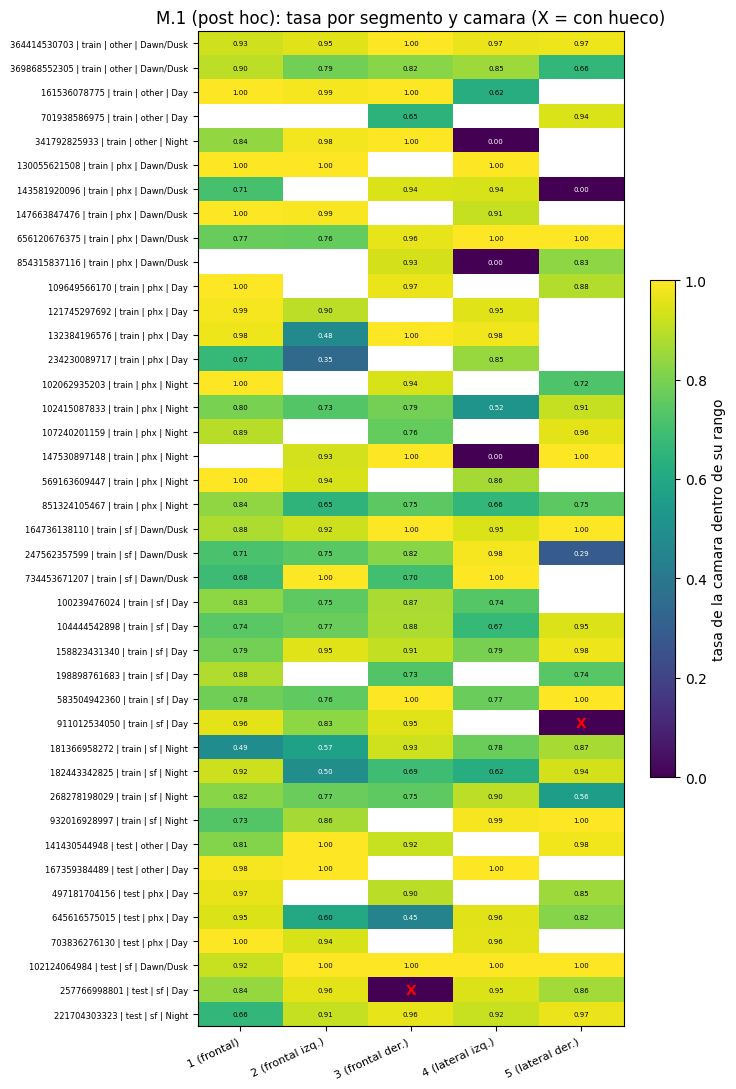

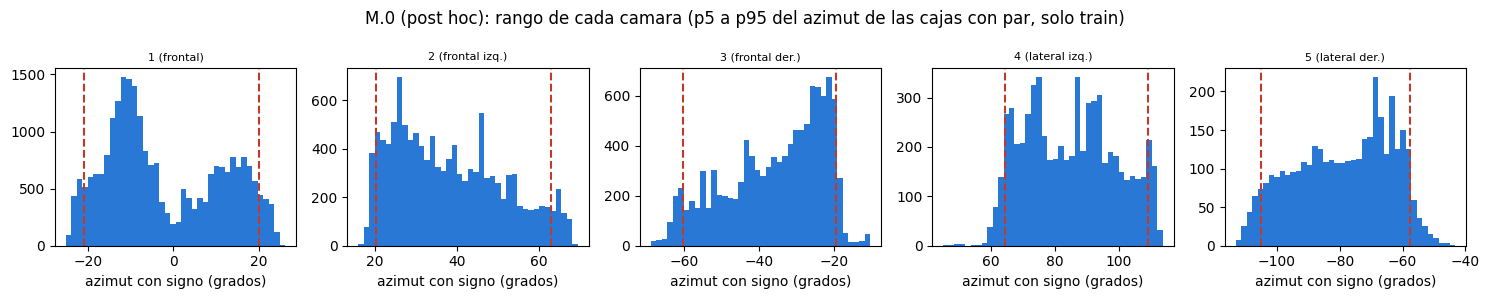

**Lectura (generada, hipótesis).** Con los criterios fijados antes, hay **2 pares (segmento, cámara) con hueco en 2 de 41 segmentos** (1 de train y 1 de test): 911012534050 (train, sf, Day) cámara 5 (lateral der.) con tasa 0,000 frente a una mediana de 0,914 (300 cajas en su rango); 257766998801 (test, sf, Day) cámara 3 (frontal der.) con tasa 0,000 frente a una mediana de 0,917 (1677 cajas en su rango). Los rangos son empíricos (percentil 5 a 95 del azimut de las cajas con par en train), no calibración.

In [26]:
T_M = meta.join(tasa.add_prefix("tasa_")).join(nrango.add_prefix("n_rango_")).join(hueco.add_prefix("hueco_"))
T_M["algun_hueco"] = hueco.any(axis=1)
T_M = T_M.sort_values(["grupo", "ubicacion", "momento"], ascending=[False, True, True])
vista = T_M[["grupo", "ubicacion", "momento", "cajas"]].copy()
for c in CAMS_M:
    vista[CAM_M[c]] = [f"{t:.2f} (n={n})" + (" *" if h else "") for t, n, h in zip(T_M[f"tasa_c{c}"], T_M[f"n_rango_c{c}"], T_M[f"hueco_c{c}"])]
print("Tasa por segmento y camara (n = cajas en el rango; * = con hueco):")
print(vista.to_string())
guardar_csv(T_M, "10_M_tasa_segmento_camara")
filas = [{"segmento": s, "grupo": T_M.loc[s, "grupo"], "ubicacion": T_M.loc[s, "ubicacion"], "momento": T_M.loc[s, "momento"], "camara": CAM_M[c], "tasa": T_M.loc[s, f"tasa_c{c}"], "mediana_camara": med[f"c{c}"], "umbral": 0.25 * med[f"c{c}"], "cajas_en_rango": T_M.loc[s, f"n_rango_c{c}"]}
         for s in T_M.index for c in CAMS_M if T_M.loc[s, f"hueco_c{c}"]]
LISTA_H = pd.DataFrame(filas, columns=["segmento", "grupo", "ubicacion", "momento", "camara", "tasa", "mediana_camara", "umbral", "cajas_en_rango"])
print(f"\nPares (segmento, camara) con hueco: {len(LISTA_H)}")
print(LISTA_H.round(3).to_string(index=False))
guardar_csv(LISTA_H, "10_M_pares_con_hueco", indice=False)
guardar_csv(pd.DataFrame({"camara": [CAM_M[c] for c in CAMS_M], "az_p5": [RANGO[c][0] for c in CAMS_M], "az_p95": [RANGO[c][1] for c in CAMS_M], "mediana_tasa": [med[f"c{c}"] for c in CAMS_M]}), "10_M_rangos_camara", indice=False)

fig, ax = plt.subplots(figsize=(7.5, 11))
mat = T_M[[f"tasa_c{c}" for c in CAMS_M]].values.astype(float)
im = ax.imshow(np.ma.masked_invalid(mat), aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(CAMS_M)), [CAM_M[c] for c in CAMS_M], rotation=25, ha="right", fontsize=8)
ax.set_yticks(range(len(T_M)), [f"{s} | {r.grupo} | {r.ubicacion.replace('location_', '')} | {r.momento}" for s, r in T_M.iterrows()], fontsize=6)
for i in range(mat.shape[0]):
    for j, c in enumerate(CAMS_M):
        if T_M.iloc[i][f"hueco_c{c}"]:
            ax.text(j, i, "X", ha="center", va="center", color="red", fontsize=10, fontweight="bold")
        elif mat[i, j] == mat[i, j]:
            ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", color="white" if mat[i, j] < 0.6 else "black", fontsize=5)
fig.colorbar(im, ax=ax, shrink=0.5, label="tasa de la camara dentro de su rango")
ax.set_title("M.1 (post hoc): tasa por segmento y camara (X = con hueco)")
fig.tight_layout()
guardar_fig(fig, "10_M_mapa_calor")
plt.show()

fig, axes = plt.subplots(1, len(CAMS_M), figsize=(15, 3))
for ax, c in zip(np.atleast_1d(axes), CAMS_M):
    az = AM.loc[(AM["grupo"] == "train") & (AM[f"c{c}"] == 1), "az_signed"]
    ax.hist(az, bins=40, color=AZUL)
    for v in RANGO[c]:
        ax.axvline(v, color=ROJO, ls="--")
    ax.set_title(CAM_M[c], fontsize=8); ax.set_xlabel("azimut con signo (grados)")
fig.suptitle("M.0 (post hoc): rango de cada camara (p5 a p95 del azimut de las cajas con par, solo train)")
fig.tight_layout()
guardar_fig(fig, "10_M_rangos")
plt.show()

n_seg_hueco = int(T_M["algun_hueco"].sum())
seg_h = T_M.index[T_M["algun_hueco"]].tolist()
display(Markdown(
    f"**Lectura (generada, hipótesis).** Con los criterios fijados antes, hay **{len(LISTA_H)} {'par' if len(LISTA_H) == 1 else 'pares'} (segmento, cámara) con hueco en {n_seg_hueco} de {len(T_M)} {'segmento' if len(T_M) == 1 else 'segmentos'}** ({int((T_M['algun_hueco'] & (T_M['grupo'] == 'train')).sum())} de train y {int((T_M['algun_hueco'] & (T_M['grupo'] == 'test')).sum())} de test)" +
    (": " + "; ".join(f"{r.segmento} ({r.grupo}, {r.ubicacion.replace('location_', '')}, {r.momento}) cámara {r.camara} con tasa {n3(r.tasa)} frente a una mediana de {n3(r.mediana_camara)} ({int(r.cajas_en_rango)} cajas en su rango)" for r in LISTA_H.itertuples()) + "." if len(LISTA_H) else ".") +
    " Los rangos son empíricos (percentil 5 a 95 del azimut de las cajas con par en train), no calibración."))

## M.2 ¿Tiene huecos el segmento de train 911012534050?

In [27]:
S911 = "911012534050"
if S911 in T_M.index:
    r = T_M.loc[S911]
    t911 = pd.DataFrame({"camara": [CAM_M[c] for c in CAMS_M], "tasa": [r[f"tasa_c{c}"] for c in CAMS_M], "mediana": [med[f"c{c}"] for c in CAMS_M], "umbral de hueco": [0.25 * med[f"c{c}"] for c in CAMS_M], "cajas en rango": [r[f"n_rango_c{c}"] for c in CAMS_M], "hueco": [bool(r[f"hueco_c{c}"]) for c in CAMS_M]})
    print(t911.round(3).to_string(index=False))
    guardar_csv(t911, "10_M_segmento_911012534050", indice=False)
    h911 = t911[t911["hueco"]]
    RM_911 = {"existe": True, "huecos": h911["camara"].tolist(), "tasas": {x.camara: float(x.tasa) for x in t911.itertuples()}}
    display(Markdown(
        f"**Lectura (generada, hipótesis).** El segmento {S911} ({r['ubicacion']}, {r['momento']}) " +
        (f"**tiene hueco en: {', '.join(h911['camara'])}** (tasa {', '.join(n3(x) for x in h911['tasa'])}; umbral {', '.join(n3(x) for x in h911['umbral de hueco'])})." if len(h911) else
         f"**no tiene ninguna cámara con hueco** con los criterios fijados; su tasa más baja es {n3(t911['tasa'].min())} ({t911.loc[t911['tasa'].idxmin(), 'camara']}) frente a una mediana de {n3(t911.loc[t911['tasa'].idxmin(), 'mediana'])}.")))
else:
    RM_911 = {"existe": False}
    print("(ensayo: el segmento 911012534050 no esta en esta corrida)")

          camara  tasa  mediana  umbral de hueco  cajas en rango  hueco
     1 (frontal) 0.959    0.880            0.220             779  False
2 (frontal izq.) 0.831    0.902            0.225             255  False
3 (frontal der.) 0.951    0.917            0.229             453  False
4 (lateral izq.)   NaN    0.913            0.228               0  False
5 (lateral der.) 0.000    0.914            0.228             300   True


**Lectura (generada, hipótesis).** El segmento 911012534050 (location_sf, Day) **tiene hueco en: 5 (lateral der.)** (tasa 0,000; umbral 0,228).

## M.3 ¿Qué parte de los positivos cae en celdas con hueco?

In [28]:
gap_cams = {s: [c for c in CAMS_M if T_M.loc[s, f"hueco_c{c}"]] for s in T_M.index}
PM = AM[AM["en_zona_principal"]].copy()
def en_celda_hueco(df):
    out = np.zeros(len(df), dtype=bool)
    for s, idx in df.groupby("seg").indices.items():
        for c in gap_cams.get(s, []):
            az = df["az_signed"].values[idx]
            out[idx] |= (az >= RANGO[c][0]) & (az <= RANGO[c][1])
    return out
PM["en_hueco"] = en_celda_hueco(PM)
filas = []
for g in ("train", "test"):
    d = PM[PM["grupo"] == g]
    pos = d[d["sin_camara"] == 1]
    muchos = pos[pos["num_lidar_points"] >= 100]
    filas.append({"grupo": g, "segmentos": d["seg"].nunique(), "segmentos con algun hueco": int(sum(len(gap_cams[s]) > 0 for s in d["seg"].unique())), "cajas": len(d), "% de las cajas en celdas con hueco": d["en_hueco"].mean(),
                  "positivos": len(pos), "positivos en celdas con hueco": int(pos["en_hueco"].sum()), "% de los positivos": pos["en_hueco"].mean() if len(pos) else np.nan,
                  "positivos con >= 100 puntos": len(muchos), "de ellos en celdas con hueco": int(muchos["en_hueco"].sum()), "% de los positivos con >= 100 puntos": muchos["en_hueco"].mean() if len(muchos) else np.nan,
                  "tasa de sin_camara dentro de celdas con hueco": d.loc[d["en_hueco"], "sin_camara"].mean() if d["en_hueco"].any() else np.nan, "tasa de sin_camara fuera de celdas con hueco": d.loc[~d["en_hueco"], "sin_camara"].mean()})
T_M3 = pd.DataFrame(filas).set_index("grupo")
print(T_M3.T.round(3).to_string())
guardar_csv(T_M3, "10_M_positivos_en_huecos")
por_seg = PM[PM["sin_camara"] == 1].groupby("seg").agg(positivos=("sin_camara", "size"), en_hueco=("en_hueco", "sum"))
por_seg = por_seg[por_seg["en_hueco"] > 0].sort_values("en_hueco", ascending=False)
por_seg["grupo"] = meta.loc[por_seg.index, "grupo"]
print("\nSegmentos con positivos en celdas con hueco:")
print(por_seg.to_string())
guardar_csv(por_seg, "10_M_positivos_en_huecos_por_segmento")
RM_3 = T_M3.to_dict("index")
a_, b_ = T_M3.loc["train"], T_M3.loc["test"]
display(Markdown(
    f"**Lectura (generada, hipótesis).** En la población principal, **en train el {pct(a_['% de los positivos'])} de los positivos** ({miles(a_['positivos en celdas con hueco'])} de {miles(a_['positivos'])}) cae en celdas (segmento, cámara) con hueco y dentro del rango de esa cámara, y **en test el {pct(b_['% de los positivos'])}** ({miles(b_['positivos en celdas con hueco'])} de {miles(b_['positivos'])}). "
    f"Esas celdas contienen el {pct(a_['% de las cajas en celdas con hueco'])} de las cajas de train y el {pct(b_['% de las cajas en celdas con hueco'])} de las de test. La tasa de `sin_camara` dentro de las celdas con hueco es {pct(a_['tasa de sin_camara dentro de celdas con hueco'])} en train y {pct(b_['tasa de sin_camara dentro de celdas con hueco'])} en test, frente a {pct(a_['tasa de sin_camara fuera de celdas con hueco'])} y {pct(b_['tasa de sin_camara fuera de celdas con hueco'])} fuera de ellas. "
    f"Entre los positivos con al menos 100 puntos, el {pct(a_['% de los positivos con >= 100 puntos'])} en train y el {pct(b_['% de los positivos con >= 100 puntos'])} en test están en esas celdas."))

grupo                                              train       test
segmentos                                         33.000      8.000
segmentos con algun hueco                          1.000      1.000
cajas                                          64509.000  16062.000
% de las cajas en celdas con hueco                 0.004      0.104
positivos                                      13368.000   3734.000
positivos en celdas con hueco                    227.000   1338.000
% de los positivos                                 0.017      0.358
positivos con >= 100 puntos                      583.000    937.000
de ellos en celdas con hueco                     192.000    884.000
% de los positivos con >= 100 puntos               0.329      0.943
tasa de sin_camara dentro de celdas con hueco      0.847      0.798
tasa de sin_camara fuera de celdas con hueco       0.205      0.167

Segmentos con positivos en celdas con hueco:
              positivos  en_hueco  grupo
seg                          

**Lectura (generada, hipótesis).** En la población principal, **en train el 1,7 % de los positivos** (227 de 13.368) cae en celdas (segmento, cámara) con hueco y dentro del rango de esa cámara, y **en test el 35,8 %** (1.338 de 3.734). Esas celdas contienen el 0,4 % de las cajas de train y el 10,4 % de las de test. La tasa de `sin_camara` dentro de las celdas con hueco es 84,7 % en train y 79,8 % en test, frente a 20,5 % y 16,7 % fuera de ellas. Entre los positivos con al menos 100 puntos, el 32,9 % en train y el 94,3 % en test están en esas celdas.

## M.4 Segmentos con hueco frente a la regla por puntos

Descriptivo, con n pequeño: solo una tabla 2x2 (hueco sí/no contra AUC de la regla top menor que 0,55, en segmentos con al menos 50 positivos en la población principal) y el test exacto de Fisher, **rotulado como exploratorio** (no se interpreta como prueba).

              grupo       ubicacion    momento  algun_hueco camaras_con_hueco  filas  positivos  AUC regla top  % positivos con >= 100 puntos
segmento                                                                                                                                     
911012534050  train     location_sf        Day         True  5 (lateral der.)   1715        316          0.408                          0.617
257766998801   test     location_sf        Day         True  3 (frontal der.)   6474       2046          0.443                          0.457
102062935203  train    location_phx      Night        False                      155          2          0.449                          0.000
932016928997  train     location_sf      Night        False                      513         97          0.661                          0.000
364414530703  train  location_other  Dawn/Dusk        False                      975         49          0.691                          0.000
247562

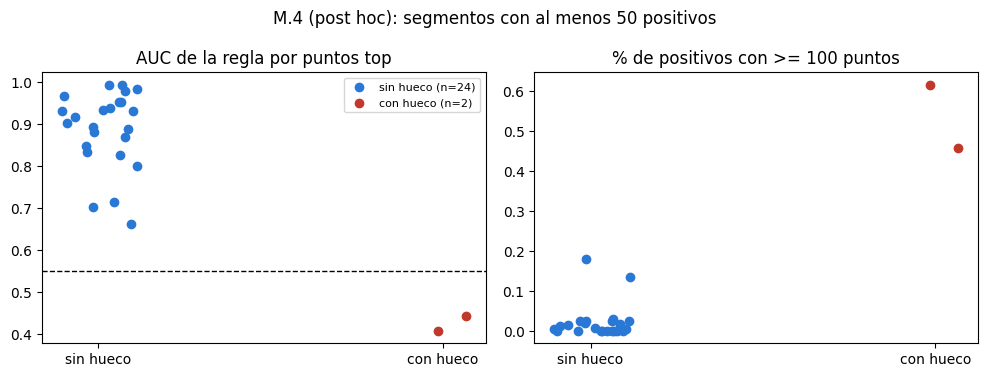

**Lectura (generada, exploratoria).** Entre 26 segmentos con al menos 50 positivos: con hueco y AUC < 0,55: 2; con hueco y AUC ≥ 0,55: 0; sin hueco y AUC < 0,55: 0; sin hueco y AUC ≥ 0,55: 24. Test exacto de Fisher **(exploratorio, n pequeño, no es una prueba de hipótesis confirmatoria)**: p = 0,0031. AUC de la regla top: mediana 0,909 sin hueco y 0,425 con hueco; porcentaje de positivos con ≥ 100 puntos (mediana): 1 % sin hueco y 54 % con hueco.

In [29]:
from scipy.stats import fisher_exact
filas = []
for s, d in PM.groupby("seg"):
    yy_ = d["sin_camara"].values
    pos = d[d["sin_camara"] == 1]
    filas.append({"segmento": s, "grupo": d["grupo"].iloc[0], "ubicacion": d["location"].iloc[0], "momento": d["time_of_day"].iloc[0], "algun_hueco": len(gap_cams[s]) > 0, "camaras_con_hueco": ", ".join(CAM_M[c] for c in gap_cams[s]),
                  "filas": len(d), "positivos": int(yy_.sum()), "AUC regla top": roc_auc_score(yy_, -d["num_top_lidar_points"].values) if len(np.unique(yy_)) > 1 else np.nan,
                  "% positivos con >= 100 puntos": (pos["num_lidar_points"] >= 100).mean() if len(pos) else np.nan})
T_M4 = pd.DataFrame(filas).set_index("segmento")
print(T_M4.sort_values("AUC regla top").round(3).to_string())
guardar_csv(T_M4, "10_M_segmentos_hueco_vs_auc")
base = T_M4[(T_M4["positivos"] >= 50) & T_M4["AUC regla top"].notna()].copy()
base["AUC < 0,55"] = base["AUC regla top"] < 0.55
tab22 = pd.crosstab(base["algun_hueco"].map({True: "con hueco", False: "sin hueco"}), base["AUC < 0,55"].map({True: "AUC < 0,55", False: "AUC >= 0,55"})).reindex(index=["con hueco", "sin hueco"], columns=["AUC < 0,55", "AUC >= 0,55"], fill_value=0)
print("\nTabla 2x2 (segmentos con >= 50 positivos):")
print(tab22.to_string())
guardar_csv(tab22, "10_M_tabla_2x2")
orr, pF = fisher_exact(tab22.values)
print(f"Test exacto de Fisher (EXPLORATORIO, dos colas): p = {pF:.4f}; razon de odds = {orr}")
resumen_h = base.groupby("algun_hueco").agg(segmentos=("AUC regla top", "size"), mediana_AUC=("AUC regla top", "median"), minimo_AUC=("AUC regla top", "min"), mediana_pct_pos_100=("% positivos con >= 100 puntos", "median"))
print("\nPor grupo (descriptivo):")
print(resumen_h.round(3).to_string())
guardar_csv(resumen_h, "10_M_resumen_hueco_vs_auc")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, tit in zip(axes, ["AUC regla top", "% positivos con >= 100 puntos"], ["AUC de la regla por puntos top", "% de positivos con >= 100 puntos"]):
    for k, (v, c, nm) in enumerate(((False, AZUL, "sin hueco"), (True, ROJO, "con hueco"))):
        d = base[base["algun_hueco"] == v]
        ax.scatter(np.full(len(d), k) + np.random.default_rng(SEMILLA).uniform(-0.12, 0.12, len(d)), d[col], color=c, label=f"{nm} (n={len(d)})")
    ax.set_xticks([0, 1], ["sin hueco", "con hueco"]); ax.set_title(tit)
axes[0].axhline(0.55, color="k", ls="--", lw=1)
axes[0].legend(fontsize=8)
fig.suptitle("M.4 (post hoc): segmentos con al menos 50 positivos")
fig.tight_layout()
guardar_fig(fig, "10_M_auc_hueco")
plt.show()
RM_4 = {"tab22": tab22.to_dict(), "fisher_p": float(pF), "n_base": int(len(base)), "resumen": resumen_h.to_dict("index")}
c_h_b = int(tab22.loc["con hueco", "AUC < 0,55"]); c_h_n = int(tab22.loc["con hueco", "AUC >= 0,55"]); s_h_b = int(tab22.loc["sin hueco", "AUC < 0,55"]); s_h_n = int(tab22.loc["sin hueco", "AUC >= 0,55"])
display(Markdown(
    f"**Lectura (generada, exploratoria).** Entre {len(base)} segmentos con al menos 50 positivos: con hueco y AUC < 0,55: {c_h_b}; con hueco y AUC ≥ 0,55: {c_h_n}; sin hueco y AUC < 0,55: {s_h_b}; sin hueco y AUC ≥ 0,55: {s_h_n}. "
    f"Test exacto de Fisher **(exploratorio, n pequeño, no es una prueba de hipótesis confirmatoria)**: p = {str(round(pF, 4)).replace('.', ',')}. "
    f"AUC de la regla top: mediana " + " y ".join(f"{n3(v)} {'con' if k else 'sin'} hueco" for k, v in resumen_h['mediana_AUC'].items()) + "; porcentaje de positivos con ≥ 100 puntos (mediana): " + " y ".join(f"{pct(v, 0)} {'con' if k else 'sin'} hueco" for k, v in resumen_h['mediana_pct_pos_100'].items()) + "."))

## M.5 Conclusión del apéndice (hipótesis)

In [30]:
n_tr_h = int((T_M["algun_hueco"] & (T_M["grupo"] == "train")).sum())
n_te_h = int((T_M["algun_hueco"] & (T_M["grupo"] == "test")).sum())
pos_all = int(T_M3["positivos"].sum())
pos_h = int(T_M3["positivos en celdas con hueco"].sum())
foco_en = "257766998801" in T_M.index and bool(T_M.loc["257766998801", "algun_hueco"]) if not ENSAYO else None
CONCL_M = (
    f"**Hipótesis (post hoc, no pre-declarada).** Con los criterios fijados antes de calcular, **{n_seg_hueco} de {len(T_M)} segmentos ({pct(n_seg_hueco / len(T_M), 0)}) {'tiene' if n_seg_hueco == 1 else 'tienen'} al menos una cámara con hueco** ({n_tr_h} de {int((T_M['grupo'] == 'train').sum())} de train y {n_te_h} de {int((T_M['grupo'] == 'test').sum())} de test), en {len(LISTA_H)} {'par' if len(LISTA_H) == 1 else 'pares'} (segmento, cámara). "
    f"Esas celdas reúnen el {pct(T_M3.loc['train', '% de los positivos'])} de los positivos de train y el {pct(T_M3.loc['test', '% de los positivos'])} de los de test de la población principal; es decir, {pct(pos_h / pos_all)} del total de cajas sin par ({miles(pos_h)} de {miles(pos_all)}) se atribuye a unos pocos huecos de cámara y no a la falta de puntos. "
    + (f"El segmento de train 911012534050 {'tiene hueco en ' + ', '.join(RM_911['huecos']) if RM_911.get('huecos') else 'no tiene hueco con estos criterios'}. " if RM_911.get("existe") else "")
    + f"En la tabla 2x2 exploratoria (p de Fisher = {str(round(pF, 3)).replace('.', ',')}, n = {len(base)}), {c_h_b} de {c_h_b + c_h_n} segmentos con hueco tienen AUC < 0,55, frente a {s_h_b} de {s_h_b + s_h_n} sin hueco. "
    "**Implicación (hipótesis):** una auditoría por segmento y cámara (tasa de pares de cada cámara dentro de su rango de azimut) detecta lo que la regla por puntos no detecta: los huecos afectan a objetos bien observados, que la regla ordena como si tuvieran par. "
    "**Aclaración:** un 'hueco' puede ser de etiquetado o de los datos de esa cámara (por ejemplo, una cámara sin imágenes o sin etiquetas 2D en el segmento); con estos archivos no se puede distinguir. Los rangos de azimut son empíricos (de train), no calibración, y los criterios son los fijados antes de calcular. No cambia la recomendación formal ni el resultado pre-declarado."
)
RES["M"] = {"n_seg_hueco": n_seg_hueco, "n_seg": int(len(T_M)), "n_train_hueco": n_tr_h, "n_test_hueco": n_te_h, "n_pares": int(len(LISTA_H)), "pares": LISTA_H.to_dict("records"), "m911": RM_911, "pos": RM_3, "fisher_p": float(pF), "tab22": tab22.to_dict(), "n_base": int(len(base)), "conclusion": CONCL_M,
            "rango": {CAM_M[c]: RANGO[c] for c in CAMS_M}, "mediana": {CAM_M[c]: float(med[f"c{c}"]) for c in CAMS_M}}
display(Markdown(CONCL_M))

**Hipótesis (post hoc, no pre-declarada).** Con los criterios fijados antes de calcular, **2 de 41 segmentos (5 %) tienen al menos una cámara con hueco** (1 de 33 de train y 1 de 8 de test), en 2 pares (segmento, cámara). Esas celdas reúnen el 1,7 % de los positivos de train y el 35,8 % de los de test de la población principal; es decir, 9,2 % del total de cajas sin par (1.565 de 17.102) se atribuye a unos pocos huecos de cámara y no a la falta de puntos. El segmento de train 911012534050 tiene hueco en 5 (lateral der.). En la tabla 2x2 exploratoria (p de Fisher = 0,003, n = 26), 2 de 2 segmentos con hueco tienen AUC < 0,55, frente a 0 de 24 sin hueco. **Implicación (hipótesis):** una auditoría por segmento y cámara (tasa de pares de cada cámara dentro de su rango de azimut) detecta lo que la regla por puntos no detecta: los huecos afectan a objetos bien observados, que la regla ordena como si tuvieran par. **Aclaración:** un 'hueco' puede ser de etiquetado o de los datos de esa cámara (por ejemplo, una cámara sin imágenes o sin etiquetas 2D en el segmento); con estos archivos no se puede distinguir. Los rangos de azimut son empíricos (de train), no calibración, y los criterios son los fijados antes de calcular. No cambia la recomendación formal ni el resultado pre-declarado.

## K.3 Resumen ejecutivo, archivos de salida y verificación de identidad

Estas celdas van al final porque resumen también el apéndice L y guardan los archivos; se numeran K.3 porque cierran la sección K.

In [31]:
# ---- resumen ejecutivo generado (se copia al encabezado despues de la ejecucion)
rb, rd, re_, rf_, rh = RES["B"], RES["D"], RES["E"], RES["F"], RES["H"]
oaM, obM = rd["OP"][(MOD, "A")], rd["OP"][(MOD, "B")]
resumen = f'''### Resumen ejecutivo (generado por código)

- **Resultado principal (pre-declarado, población principal, {miles(len(pop_p))} filas, {POB_P["n_seg"]} segmentos de test):** {MOD} tiene AUC {n3(rb["punto"][MOD]["AUC"])} (IC {n3(rb["ic"][MOD]["AUC"][0])} a {n3(rb["ic"][MOD]["AUC"][1])}) y Fracción para 80 % {pct(rb["punto"][MOD]["Fraccion para 80%"])}; {BASE}, {n3(rb["punto"][BASE]["AUC"])} y {pct(rb["punto"][BASE]["Fraccion para 80%"])}. Diferencia de AUC {n3(rb["dA"][0], True)} (IC {n3(rb["dA"][1], True)} a {n3(rb["dA"][2], True)}); de Fracción para 80 % {pts(rb["dF"][0] * 100)} puntos (IC {pts(rb["dF"][1] * 100)} a {pts(rb["dF"][2] * 100)}). **"Vale la pena": {"se cumple" if rb["vlp"] else "no se cumple"}**{"; el modelo no se distingue del baseline" if rb["no_dist"] else ""}.
- **Puntos de operación (umbrales congelados):** A de {MOD}: recall {n3(oaM["recall"][0])} (IC {n3(oaM["recall"][1])} a {n3(oaM["recall"][2])}), precisión {n3(oaM["precision"][0])}, {pct(oaM["pct_revisar"][0])} a revisar; **{"se sostiene" if rd["sostenido"][MOD] else "no se sostiene"}** (recall ≥ {str(rd["tol"]).replace('.', ',')}). B: recall {n3(obM["recall"][0])} con {pct(obM["pct_revisar"][0])} revisado.
- **Influencia ({rf_["n"]} cálculos):** diferencia de AUC de {n3(rf_["rng_auc"][0], True)} a {n3(rf_["rng_auc"][1], True)}; de Fracción para 80 % de {pts(rf_["rng_f80"][0])} a {pts(rf_["rng_f80"][1])} puntos. {"Cambia el veredicto al quitar: " + ", ".join(rf_["cambian"]) + "." if rf_["cambian"] else "Ningún segmento por sí solo cambia el veredicto."}
- **Sensibilidad a 120°:** robusto (lectura literal del plan): {", ".join(n for n, v in rh["robusto_literal"].items() if v) or "ningún modelo"}; con baselines de train: {", ".join(n for n, v in rh["robusto_train"].items() if v) or "ningún modelo"}.
- **Calibración en test ({MOD}):** ECE {n3(re_["ece_raw"])} crudo y {n3(re_["ece_cal"])} con {re_["version"]} congelado.
- **Equidad descriptiva (recall al punto A de {REC}, sección G):** {"; ".join(brechas)}. {"Con un solo segmento: " + ", ".join(RES["G"]["unico"]) + "." if RES["G"]["unico"] else ""}
- **Test frente a train:** orden por AUC {"igual" if RES["I"]["or_auc_test"] == RES["I"]["or_auc_train"] else "distinto (hallazgo, sin reajustar)"}.
- **Recomendación (interpretación):** {RES["J"]["rec"]}. {RES["J"]["matices"]}

### Diagnóstico post hoc, no pre-declarado (sección L; no cambia la recomendación formal)

- El segmento `{RL["foco"]}` tiene {miles(RL["grupos"]["foco"]["filas"])} filas y {miles(RL["grupos"]["foco"]["sin_camara"])} positivos ({pct(RL["grupos"]["foco"]["sin_camara"] / (RL["grupos"]["foco"]["sin_camara"] + RL["grupos"]["otros 7 de test"]["sin_camara"]), 1)} de los positivos de test); su tasa de `sin_camara` es {pct(RL["tasas"]["foco"])} (otros 7: {pct(RL["tasas"]["otros"])}; train: {pct(RL["tasas"]["train"])}).
- AUC dentro del segmento: regla por puntos top {n3(RL["auc_foco"]["top"])} y regresión logística {n3(RL["auc_foco"]["lr"])}.
- Cajas sin par con ≥ 100 puntos: {pct(RL["muchos"]["foco"]["% de las sin par"])} en el segmento, {pct(RL["muchos"]["otros 7 de test"]["% de las sin par"])} en los otros 7 y {pct(RL["muchos"]["train"]["% de las sin par"])} en train.
- Segmentos de train con AUC de la regla top < 0,55: {RL["train_bajos"]["n"]} de {len(T_TR)} ({RL["train_bajos"]["n50"]} con al menos 50 positivos).
- Sin el segmento (7 segmentos): AUC {n3(RL["sin_foco"]["auc"][MOD])} ({MOD}) y {n3(RL["sin_foco"]["auc"][BASE])} ({BASE}); 'vale la pena' {"se cumple" if RL["sin_foco"]["vlp"] else "no se cumple"}; punto A de {MOD}: recall {n3(RL["sin_foco"]["recall_A"][MOD][0])}; {sum(RL["sin_foco"]["sostenido"].values())} de {len(METODOS)} métodos sostienen el punto A (oficial: {sum(RES["D"]["sostenido"].values())}).
- Recall del punto A de {BASE} de día (L.7): {n3(T_L7[(T_L7["metodo"] == BASE) & (T_L7["grupo"] == "Day")]["recall A (oficial)"].iloc[0])} oficial y {n3(T_L7[(T_L7["metodo"] == BASE) & (T_L7["grupo"] == "Day")]["recall A (sin el segmento)"].iloc[0])} sin el segmento; en San Francisco {n3(T_L7[(T_L7["metodo"] == BASE) & (T_L7["grupo"] == "location_sf")]["recall A (oficial)"].iloc[0])} y {n3(T_L7[(T_L7["metodo"] == BASE) & (T_L7["grupo"] == "location_sf")]["recall A (sin el segmento)"].iloc[0])}.
- {RL["conclusion"]}

### Diagnóstico post hoc M, no pre-declarado (auditoría por cámara en 41 segmentos; no cambia la recomendación formal)

- {RES["M"]["n_seg_hueco"]} de {RES["M"]["n_seg"]} segmentos tienen alguna cámara con hueco ({RES["M"]["n_train_hueco"]} de train, {RES["M"]["n_test_hueco"]} de test), en {RES["M"]["n_pares"]} pares (segmento, cámara).
- Positivos de la población principal en celdas con hueco: {pct(RES["M"]["pos"]["train"]["% de los positivos"])} en train y {pct(RES["M"]["pos"]["test"]["% de los positivos"])} en test.
- Tabla 2x2 exploratoria (hueco frente a AUC de la regla top < 0,55, segmentos con al menos 50 positivos, n = {RES["M"]["n_base"]}): p de Fisher = {str(round(RES["M"]["fisher_p"], 3)).replace(".", ",")} (exploratorio).
- {RES["M"]["conclusion"]}
'''
display(Markdown(resumen))

### Resumen ejecutivo (generado por código)

- **Resultado principal (pre-declarado, población principal, 16.062 filas, 8 segmentos de test):** Regresion logistica tiene AUC 0,698 (IC 0,503 a 0,961) y Fracción para 80 % 77,4 %; Regla: menos puntos top, 0,684 y 79,0 %. Diferencia de AUC +0,014 (IC -0,014 a +0,029); de Fracción para 80 % -1,7 puntos (IC -4,2 a +4,1). **"Vale la pena": no se cumple**; el modelo no se distingue del baseline.
- **Puntos de operación (umbrales congelados):** A de Regresion logistica: recall 0,621 (IC 0,413 a 0,958), precisión 0,406, 35,6 % a revisar; **no se sostiene** (recall ≥ 0,75). B: recall 0,447 con 15,1 % revisado.
- **Influencia (12 cálculos):** diferencia de AUC de -0,004 a +0,020; de Fracción para 80 % de -2,4 a +1,3 puntos. Ningún segmento por sí solo cambia el veredicto.
- **Sensibilidad a 120°:** robusto (lectura literal del plan): ningún modelo; con baselines de train: ningún modelo.
- **Calibración en test (Regresion logistica):** ECE 0,079 crudo y 0,080 con Platt congelado.
- **Equidad descriptiva (recall al punto A de Regla: menos puntos top, sección G):** momento del día: Day 0,495 (6 seg., 10.558 filas) frente a Dawn/Dusk 1,000 (1 seg., 851 filas); ubicación: location_sf 0,515 (3 seg., 11.978 filas) frente a location_other 0,946 (2 seg., 1.850 filas); clase: PEDESTRIAN 0,590 (8 seg., 15.730 filas) frente a CYCLIST 0,667 (2 seg., 332 filas). Con un solo segmento: Dawn/Dusk, Night.
- **Test frente a train:** orden por AUC distinto (hallazgo, sin reajustar).
- **Recomendación (interpretación):** Regla: menos puntos top. **Matices (no cambian la recomendación formal).** El punto A de Regla: menos puntos top no se sostiene en test: recall 0,590 (IC 0,383 a 0,924) frente a la meta de 0,80 y la tolerancia de 0,75. El recall depende fuertemente de un segmento: en el segmento con más positivos (257766998801, 55 % de los positivos) el recall es 0,351 y sin él pasa de 0,590 a 0,879; entre los 4 segmentos con al menos 50 positivos, 3 alcanzan la tolerancia (recall de 0,351 a 0,945). Por eso se sugiere usarlo para priorizar la revisión humana, junto con un monitoreo del recall por segmento, y no como reemplazo de la revisión. (Detalle y diagnóstico post hoc en la sección L.)

### Diagnóstico post hoc, no pre-declarado (sección L; no cambia la recomendación formal)

- El segmento `257766998801` tiene 6.474 filas y 2.046 positivos (54,8 % de los positivos de test); su tasa de `sin_camara` es 31,6 % (otros 7: 17,6 %; train: 20,7 %).
- AUC dentro del segmento: regla por puntos top 0,443 y regresión logística 0,459.
- Cajas sin par con ≥ 100 puntos: 45,7 % en el segmento, 0,1 % en los otros 7 y 4,4 % en train.
- Segmentos de train con AUC de la regla top < 0,55: 2 de 33 (1 con al menos 50 positivos).
- Sin el segmento (7 segmentos): AUC 0,927 (Regresion logistica) y 0,931 (Regla: menos puntos top); 'vale la pena' no se cumple; punto A de Regresion logistica: recall 0,913; 7 de 7 métodos sostienen el punto A (oficial: 0).
- Recall del punto A de Regla: menos puntos top de día (L.7): 0,495 oficial y 0,903 sin el segmento; en San Francisco 0,515 y 0,861.
- **Hipótesis (post hoc, no pre-declarada).** Condición (i): las cajas sin par con al menos 100 puntos son 936 de 2.046 (45,7 %) en el foco frente a 1 de 1.688 (0,1 %) en los otros 7: se cumple. Condición (ii): AUC de la regla por puntos top dentro del segmento 0,443: se cumple. En las cámaras (regla de L.2), la cámara 3 (frontal der.) no tiene ningún par en el segmento (0 de 6.474 cajas del segmento; 2.090 cajas caen dentro de su rango de azimut). La causa puede ser etiquetado 2D faltante o ausencia de datos de esa cámara; con estos archivos no se distinguen. Ambas condiciones se cumplen: una parte importante de las cajas sin par del segmento son objetos bien observados, lo que **sugiere que el problema de este segmento no es la falta de observabilidad LiDAR sino la ausencia de pares en la cámara 3 (frontal der.); si la causa es etiquetado 2D faltante o ausencia de datos de esa cámara no se distingue con estos archivos**. Implicación para el uso de la regla: la regla por puntos sirve mientras la relación entre pocos puntos y ausencia de par 2D se mantenga; **no detecta huecos sistemáticos de etiquetado**, porque esos objetos están bien observados y la regla los ordena como si tuvieran par. Por eso conviene monitorear el recall por segmento. Sin el segmento, el resultado principal sigue sin cumplir 'vale la pena' y 7 de 7 métodos sostienen el punto A (oficial: 0); eso describe cuánto depende el resultado de un solo segmento y no reemplaza el resultado pre-declarado.

### Diagnóstico post hoc M, no pre-declarado (auditoría por cámara en 41 segmentos; no cambia la recomendación formal)

- 2 de 41 segmentos tienen alguna cámara con hueco (1 de train, 1 de test), en 2 pares (segmento, cámara).
- Positivos de la población principal en celdas con hueco: 1,7 % en train y 35,8 % en test.
- Tabla 2x2 exploratoria (hueco frente a AUC de la regla top < 0,55, segmentos con al menos 50 positivos, n = 26): p de Fisher = 0,003 (exploratorio).
- **Hipótesis (post hoc, no pre-declarada).** Con los criterios fijados antes de calcular, **2 de 41 segmentos (5 %) tienen al menos una cámara con hueco** (1 de 33 de train y 1 de 8 de test), en 2 pares (segmento, cámara). Esas celdas reúnen el 1,7 % de los positivos de train y el 35,8 % de los de test de la población principal; es decir, 9,2 % del total de cajas sin par (1.565 de 17.102) se atribuye a unos pocos huecos de cámara y no a la falta de puntos. El segmento de train 911012534050 tiene hueco en 5 (lateral der.). En la tabla 2x2 exploratoria (p de Fisher = 0,003, n = 26), 2 de 2 segmentos con hueco tienen AUC < 0,55, frente a 0 de 24 sin hueco. **Implicación (hipótesis):** una auditoría por segmento y cámara (tasa de pares de cada cámara dentro de su rango de azimut) detecta lo que la regla por puntos no detecta: los huecos afectan a objetos bien observados, que la regla ordena como si tuvieran par. **Aclaración:** un 'hueco' puede ser de etiquetado o de los datos de esa cámara (por ejemplo, una cámara sin imágenes o sin etiquetas 2D en el segmento); con estos archivos no se puede distinguir. Los rangos de azimut son empíricos (de train), no calibración, y los criterios son los fijados antes de calcular. No cambia la recomendación formal ni el resultado pre-declarado.


In [32]:
# ---- salidas: predicciones, cifras, resumen y documento
if not ENSAYO:
    ids = ["segment_id", "key.frame_timestamp_micros", "key.laser_object_id"]
    pred = pop120[ids + ["object_type", "location", "time_of_day", "sin_camara", "en_principal"]].copy()
    pred = pred.rename(columns={"en_principal": "en_poblacion_principal"})
    for n in METODOS:
        pred[f"score_{n}"] = SC_120_P[n]
        pred[f"score120_{n}"] = SC_120[n]
    pcal = np.full(len(pop120), np.nan)
    pcal[pop120["en_principal"].values] = p_cal
    pred["prob_calibrada_Regresion_logistica"] = pcal
    pred.to_parquet(RUTA_OUT / "pred_test_B.parquet", index=False)

    def limpio(o):
        if isinstance(o, dict):
            return {(" | ".join(map(str, k)) if isinstance(k, tuple) else str(k)): limpio(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [limpio(v) for v in o]
        if isinstance(o, (np.floating, np.integer, np.bool_)):
            return o.item()
        return o

    (RUTA_REP / "10_resumen_cifras.json").write_text(json.dumps(limpio({k: v for k, v in RES.items()}), ensure_ascii=False, indent=1, default=str), encoding="utf-8")
    (RUTA_REP / "resumen_ejecutivo_10.md").write_text(resumen, encoding="utf-8")
    doc = ["# Evaluación final en el test (`sin_camara`)", "", "Generado por `notebooks/10_evaluacion_final_sin_camara.ipynb` aplicando el plan congelado v2 (`docs/plan_evaluacion_test.md`). Sin cambios al plan, modelos, umbrales, criterios ni métricas.", "", resumen, "## Resultado principal", "", md_tabla(t_main, indice=False), "", rb["texto"], "",
           "## Todos los métodos (población principal)", "", md_tabla(t_sec, indice=False), "", "## Puntos de operación", "", md_tabla(t_op, indice=False), "", "## Influencia", "", md_tabla(t_inf.round(3), indice=False), "",
           "## Equidad descriptiva", "", md_tabla(t_eq.round(3), indice=False), "", "## Sensibilidad a 120°", "", md_tabla(t_120, indice=False), "", md_tabla(t_120c, indice=False), "", "## Test frente a train", "", md_tabla(t_tt.round(3)), "",
           "## Conclusión técnica", "", TECNICA, "", "## Recomendaciones (interpretación)", "", "\n\n".join(f"{i}. {t}" for i, t in enumerate(RECS, 1)), "", MATICES, "",
           "## Limitación del IC de la Fracción para 80 % (K.2)", "", LIM_IC, "", "## Apéndice L (diagnóstico post hoc, no pre-declarado; no cambia la recomendación formal)", "", "### Tasas por grupo", "", md_tabla(TL.round(3)), "", "### AUC por segmento de test", "", md_tabla(t_aucL.round(3), indice=False), "",
           "### Sin par bien observadas", "", md_tabla(T_MUCHOS.round(3)), "", "### Segmentos de train", "", md_tabla(T_TR.round(3), indice=False), "",
           "### Sin el segmento (no reemplaza el resultado pre-declarado)", "", md_tabla(T7, indice=False), "", md_tabla(T7op, indice=False), "", "### L.7 Recall del punto A sin el segmento, por momento del día y ubicación (post hoc)", "", md_tabla(T_L7.round(3), indice=False), "", "### Conclusión del apéndice (hipótesis)", "", CONCL_L, "",
           "## Apéndice M (diagnóstico post hoc, no pre-declarado; auditoría por cámara en 41 segmentos)", "", "### Pares (segmento, cámara) con hueco", "", md_tabla(LISTA_H.round(3), indice=False), "",
           "### Positivos en celdas con hueco", "", md_tabla(T_M3.T.round(3)), "", "### Tabla 2x2 exploratoria", "", md_tabla(tab22), "", f"Test exacto de Fisher (exploratorio): p = {pF:.4f}", "", "### Conclusión del apéndice M (hipótesis)", "", CONCL_M, ""]
    if PAR_OK:
        doc += ["### Cámaras", "", md_tabla(T_CAM.round(3), indice=False), "", md_tabla(T_CAM_R.round(3), indice=False), ""]
    (RUTA_DOCS / "evaluacion_final_B.md").write_text("\n".join(doc), encoding="utf-8")
    print("Guardados: pred_test_B.parquet, 10_resumen_cifras.json, resumen_ejecutivo_10.md, docs/evaluacion_final_B.md")
else:
    print("(ensayo: no se guarda nada)")
print(f"Tiempo total del notebook: {time.time() - T0:.0f} s")

Guardados: pred_test_B.parquet, 10_resumen_cifras.json, resumen_ejecutivo_10.md, docs/evaluacion_final_B.md
Tiempo total del notebook: 149 s


In [33]:
# ---- verificacion: los resultados de la ejecucion 1 no cambiaron (solo cambio texto y se agrego el apendice L)
if not ENSAYO:
    h1 = json.loads((RUTA_REP / "10_hashes_ejecucion1.json").read_text(encoding="utf-8"))["archivos"]
    filas = []
    for f, esperado in h1.items():
        actual = sha(RAIZ / f)
        filas.append({"archivo": f.split("/")[-1], "identico": actual == esperado})
    t_id = pd.DataFrame(filas)
    print(t_id.to_string(index=False))
    csv_distintos = t_id[(~t_id["identico"]) & t_id["archivo"].str.endswith(".csv")]["archivo"].tolist()
    assert not csv_distintos, "CAMBIARON resultados respecto de la ejecucion 1: " + ", ".join(csv_distintos)
    print(f"\nLos {int(t_id['archivo'].str.endswith('.csv').sum())} CSV de resultados de la ejecucion 1 son identicos (sha256). Parquet de predicciones identico: {bool(t_id.loc[~t_id['archivo'].str.endswith('.csv'), 'identico'].all())}.")
else:
    print("(ensayo: sin verificacion)")

                                             archivo  identico
                08_reporting\10_auc_por_segmento.csv      True
                     08_reporting\10_calibracion.csv      True
                 08_reporting\10_comparacion_120.csv      True
                         08_reporting\10_equidad.csv      True
                      08_reporting\10_influencia.csv      True
            08_reporting\10_lectura_por_segmento.csv      True
           08_reporting\10_metodos_poblacion_120.csv      True
     08_reporting\10_metodos_poblacion_principal.csv      True
                 08_reporting\10_pooled_vs_unico.csv      True
             08_reporting\10_puntos_de_operacion.csv      True
         08_reporting\10_puntos_de_operacion_120.csv      True
             08_reporting\10_resultado_principal.csv      True
08_reporting\10_sensibilidad_mejor_baseline_test.csv      True
                   08_reporting\10_test_vs_train.csv      True
                    08_reporting\10_vs_regla_top.csv   